# Multimodal analysis of cfDNA
---

<h2 id="loading">Loading the data</h2> <a class="anchor" id="loading"></a>

In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

In [3]:
import os
import json
import collections
import random
import gzip
import decimal
from typing import Tuple, Set, List, Dict
import decimal

import tqdm
import numpy as np
import seaborn
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats
import scipy.special
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import PredefinedSplit, KFold, StratifiedKFold, LeaveOneOut
from sklearn.metrics import matthews_corrcoef, roc_auc_score, roc_curve, confusion_matrix, average_precision_score, precision_recall_curve
from sklearn.svm import SVC
from sklearn.decomposition import KernelPCA, PCA
from sklearn.feature_selection import f_classif
from sklearn.manifold import TSNE
from sklearn.isotonic import IsotonicRegression

In [4]:
import sys
sys.path.append("..")

from modalibpy.io import load_profiles
from modalibpy.dataset import Dataset
from modalibpy.modalities import *
from modalibpy.pipeline.mkl import MultipleKernelLearning, KernelMatrixExtractor
from modalibpy.kernels import RBFKernel, ChiSquaredKernel
from modalibpy.matchit import match_samples
from modalibpy.stages import BreastCancerStage, Annotation
from modalibpy.expression import find_common_genes
from modalibpy.end_motifs import EndMotifHistograms, uint8_motif_to_str
from modalibpy.deconvolution.multinomial import unsupervised_multinomial_deconvolution
from modalibpy.nuclease import NucleaseActivityEstimator
from modalibpy.gsea import GSEA
from modalibpy.gene_expression.data import GeneExpressionData

In [5]:
ROOT = ".."

In [6]:
DATA_PATH = os.path.join(ROOT, 'outputs')
EXTERNAL_DATA_PATH = os.path.join(ROOT, 'paper', 'external-data')
FIGURES_PATH = os.path.join(ROOT, 'figures')
PREDICTIONS_PATH = os.path.join(ROOT, 'paper', 'predictions')
os.makedirs(FIGURES_PATH, exist_ok=True)
os.makedirs(PREDICTIONS_PATH, exist_ok=True)

In [7]:
COLORS = {
    'control': 'royalblue',
    'cancer': 'salmon'
}

In [8]:
def load_dataset(filepaths: List[str]):
    
    df = pd.read_excel(os.path.join(ROOT, 'paper', 'metadata', 'ctDNA pre surgery cohort 2.xlsx'))
    extra_age_dict = {str(code): age for code, age in zip(df['Patient ID'], df['Age'])}
    extra_sex_dict = {str(code): sex[0] for code, sex in zip(df['Patient ID'], df['Gender'])}
    extra_msi_dict = {str(code): msi for code, msi in zip(df['Patient ID'], df['MSS/MSI status'])}
    extra_location_dict = {str(code): location for code, location in zip(df['Patient ID'], df['Location'])}
    extra_reason_dict = {str(code): location for code, location in zip(df['Patient ID'], df['Reason for Surgery'])}
    
    white_list = {}
    df = pd.read_excel(os.path.join(ROOT, 'paper', 'metadata', 'Metadata_EMseqsamples.xlsx'))
    
    ichor_dict, annot_dict, age_dict, sex_dict, batch_dict, notes_dict = {}, {}, {}, {}, {}, {}
    for i in range(len(df)):
        
        gc_code = df['GC CODE'][i]

        if (df['Cancer Type'][i] == 'Breast cancer') or (df['Cancer Type'][i] == 'breast cancer'):
            s = ''
            if isinstance(df['Subtype'][i], str):
                s += df['Subtype'][i]
            annot = BreastCancerStage(True, df['stage'][i], s)
        elif isinstance(df['Cancer Type'][i], str) and (df['Cancer Type'][i].lower() == 'colorectal cancer'):
            patient_id = df['CODE'][i]
            if isinstance(patient_id, str):
                pass
            elif isinstance(patient_id, int):
                patient_id = str(patient_id)
            else:
                patient_id = ''
            patient_id = patient_id.strip()
            if patient_id in extra_location_dict:
                s = extra_location_dict[patient_id]
                if not isinstance(s, str):
                    s = ''
            else:
                s = ''
                
            cancer_stage = df['stage'][i]
            if (s == '') and (patient_id in extra_reason_dict) and ('liver' in extra_reason_dict[patient_id].lower().replace(' ', '')):
                s = 'Liver metastasis'
                cancer_stage = 'IV'
            annot = Annotation(True, cancer_stage, s, cancer_type='colorectal')
            if isinstance(df['Subtype'][i], str):
                if 'MSS' in df['Subtype'][i]:
                    annot.msi = 'MSS'
                elif 'MSI' in df['Subtype'][i]:
                    annot.msi = 'MSI-H'
                if 'sigmoid' in df['Subtype'][i]:
                    s = 'Rectosigmoid'
                elif 'rectum' in df['Subtype'][i]:
                    s = 'Rectosigmoid'
                elif 'ascendens' in df['Subtype'][i]:
                    s = 'Ascendens'
                elif 'caecum' in df['Subtype'][i]:
                    s = 'Caecum'
                elif 'hepatic flexure' in df['Subtype'][i]:
                    s = 'Liver flexure'
                annot.subtype_ = s
            if patient_id in extra_msi_dict:
                annot.msi = extra_msi_dict[patient_id]
                if not isinstance(annot.msi, str):
                    annot.msi = ''
        elif isinstance(df['category'][i], str) and (df['category'][i] in {'cancer', 'Cancer', 'GRP_cancer', 'grp_cancer'}):
            annot = Annotation(True, df['stage'][i], cancer_type=df['Cancer Type'][i].lower())
        else:
            annot = Annotation()
        annot_dict[gc_code] = annot

        if isinstance(df['AGE'][i], str):
            if '-' in df['AGE'][i]:
                age = float(np.mean([float(x) for x in df['AGE'][i].split('-')]))
            elif df['AGE'][i] == '?':
                age = np.nan
            else:
                age = float(df['AGE'][i])
        elif np.isnan(df['AGE'][i]):
            age = np.nan
        else:
            age = float(df['AGE'][i])
        if np.isnan(age) and (str(df['CODE'][i]) in extra_age_dict):
            age = extra_age_dict[str(df['CODE'][i])]
        age_dict[gc_code] = age

        if isinstance(df['sex'][i], str):
            if df['sex'][i].upper() == 'F':
                sex = 1
            elif df['sex'][i].upper() == 'M':
                sex = 0
            else:
                raise NotImplementedError(f'Unknown sex "{df["sex"][i]}"')
        else:
            sex = np.nan
        if np.isnan(sex) and (str(df['CODE'][i]) in extra_sex_dict):
            sex = (extra_sex_dict[str(df['CODE'][i])] == 'F')
        sex_dict[gc_code] = sex
        
        batch_dict[gc_code] = df['Run'][i]
        if isinstance(batch_dict[gc_code], str):
            batch_dict[gc_code] = batch_dict[gc_code].rstrip()
        notes_dict[gc_code] = df['notes'][i]
        ichor_dict[gc_code] = df['Ichore - methbased'][i]
    
    gc_codes = [os.path.splitext(os.path.basename(filepath))[0] for filepath in filepaths]
    ichor, sexes, ages, annotations, batches, notes = [], [], [], [], [], []
    for gc_code in gc_codes:
        sexes.append(sex_dict[gc_code] if gc_code in sex_dict else sex_dict[gc_code.split('_')[0]])
        ages.append(age_dict[gc_code] if gc_code in age_dict else age_dict[gc_code.split('_')[0]])
        annotations.append(annot_dict[gc_code] if gc_code in annot_dict else annot_dict[gc_code.split('_')[0]])
        batches.append(batch_dict[gc_code] if gc_code in batch_dict else batch_dict[gc_code.split('_')[0]])
        ichor.append(ichor_dict[gc_code] if gc_code in ichor_dict else ichor_dict[gc_code.split('_')[0]])
        notes.append(notes_dict[gc_code] if gc_code in notes_dict else notes_dict[gc_code.split('_')[0]])
    
    sexes = np.asarray(sexes, dtype=float)
    ages = np.asarray(ages, dtype=float)
    ichor = np.asarray(ichor, dtype=float)
    annotations = np.asarray(annotations, dtype=object)
    batches = np.asarray(batches, dtype=str)
    groups = np.squeeze(LabelEncoder().fit_transform(batches))
    notes = np.asarray(notes, dtype=object)

    dataset = Dataset(filepaths, annotations, groups=groups)
    dataset.sexes = sexes
    dataset.ages = ages
    dataset.ichor = ichor
    dataset.batches = batches
    dataset.notes = notes
    dataset.gc_codes = np.asarray(gc_codes, dtype=object)
    return dataset

In [9]:
# ---- BREAST CANCER DATASET ----
GC_BREAST_CANCERS = ['GC1002978', 'GC1002975', 'GC1002977', 'GC1002976', 'GC1002981', 'GC1002311', 'GC1002980', 'GC116964', 'GC1002979', 'GC116969', 'GC116967', 'GC116965', 'GC116976', 'GC116968', 'GC116960', 'GC116971', 'GC116966', 'GC116973', 'GC116970', 'GC1004004', 'GC110682', 'GC110693', 'GC116972', 'GC116975', 'GC110683', 'GC116974', 'GC116963', 'GC116962', 'GC110684', 'GC110676', 'GC1004008', 'GC110680', 'GC110679', 'GC110696', 'GC110674', 'GC1003974', 'GC110678', 'GC1003971', 'GC1003969', 'GC110681', 'GC1003968', 'GC1003973', 'GC1003972', 'GC1003970', 'GC110677', 'GC1003967', 'GC110685', 'GC1004007', 'GC1004009']
GC_FEMALE_CONTROLS = ['GC119424', 'GC119419', 'GC119414', 'GC119413', 'GC119353', 'GC119412', 'GC119418', 'GC119422', 'GC119428', 'GC119426', 'GC119416', 'GC119355', 'GC119356', 'GC119423', 'GC119430', 'GC119420', 'GC119354', 'GC114128', 'GC119427', 'GC114129', 'GC119429', 'GC118494', 'GC116991', 'GC119351', 'GC118492', 'GC119388', 'GC114130', 'GC114133', 'GC118498', 'GC118464', 'GC119357', 'GC118485', 'GC118467', 'GC119343', 'GC118497', 'GC114132', 'GC118468', 'GC119344', 'GC114127', 'GC118466', 'GC119340', 'GC119359', 'GC119342', 'GC114184', 'GC118463', 'GC119373', 'GC118469', 'GC119406', 'GC119379', 'GC119392', 'GC119358', 'GC119368', 'GC119402', 'GC119403', 'GC119408', 'GC119369', 'GC119376', 'GC119386', 'GC119374', 'GC119395', 'GC119400', 'GC114131', 'GC119411', 'GC119391', 'GC119401', 'GC119370', 'GC119399', 'GC119394', 'GC119387', 'GC119380', 'GC119404', 'GC119378', 'GC119384', 'GC119405', 'GC118479', 'GC119377', 'GC118488', 'GC118475', 'GC119381', 'GC118478', 'GC118481', 'GC118483', 'GC114183', 'GC114115', 'GC114134', 'GC118477']
GC_BREAST_DATASET = GC_BREAST_CANCERS

# ---- COLORECTAL CANCER DATASET ----
GC_COLORECTAL_CANCERS = ['GC146375', 'GC146346', 'GC146665_CATGAGCA-GATCTTGC', 'GC137553', 'GC137556', 'GC146665_GGAAGAGA-CGAGAGAA', 'GC137547', 'GC146664_GTCATCGT-CCGCTTAA', 'GC146665_CTCAGAAG-GGCAAGTT', 'GC146329', 'GC146664_CAACTCCA-GAATCCGT', 'GC146665_GAACGAAG-GAATCACC', 'GC146365', 'GC137542', 'GC146664_CGTATCTC-CAAGGTAC', 'GC146664_AGCTAAGC-GTCGTTAC', 'GC146361', 'GC146664_GGTTGAAC-TCCACGTT', 'GC137541', 'GC146391', 'GC146766_TTCCAGGT-CAGTGCTT', 'GC137544', 'GC146351', 'GC146664_CAGCATAC-GCGTTAGA', 'GC146664_CTTCACTG-CTTAGGAC', 'GC146377', 'GC146330', 'GC146664_GATCTTGC-CATGAGCA', 'GC146665_TAGGAGCT-GCCTTAAC', 'GC146358', 'GC137551', 'GC137545', 'GC146328', 'GC146384', 'GC146371', 'GC146343', 'GC146369', 'GC146664_TTACGTGC-AGACCTTG', 'GC146368', 'GC146389', 'GC146664_CGCAACTA-TCGGATTC', 'GC146353', 'GC146388', 'GC146664_CAATGCGA-GACGAACT', 'GC146664_GGTGTACA-AGACGCTA', 'GC137548', 'GC121330', 'GC146354', 'GC146769_CGAGAGAA-GGAAGAGA', 'GC146382', 'GC137538', 'GC146349', 'GC146766_TCGTCTGA-GTCCTTGA', 'GC146665_GCAATTCC-CTCGAACA', 'GC121327', 'GC146350', 'GC146331', 'GC146356', 'GC137552', 'GC146335', 'GC146340', 'GC146355', 'GC137549', 'GC137554', 'GC146665_TTGCGAGA-TATGGCAC', 'GC146373', 'GC146376', 'GC146766_CAGGTTCA-ATAACGCC', 'GC137540', 'GC146664_CTCGACTT-ATCTGACC', 'GC146766_TACGGTCT-TCCATTGC', 'GC146664_TGGAAGCA-GAGAGTAC', 'GC146342', 'GC146337', 'GC142079', 'GC146664_CTCGAACA-GCAATTCC', 'GC146334', 'GC146665_CAGGTTCA-ATAACGCC', 'GC146664_AAGACACC-GTAACCGA', 'GC146333', 'GC137539', 'GC146348', 'GC146381', 'GC146383', 'GC146372', 'GC146357', 'GC146378', 'GC146362', 'GC146664_GATAGCCA-CAACACAG', 'GC121326', 'GC146345', 'GC137550', 'GC146766_TACTCCAG-GGTATAGG', 'GC146341', 'GC146665_TACTCCAG-GGTATAGG', 'GC146352', 'GC146332', 'GC146336', 'GC146339', 'GC146374', 'GC146665_ATCTGACC-CTCGACTT', 'GC146664_AGCTACCA-GTCCTAAG', 'GC146766_TAGGAGCT-GCCTTAAC', 'GC146385', 'GC146370', 'GC146364', 'GC146664_CCACAACA-GTACCACA', 'GC146347', 'GC137557', 'GC146359', 'GC146766_AAGACCGT-GTCGATTG', 'GC137546', 'GC146367', 'GC146338', 'GC137555', 'GC146766_TTACCGAC-CGAATACG', 'GC146665_GTCCTAAG-AGCTACCA', 'GC146665_GAATCCGT-CAACTCCA', 'GC121329', 'GC146344', 'GC146664_CTTCGGTT-AACCAGAG', 'GC146665_CGAATTGC-GTAAGGTG', 'GC146380', 'GC146664_GGACATCA-TACCTGCA', 'GC137543', 'GC146390', 'GC146665_CTTAGGAC-CTTCACTG', 'GC146379', 'GC146366', 'GC146664_CACAGACT-CTGTACCA', 'GC146387', 'GC146386', 'GC146665_GCGTTAGA-CAGCATAC', 'GC146363', 'GC146360', 'GC146664_GGCAAGTT-CTCAGAAG']
GC_CONTROLS_COLCA = ['GC146665_GAGAGTAC-TGGAAGCA', 'GC146769_GTAAGGTG-CGAATTGC', 'GC146769_TCTAGGAG-AGTGACCT', 'GC131895', 'GC146769_GCCTTAAC-TAGGAGCT', 'GC145439', 'GC131884', 'GC131912', 'GC142065', 'GC145416', 'GC145424', 'GC131908', 'GC145436', 'GC142076', 'GC147297_GCACACAA-CTTGACGA', 'GC131885', 'GC131910', 'GC131904', 'GC145426', 'GC147298_GTCTGAGT-GACTTGTG', 'GC131915', 'GC131892', 'GC131903', 'GC131880', 'GC147298_ATTACCCA-CACTGTAG', 'GC147297_CACTGTAG-AAGCGACT', 'GC147298_AAGCGACT-ACGAATCC', 'GC146665_TACGGTCT-TCCATTGC', 'GC131881', 'GC145437', 'GC131879', 'GC146769_GTCGATTG-AAGACCGT', 'GC131888', 'GC147297_CCTGTCAA-ATGGCTGT', 'GC147298_ACGAATCC-ATTACCCA', 'GC131886', 'GC146664_TGGTGAAG-CTTACAGC', 'GC145435', 'GC146769_TGCGTAAC-AGCCTATC', 'GC131898', 'GC147297_TCCCACGA-TTCAATAG', 'GC131913', 'GC146664_GAACGGTT-GGAGGAAT', 'GC131901', 'GC142078', 'GC146769_AGCGAGAT-CCAGTATC', 'GC147298_GTGCACGA-TGATAGGC', 'GC131907', 'GC147297_GTTTGCTC-ACCAACAG', 'GC146665_CCAGTATC-AGCGAGAT', 'GC131877', 'GC145434', 'GC146665_AGACCTTG-TTACGTGC', 'GC147297_AAGGCGTA-CCATCCGC', 'GC146769_GGTATAGG-TACTCCAG', 'GC142056', 'GC147297_CCATCCGC-AAGGCGTA', 'GC147297_GTCTGAGT-GACTTGTG', 'GC146665_GTAACCGA-AAGACACC', 'GC146769_TATGGCAC-TTGCGAGA', 'GC147297_TTCAATAG-TCCCACGA', 'GC131909', 'GC131902', 'GC131911', 'GC142073', 'GC131890', 'GC147297_ACAAGGCA-TCGCGCAA', 'GC147297_AGGTAGGA-TGTTCGCC', 'GC131882', 'GC131918', 'GC131893', 'GC147297_ATGGCTGT-CCTGTCAA', 'GC146769_TCCATTGC-TACGGTCT', 'GC140052', 'GC131917', 'GC145432', 'GC145425', 'GC147297_ATTACCCA-CACTGTAG', 'GC131914', 'GC147297_TGATAGGC-GTCTGAGT', 'GC145422', 'GC131891', 'GC147297_CTTGACGA-GCACACAA', 'GC146769_GAATCACC-GAACGAAG', 'GC147297_GTGCACGA-TGATAGGC', 'GC142074', 'GC147297_TGTTCGCC-AGGTAGGA', 'GC131900', 'GC147297_ACCAACAG-GTTTGCTC', 'GC147298_GACTTGTG-GTGCACGA', 'GC131899', 'GC147297_ACGAATCC-ATTACCCA', 'GC146769_CGAATACG-TTACCGAC', 'GC147297_ACCGGAGT-AAGGAAGG', 'GC131883', 'GC145418', 'GC146769_CAGTGCTT-TTCCAGGT', 'GC146665_GTCGTTAC-AGCTAAGC', 'GC147297_GACTTGTG-GTGCACGA', 'GC146665_TCTACGCA-CAATAGCC', 'GC146769_GTCCTTGA-TCGTCTGA', 'GC131878', 'GC145419', 'GC131905', 'GC131916', 'GC147298_CACTGTAG-AAGCGACT', 'GC146769_ATAACGCC-CAGGTTCA', 'GC131896', 'GC131897', 'GC145433', 'GC131906', 'GC131887', 'GC147297_TCGCGCAA-ACAAGGCA', 'GC131889', 'GC146664_GGAATGTC-AGGAACAC', 'GC145423', 'GC147297_AAGCGACT-ACGAATCC', 'GC142062', 'GC145427', 'GC147298_TGATAGGC-GTCTGAGT']
GC_COLORECTAL_DATASET_TRAIN = ['GC146769_GTAAGGTG-CGAATTGC', 'GC146769_TCTAGGAG-AGTGACCT', 'GC131895', 'GC146769_GCCTTAAC-TAGGAGCT', 'GC131884', 'GC131912', 'GC142065', 'GC131908', 'GC142076', 'GC131885', 'GC131910', 'GC131904', 'GC131915', 'GC131892', 'GC131903', 'GC131880', 'GC131881', 'GC131879', 'GC146769_GTCGATTG-AAGACCGT', 'GC131888', 'GC131886', 'GC146769_TGCGTAAC-AGCCTATC', 'GC131898', 'GC131913', 'GC131901', 'GC142078', 'GC146769_AGCGAGAT-CCAGTATC', 'GC131907', 'GC131877', 'GC146769_GGTATAGG-TACTCCAG', 'GC142056', 'GC146769_TATGGCAC-TTGCGAGA', 'GC131909', 'GC131902', 'GC131911', 'GC142073', 'GC131890', 'GC131882', 'GC131918', 'GC131893', 'GC146769_TCCATTGC-TACGGTCT', 'GC140052', 'GC131917', 'GC131914', 'GC131891', 'GC146769_GAATCACC-GAACGAAG', 'GC142074', 'GC131900', 'GC131899', 'GC146769_CGAATACG-TTACCGAC', 'GC131883', 'GC146769_CAGTGCTT-TTCCAGGT', 'GC146769_GTCCTTGA-TCGTCTGA', 'GC131878', 'GC131905', 'GC131916', 'GC146769_ATAACGCC-CAGGTTCA', 'GC131896', 'GC131897', 'GC131906', 'GC131887', 'GC131889', 'GC142062', 'GC146375', 'GC146346', 'GC146329', 'GC146365', 'GC146361', 'GC146391', 'GC146766_TTCCAGGT-CAGTGCTT', 'GC146351', 'GC146377', 'GC146330', 'GC146358', 'GC146328', 'GC146384', 'GC146371', 'GC146343', 'GC146369', 'GC146368', 'GC146389', 'GC146353', 'GC146388', 'GC146354', 'GC146769_CGAGAGAA-GGAAGAGA', 'GC146382', 'GC146349', 'GC146766_TCGTCTGA-GTCCTTGA', 'GC146350', 'GC146331', 'GC146356', 'GC146335', 'GC146340', 'GC146355', 'GC146373', 'GC146376', 'GC146766_CAGGTTCA-ATAACGCC', 'GC146766_TACGGTCT-TCCATTGC', 'GC146342', 'GC146337', 'GC142079', 'GC146334', 'GC146333', 'GC146348', 'GC146381', 'GC146383', 'GC146372', 'GC146357', 'GC146378', 'GC146362', 'GC146345', 'GC146766_TACTCCAG-GGTATAGG', 'GC146341', 'GC146352', 'GC146332', 'GC146336', 'GC146339', 'GC146374', 'GC146766_TAGGAGCT-GCCTTAAC', 'GC146385', 'GC146370', 'GC146364', 'GC146347', 'GC146359', 'GC146766_AAGACCGT-GTCGATTG', 'GC146367', 'GC146338', 'GC146766_TTACCGAC-CGAATACG', 'GC146344', 'GC146380', 'GC146390', 'GC146379', 'GC146366', 'GC146387', 'GC146386', 'GC146363', 'GC146360']
GC_COLORECTAL_DATASET_TEST = ['GC146665_GAGAGTAC-TGGAAGCA', 'GC145439', 'GC145416', 'GC145424', 'GC145436', 'GC147297_GCACACAA-CTTGACGA', 'GC145426', 'GC147298_GTCTGAGT-GACTTGTG', 'GC147298_ATTACCCA-CACTGTAG', 'GC147297_CACTGTAG-AAGCGACT', 'GC147298_AAGCGACT-ACGAATCC', 'GC146665_TACGGTCT-TCCATTGC', 'GC145437', 'GC147297_CCTGTCAA-ATGGCTGT', 'GC147298_ACGAATCC-ATTACCCA', 'GC146664_TGGTGAAG-CTTACAGC', 'GC145435', 'GC147297_TCCCACGA-TTCAATAG', 'GC146664_GAACGGTT-GGAGGAAT', 'GC147298_GTGCACGA-TGATAGGC', 'GC147297_GTTTGCTC-ACCAACAG', 'GC146665_CCAGTATC-AGCGAGAT', 'GC145434', 'GC146665_AGACCTTG-TTACGTGC', 'GC147297_AAGGCGTA-CCATCCGC', 'GC147297_CCATCCGC-AAGGCGTA', 'GC147297_GTCTGAGT-GACTTGTG', 'GC146665_GTAACCGA-AAGACACC', 'GC147297_TTCAATAG-TCCCACGA', 'GC147297_ACAAGGCA-TCGCGCAA', 'GC147297_AGGTAGGA-TGTTCGCC', 'GC147297_ATGGCTGT-CCTGTCAA', 'GC145432', 'GC145425', 'GC147297_ATTACCCA-CACTGTAG', 'GC147297_TGATAGGC-GTCTGAGT', 'GC145422', 'GC147297_CTTGACGA-GCACACAA', 'GC147297_GTGCACGA-TGATAGGC', 'GC147297_TGTTCGCC-AGGTAGGA', 'GC147297_ACCAACAG-GTTTGCTC', 'GC147298_GACTTGTG-GTGCACGA', 'GC147297_ACGAATCC-ATTACCCA', 'GC147297_ACCGGAGT-AAGGAAGG', 'GC145418', 'GC146665_GTCGTTAC-AGCTAAGC', 'GC147297_GACTTGTG-GTGCACGA', 'GC146665_TCTACGCA-CAATAGCC', 'GC145419', 'GC147298_CACTGTAG-AAGCGACT', 'GC145433', 'GC147297_TCGCGCAA-ACAAGGCA', 'GC146664_GGAATGTC-AGGAACAC', 'GC145423', 'GC147297_AAGCGACT-ACGAATCC', 'GC145427', 'GC147298_TGATAGGC-GTCTGAGT', 'GC146665_CATGAGCA-GATCTTGC', 'GC137553', 'GC137556', 'GC146665_GGAAGAGA-CGAGAGAA', 'GC137547', 'GC146664_GTCATCGT-CCGCTTAA', 'GC146665_CTCAGAAG-GGCAAGTT', 'GC146664_CAACTCCA-GAATCCGT', 'GC146665_GAACGAAG-GAATCACC', 'GC137542', 'GC146664_CGTATCTC-CAAGGTAC', 'GC146664_AGCTAAGC-GTCGTTAC', 'GC146664_GGTTGAAC-TCCACGTT', 'GC137541', 'GC137544', 'GC146664_CAGCATAC-GCGTTAGA', 'GC146664_CTTCACTG-CTTAGGAC', 'GC146664_GATCTTGC-CATGAGCA', 'GC146665_TAGGAGCT-GCCTTAAC', 'GC137551', 'GC137545', 'GC146664_TTACGTGC-AGACCTTG', 'GC146664_CGCAACTA-TCGGATTC', 'GC146664_CAATGCGA-GACGAACT', 'GC146664_GGTGTACA-AGACGCTA', 'GC137548', 'GC121330', 'GC137538', 'GC146665_GCAATTCC-CTCGAACA', 'GC121327', 'GC137552', 'GC137549', 'GC137554', 'GC146665_TTGCGAGA-TATGGCAC', 'GC137540', 'GC146664_CTCGACTT-ATCTGACC', 'GC146664_TGGAAGCA-GAGAGTAC', 'GC146664_CTCGAACA-GCAATTCC', 'GC146665_CAGGTTCA-ATAACGCC', 'GC146664_AAGACACC-GTAACCGA', 'GC137539', 'GC146664_GATAGCCA-CAACACAG', 'GC121326', 'GC137550', 'GC146665_TACTCCAG-GGTATAGG', 'GC146665_ATCTGACC-CTCGACTT', 'GC146664_AGCTACCA-GTCCTAAG', 'GC146664_CCACAACA-GTACCACA', 'GC137557', 'GC137546', 'GC137555', 'GC146665_GTCCTAAG-AGCTACCA', 'GC146665_GAATCCGT-CAACTCCA', 'GC121329', 'GC146664_CTTCGGTT-AACCAGAG', 'GC146665_CGAATTGC-GTAAGGTG', 'GC146664_GGACATCA-TACCTGCA', 'GC137543', 'GC146665_CTTAGGAC-CTTCACTG', 'GC146664_CACAGACT-CTGTACCA', 'GC146665_GCGTTAGA-CAGCATAC', 'GC146664_GGCAAGTT-CTCAGAAG']
GC_COLORECTAL_DATASET = GC_COLORECTAL_DATASET_TRAIN + GC_COLORECTAL_DATASET_TEST
assert len(set(GC_COLORECTAL_DATASET_TRAIN).intersection(set(GC_COLORECTAL_DATASET_TEST))) == 0

In [10]:
dmrs = []
with open(os.path.join(ROOT, 'regions/metdecode/dmrs.csv'), 'r') as f:
    for line in f:
        elements = line.rstrip().split(',')
        if len(elements) < 3:
            continue
        dmrs.append(f'chr{elements[0]}-{elements[1]}-{elements[2]}')

from modalibpy.deconvolution.metdecode import MetDecode, load_input_file
from scipy.optimize import nnls

M_atlas, D_atlas, cell_types, marker_names = load_input_file(os.path.join(ROOT, 'regions/metdecode/atlas.tsv'))
metdecode_cell_types = np.asarray(cell_types, dtype=object)
print(metdecode_cell_types)

mask = np.asarray([1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1], dtype=bool)
metdecode_cell_types = metdecode_cell_types[mask]
M_atlas = M_atlas[mask]
D_atlas = D_atlas[mask]

marker_dict = {marker_name: i for i, marker_name in enumerate(marker_names)}
M_atlas, D_atlas = MetDecode.add_pseudo_counts(M_atlas, D_atlas)
R_atlas = M_atlas / D_atlas

M_sorted, D_sorted, R_sorted = [], [], []
for dmr in dmrs:
    k = marker_dict[dmr]
    R_sorted.append(R_atlas[:, k])
    M_sorted.append(M_atlas[:, k])
    D_sorted.append(D_atlas[:, k])
R_atlas = np.asarray(R_sorted).T
M_atlas = np.asarray(M_sorted).T
D_atlas = np.asarray(D_sorted).T

['BRCA' 'CEAD' 'CESC' 'COAD' 'OV' 'READ' 'bcell' 'cd4tcell' 'cd8tcell'
 'erythroblast' 'monocyte' 'naturalkillercell' 'neutrophil']


In [11]:
RE = np.load(os.path.join(ROOT, 'gene-expression/expression-profiles.npz'), allow_pickle=True)
mask = np.asarray([cell_type not in {'Unknown'} for cell_type in RE['cell_types']], dtype=bool)
cell_types = RE['cell_types'][mask]
compartments = RE['compartments'][mask]
tissues = RE['tissues'][mask]
mu = RE['mu'][mask]
RE = GeneExpressionData(mu, RE['gene_symbols'])

In [12]:
def get_dataset(dataset_name: str, kates_paper: bool = False, downsampled: bool = False):
    
    # Load most data modalities
    prefix = 'downsampled-'
    methmarkerdb_list_name = None
    if dataset_name == 'emseq':
        samples_list = GC_BREAST_CANCERS + GC_COLORECTAL_DATASET_TRAIN
        methmarkerdb_list_name = f'{prefix}methmarkerdbbreast-noXY'
    elif dataset_name == 'breast':
        samples_list = GC_BREAST_DATASET
        methmarkerdb_list_name = f'{prefix}methmarkerdbbreast-noXY'
    elif dataset_name == 'colorectal-train':
        samples_list = GC_COLORECTAL_DATASET_TRAIN
        methmarkerdb_list_name = f'{prefix}methmarkerdbcolorectal-noXY'
    elif dataset_name == 'colorectal-test':
        samples_list = GC_COLORECTAL_DATASET_TEST
        methmarkerdb_list_name = f'{prefix}methmarkerdbcolorectal-noXY'
    elif dataset_name == 'colorectal':
        samples_list = GC_COLORECTAL_DATASET_TRAIN + GC_COLORECTAL_DATASET_TEST
        methmarkerdb_list_name = f'{prefix}methmarkerdbcolorectal-noXY'
    else:
        raise NotImplementedError(f'Unknown dataset "{dataset_name}"')

    # Load data
    prefix = 'downsampled-' if downsampled else ''
    dataset_tmp = load_dataset([os.path.join(DATA_PATH, f'{prefix}50kb', f'{gc_code}.npz') for gc_code in samples_list])
    dataset = load_dataset([os.path.join(DATA_PATH, f'{prefix}50kb', f'{gc_code}.npz') for gc_code in samples_list])
    #dataset_tmp = load_dataset([os.path.join(DATA_PATH, f'{prefix}50kb-noXY', f'{gc_code}.npz') for gc_code in samples_list])
    #dataset = load_dataset([os.path.join(DATA_PATH, f'{prefix}50kb-noXY', f'{gc_code}.npz') for gc_code in samples_list])
    lib_size = np.sum(dataset_tmp.data['Coverage'], axis=1)
    dataset.data['Library size'] = lib_size

    # End motifs
    dataset_tmp = load_dataset([os.path.join(DATA_PATH, f'themis-cin', f'{gc_code}.npz') for gc_code in samples_list])
    dataset.data['End motifs (one strand)'] = dataset_tmp.data['End-motif probability (THEMIS)']

    # Methylation-based cell type deconvolution
    if methmarkerdb_list_name is not None:
        dataset_meth = load_dataset([os.path.join(DATA_PATH, methmarkerdb_list_name, f'{gc_code}.npz') for gc_code in samples_list])
        for key in ['CpG Methylation (first moment)', 'CpG Methylation (second moment)', 'CH Methylation (first moment)', 'CpG count']:
            dataset.data[key] = dataset_meth.data[key]
        dataset_deconvolution = load_dataset([os.path.join(DATA_PATH, f'metdecode-noXY', f'{gc_code}.npz') for gc_code in samples_list])
        dataset.data['CpG Methylation (deconvolution, cfDNA)'] = dataset_deconvolution.data['CpG Methylation (first moment)']
        dataset.data['CpG count (deconvolution, cfDNA)'] = dataset_deconvolution.data['CpG count']
        dataset.data['CpG Methylation (deconvolution, reference)'] = R_atlas
        dataset.data['GC-content (deconvolution, cfDNA)'] = dataset_deconvolution.data['GC-content']

    # Fragmentation-based cell type deconvolution
    filepath = os.path.join(ROOT, 'regions', 'gene-bodies-no-XY.csv')
    df = pd.read_csv(filepath, sep=',', names=['chr_id', 'start', 'end', 'gene'])
    gene_names = np.asarray(list(df['gene'].to_numpy()), dtype=object)
    dataset_genes = load_dataset([os.path.join(DATA_PATH, 'genebodies-noXY', f'{gc_code}.npz') for gc_code in samples_list])
    X = dataset_genes.data['Proportion of long fragments']
    n = dataset_genes.data['Coverage']
    idx = np.argsort(np.min(n, axis=0))[-5000:]
    XE = GeneExpressionData(X[:, idx], gene_names[idx])
    XE_, RE_ = XE.match(RE)
    dataset.data['Fragmentation-based-gene-expression'] = XE_.X
    dataset.data['Gene-expression-reference'] = RE_.X
    dataset.data['Gene-expression-reference-cell-types'] = cell_types
    dataset.data['Gene-expression-reference-compartments'] = compartments
    dataset.data['Gene-expression-reference-tissues'] = tissues

    # Get TF estimations
    tfs = []
    for gc_code in samples_list:
        dname = 'brca' if (dataset_name in {'breast'}) else 'colca'
        filepath = os.path.join(ROOT, 'fragment-level-model', 'tfs', dname, f'{gc_code}.json')
        tf = np.nan
        if os.path.exists(filepath):
            with open(filepath, 'r') as f:
                data = json.load(f)
                scores = data['tf']
            if isinstance(scores, list):
                scores = np.asarray(scores)
                tf = np.sum(scores[95:]) / np.sum(scores)
            else:
                tf = float(scores)
        tfs.append(tf)
    dataset.tf = np.asarray(tfs)

    # Side information
    dataset.gc_codes = samples_list
    dataset.y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)
    
    # Labels
    if dataset_name == 'breast':
        dataset.y = np.asarray([(float(annot) > 0) for annot in dataset.annotations], dtype=int)
    else:
        dataset.y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)
    
    return dataset

In [13]:
def add_fork(ax, i: int, j: int, p_value: float, lb: float, height: float, text_offset: float = 0.15) -> None:
    ax.plot([i, i], [lb, lb + height], 'k-', lw=2)
    ax.plot([j, j], [lb, lb + height], 'k-', lw=2)
    ax.plot([i, j], [lb + height, lb + height], 'k-', lw=2)
    label = r'$p$' + f' = {decimal.Decimal(p_value):.3E}'
    ax.annotate(label, (0.5 * (i + j), lb + height + text_offset), ha='center')

def draw_size_areas(ax, y, alpha=0.4, color_l='wheat', color_c='lightsteelblue', textcolor_l='darkgoldenrod', textcolor_c='darkslategrey', textweight='bold'):
    alpha = 0.4
    for x, text in zip([175, 355, 265, 445], ['L1', 'L2', 'C1', 'C2']):
        ax.annotate(text, (x, y), ha='center', weight=textweight, color=(textcolor_l if text in {'L1', 'L2'} else textcolor_c))
    ax.axvspan(150, 200, color=color_l, alpha=alpha, lw=0)
    ax.axvspan(330, 380, color=color_l, alpha=alpha, lw=0)
    ax.axvspan(240, 290, color=color_c, alpha=alpha, lw=0)
    ax.axvspan(420, 470, color=color_c, alpha=alpha, lw=0)

## Number of fragments in each sample

In [14]:
dataset = get_dataset('colorectal', downsampled=False)

In [15]:
coverage = np.sum(dataset.data["Coverage"], axis=1)
print("Sample with lowest coverage:", dataset.gc_codes[np.argmin(coverage)])

Sample with lowest coverage: GC131877


4011476.815630279


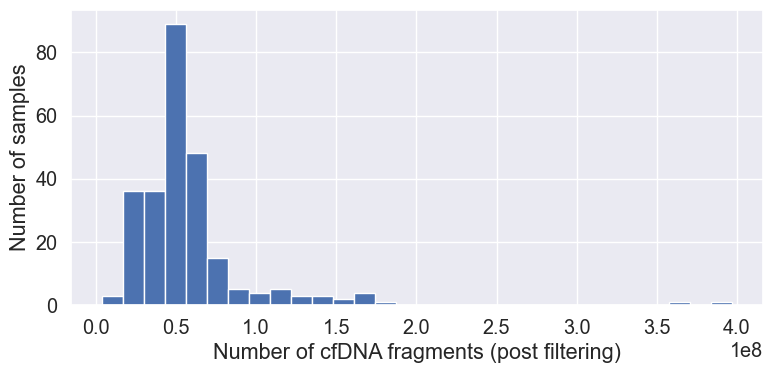

In [16]:
print(np.min(coverage))
plt.figure(figsize=(8, 4))
plt.hist(coverage, bins=30)
plt.xlabel('Number of cfDNA fragments (post filtering)')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'n-fragments-per-sample.png'), dpi=300)
plt.show()

## ichorCNA TF

In [18]:
dataset_colorectal = load_dataset([os.path.join(DATA_PATH, '50kb-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET])
dataset_breast = load_dataset([os.path.join(DATA_PATH, '50kb-noXY', f'{gc_code}.npz') for gc_code in GC_BREAST_DATASET])

Colorectal cancer
SignificanceResult(statistic=np.float64(0.40521810211895687), pvalue=np.float64(7.0487342283508355e-15))


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 66.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 53.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 39.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 16.7% of the points

Breast cancer
SignificanceResult(statistic=np.float64(0.14603111659017604), pvalue=np.float64(0.09226854589442668))


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 19.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 7.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


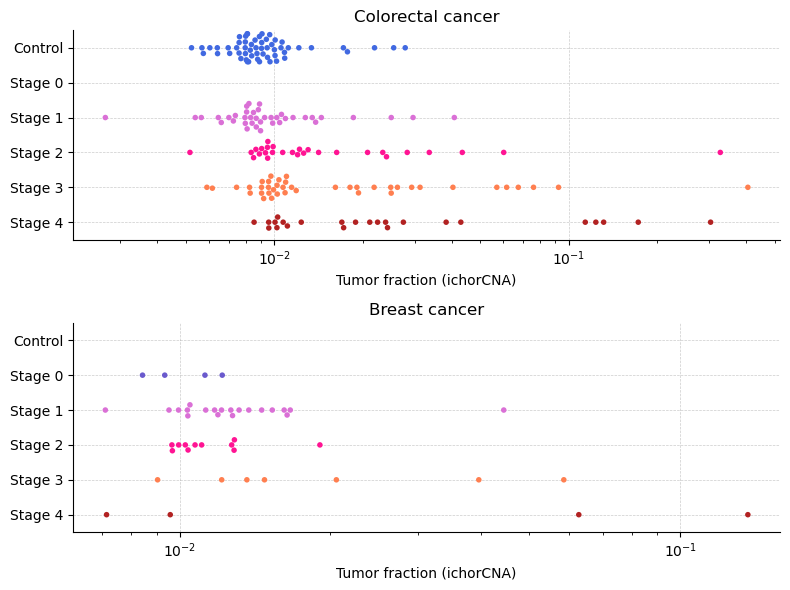

In [19]:
seaborn.reset_orig()
plt.figure(figsize=(8, 6))

for i, (name, dataset, stages) in enumerate(zip(['Colorectal cancer', 'Breast cancer'], [dataset_colorectal, dataset_breast], [(0, 1, 2, 3, 4), (0, 1, 2, 3, 4)])):
    print(name)
    
    dfs = []

    ax = plt.subplot(2, 1, i + 1)

    xs, ys, zs = [], [], []
    for annot, y_pred in zip(dataset.annotations, dataset.ichor):
        grade = float(annot)
        if not annot.is_cancer:
            ys.append('Control')
            xs.append(y_pred)
            zs.append(0)
        else:
            if np.isnan(grade):
                continue
            else:
                ys.append(f'Stage {int(grade)}')
                xs.append(y_pred)
                zs.append(int(grade) + 1)
    xs = np.asarray(xs)
    zs = np.asarray(zs)
    
    mask = ~np.logical_or(np.isnan(xs), np.isnan(zs))
    print(scipy.stats.kendalltau(xs[mask], zs[mask], alternative='greater'))

    tmp_df = pd.DataFrame({
        'stage': ys,
        'score': xs
    })

    seaborn.swarmplot(
        ax=ax, data=tmp_df, x='score', y='stage', hue='stage', size=4,
        order=['Control', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4'],
        palette={'Control': 'royalblue', 'Stage 0': 'slateblue', 'Stage 1': 'orchid', 'Stage 2': 'deeppink', 'Stage 3': 'coral', 'Stage 4': 'firebrick'}
    )
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    ax.set_ylabel('')
    ax.set_xlabel('Tumor fraction (ichorCNA)')
    ax.set_xscale('log')
    #ax.get_legend().remove()
    ax.set_title(f'{name}')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'ichor-stage.png'), dpi=300)
plt.show()

<h1 id="jaggedness">Jaggedness assessment</h1> <a class="anchor" id="jaggedness"></a>

In [113]:
dataset_breast = get_dataset('breast')
dataset_colorectal = get_dataset('colorectal-train')

C:\Users\antoi\AppData\Local\Temp\ipykernel_3064\383499446.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "yo" (-> color='y'). The keyword argument will take precedence.
  ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
C:\Users\antoi\AppData\Local\Temp\ipykernel_3064\383499446.py:33: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "--k" (-> color='k'). The keyword argument will take precedence.
  ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
C:\Users\antoi\AppData\Local\Temp\ipykernel_3064\383499446.py:38: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "yo" (-> color='y'). The keyword argument will take precedence.
  ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', co

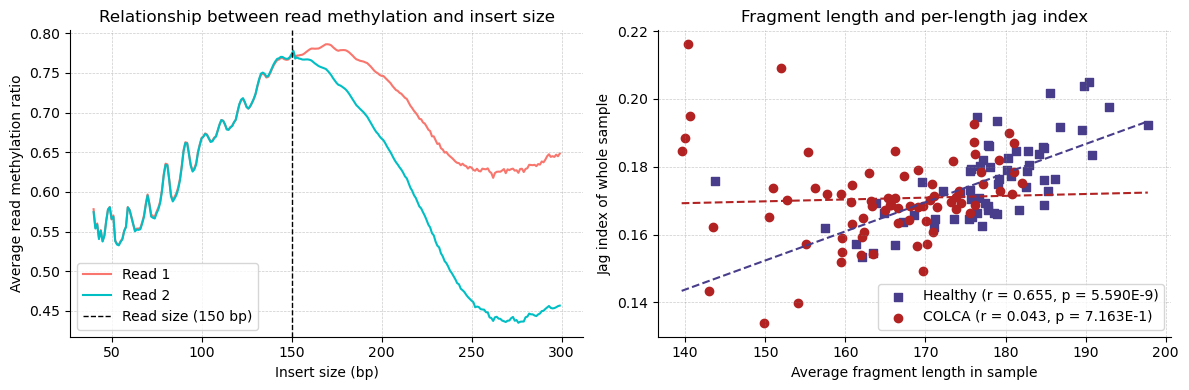

In [114]:
r1_meth = np.mean(dataset_colorectal.data['R1 methylation'][dataset_colorectal.y == 0, :], axis=0)
r2_meth = np.mean(dataset_colorectal.data['R2 methylation'][dataset_colorectal.y == 0, :], axis=0)
r1_meth[:40] = 0
r2_meth[:40] = 0
r1_meth = r1_meth[:300]
r2_meth = r2_meth[:300]

seaborn.reset_orig()
plt.figure(figsize=(12, 4))

ax = plt.subplot(1, 2, 1)
#draw_size_areas(ax, 0.55, textweight='normal')
ax.plot(np.arange(40, len(r1_meth)), r1_meth[40:], label='Read 1', color='#F8766D')
ax.plot(np.arange(40, len(r1_meth)), r2_meth[40:], label='Read 2', color='#00BFC4')
plt.axvline(x=150, linewidth=1, linestyle='--', color='black', label='Read size (150 bp)')
plt.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('Insert size (bp)')
ax.set_ylabel('Average read methylation ratio')
ax.set_title('Relationship between read methylation and insert size')

ax = plt.subplot(1, 2, 2)
jag_col = JaggednessModality.compute_jaggedness(dataset_colorectal.data, method='jag-index')
freqs = dataset_colorectal.data['Fragment length counts'][:, :-1]
freqs = freqs / np.sum(freqs, axis=1)[:, np.newaxis]
fragment_lengths = np.sum(freqs * np.arange(freqs.shape[1])[np.newaxis, :], axis=1)
xs, ys = fragment_lengths, jag_col
y = dataset_colorectal.y
coef = np.polyfit(xs[y == 0], ys[y == 0], 1)
poly1d_fn = np.poly1d(coef)
ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
r, p = scipy.stats.pearsonr(xs[y == 0], ys[y == 0])
ax.scatter(xs[y == 0], ys[y == 0], color='darkslateblue', label=f'Healthy (r = {r:.3f}, p = {decimal.Decimal(p):.3E})', marker='s')
coef = np.polyfit(xs[y == 1], ys[y == 1], 1)
poly1d_fn = np.poly1d(coef)
ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="firebrick")
r, p = scipy.stats.pearsonr(xs[y == 1], ys[y == 1])
ax.scatter(xs[y == 1], ys[y == 1], color='firebrick', label=f'COLCA (r = {r:.3f}, p = {decimal.Decimal(p):.3E})')
ax.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('Average fragment length in sample')
ax.set_ylabel('Jag index of whole sample')
ax.set_title('Fragment length and per-length jag index')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'jaggedness-length.png'), dpi=300)
plt.show()

C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


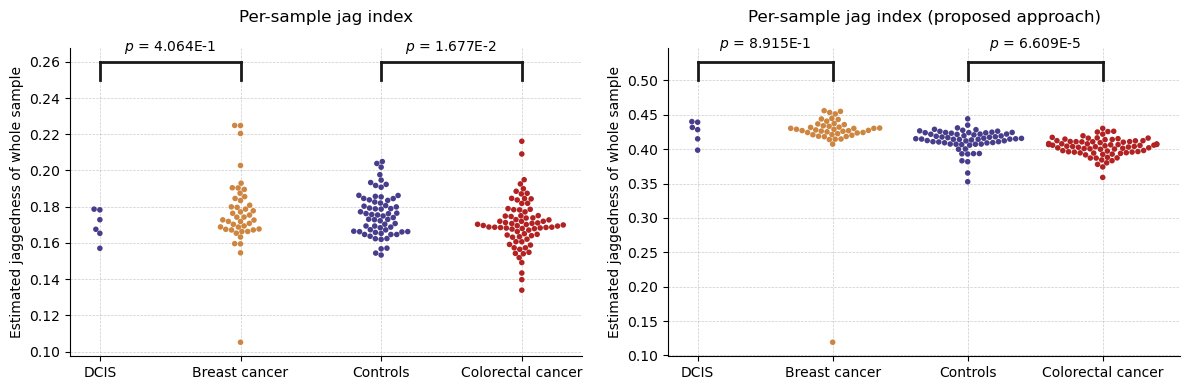

In [115]:
plt.figure(figsize=(12, 4))

for k, method in enumerate(['jag-index', 'corrected']):
    ax = plt.subplot(1, 2, k + 1)
    jag_breast = JaggednessModality.compute_jaggedness(dataset_breast.data, method=method)
    jag_colorectal = JaggednessModality.compute_jaggedness(dataset_colorectal.data, method=method)
    
    xs = ['DCIS'] * len(jag_breast[dataset_breast.y == 0]) + ['Breast cancer'] * len(jag_breast[dataset_breast.y == 1]) + ['Controls'] * len(jag_colorectal[dataset_colorectal.y == 0]) + ['Colorectal cancer'] * len(jag_colorectal[dataset_colorectal.y == 1])
    ys = np.concatenate((jag_breast[dataset_breast.y == 0], jag_breast[dataset_breast.y == 1], jag_colorectal[dataset_colorectal.y == 0], jag_colorectal[dataset_colorectal.y == 1]), axis=0)

    palette = {'DCIS': 'darkslateblue', 'Breast cancer': 'peru', 'Controls': 'darkslateblue', 'Colorectal cancer': 'firebrick'}
    seaborn.swarmplot(ax=ax, x=xs, y=ys, hue=xs, s=4, palette=palette)

    if k == 0:
        lb = 0.25
        text_offset = 0.006
        fork_height = 0.01
        ax.set_ylabel('Estimated jaggedness of whole sample')
        ax.set_title('Per-sample jag index\n')
    else:
        text_offset = 0.02
        lb = 0.5
        fork_height = 0.027
        #ax.set_ylim([0.01, 0.08])
        ax.set_ylabel('Estimated jaggedness of whole sample')
        ax.set_title('Per-sample jag index (proposed approach)\n')
    add_fork(ax, 0, 1, scipy.stats.ttest_ind(jag_breast[dataset_breast.y == 0], jag_breast[dataset_breast.y == 1]).pvalue, lb, fork_height, text_offset=text_offset)
    add_fork(ax, 2, 3, scipy.stats.ttest_ind(jag_colorectal[dataset_colorectal.y == 0], jag_colorectal[dataset_colorectal.y == 1]).pvalue, lb, fork_height, text_offset=text_offset)
    
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'jag-index-alternative.png'), dpi=300)
plt.show()

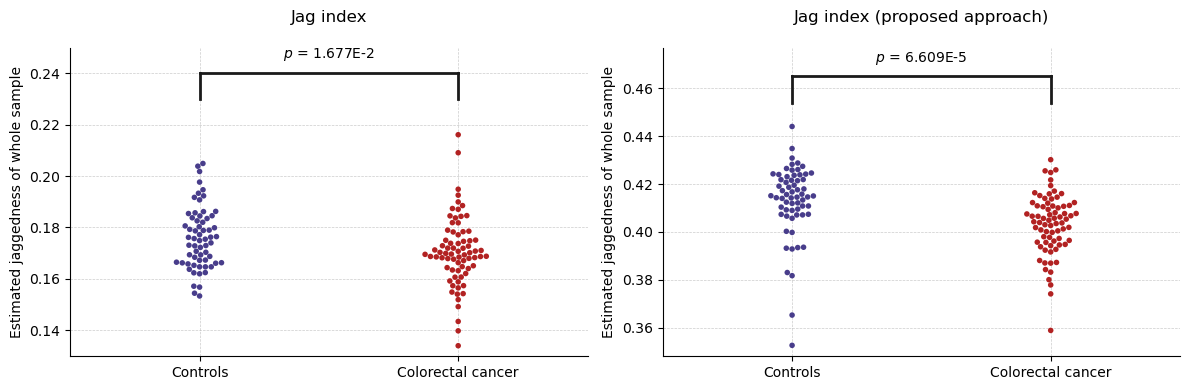

In [53]:
plt.figure(figsize=(12, 4))

for k, method in enumerate(['jag-index', 'corrected']):
    ax = plt.subplot(1, 2, k + 1)
    jag_colorectal = JaggednessModality.compute_jaggedness(dataset_colorectal.data, method=method)
    
    xs = ['Controls'] * len(jag_colorectal[dataset_colorectal.y == 0]) + ['Colorectal cancer'] * len(jag_colorectal[dataset_colorectal.y == 1])
    ys = np.concatenate((jag_colorectal[dataset_colorectal.y == 0], jag_colorectal[dataset_colorectal.y == 1]), axis=0)

    palette = {'DCIS': 'darkslateblue', 'Breast cancer': 'peru', 'Controls': 'darkslateblue', 'Colorectal cancer': 'firebrick'}
    seaborn.swarmplot(ax=ax, x=xs, y=ys, hue=xs, s=4, palette=palette)

    if k == 0:
        lb = 0.23
        text_offset = 0.006
        fork_height = 0.01
        ax.set_ylim([None, 0.25])
        ax.set_ylabel('Estimated jaggedness of whole sample')
        ax.set_title('Jag index\n')
    else:
        text_offset = 0.006
        lb = 0.454
        fork_height = 0.011
        ax.set_ylim([None, 0.477])
        ax.set_ylabel('Estimated jaggedness of whole sample')
        ax.set_title('Jag index (proposed approach)\n')
    add_fork(ax, 0, 1, scipy.stats.ttest_ind(jag_colorectal[dataset_colorectal.y == 0], jag_colorectal[dataset_colorectal.y == 1]).pvalue, lb, fork_height, text_offset=text_offset)
    #add_fork(ax, 0, 1, scipy.stats.ttest_ind(jag_breast[dataset_breast.y == 0], jag_breast[dataset_breast.y == 1]).pvalue, lb, fork_height, text_offset=text_offset)
    ax.set_xlim([-0.5, 1.5])
    
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'jag-index-alternative-colca-only.png'), dpi=300)
plt.show()

In [23]:
dataset_brca = dataset_breast
dataset_colca = dataset_colorectal
dataset_gdna = load_dataset([os.path.join(DATA_PATH, '50kb-noXY', f'{gc_code}.npz') for gc_code in ['GC119439', 'GC119440', 'GC131344', 'GC131345', 'GC131346', 'GC131347', 'GC131348', 'GC131349', 'GC131350', 'GC131351', 'GC131352', 'GC131353', 'GC131354', 'GC131355']])

C:\Users\antoi\AppData\Local\Temp\ipykernel_3448\3029250142.py:19: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_3448\3029250142.py:24: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_3448\3029250142.py:30: RuntimeWarning: divide by zero encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_3448\3029250142.py:30: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth


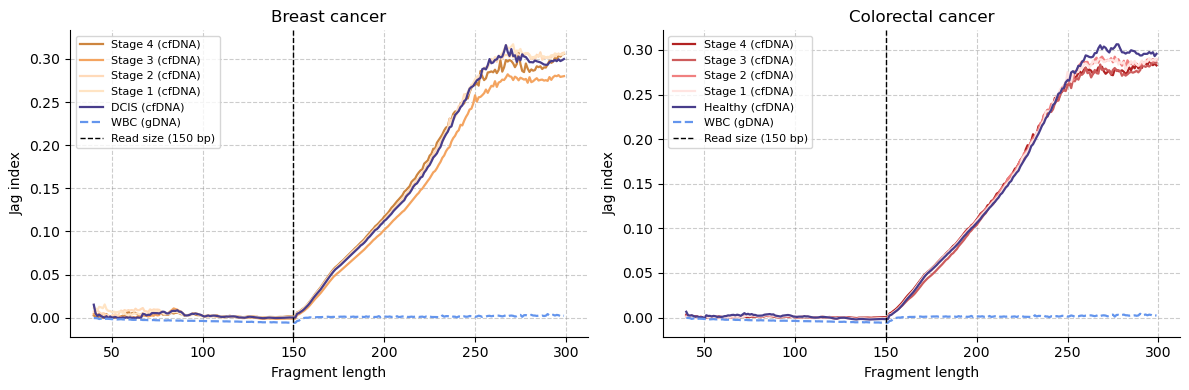

In [33]:
linewidth = 1.6
plt.figure(figsize=(12, 4))
for i, dataset in enumerate([dataset_brca, dataset_colca]):

    ax = plt.subplot(1, 2, i + 1)

    #draw_size_areas(ax, 0.15, textweight='normal')

    if i == 0:
        y = np.asarray([(float(annot) > 0) for annot in dataset.annotations], dtype=int)
    else:
        y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

    colors = ['peru', 'sandybrown', 'peachpuff', 'bisque'] if (i == 0) else ['firebrick', 'indianred', 'lightcoral', 'mistyrose']
    for stage, color in zip([4, 3, 2, 1], colors):
        mask = np.asarray([annot.is_cancer and (float(annot) == stage) for annot in dataset.annotations], dtype=bool)
        r1_meth = np.mean(dataset.data['R1 methylation'][mask], axis=0)[:300]
        r2_meth = np.mean(dataset.data['R2 methylation'][mask], axis=0)[:300]
        jag = (r1_meth - r2_meth) / r1_meth
        ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label=f'Stage {stage} (cfDNA)', color=color)

    r1_meth = np.mean(dataset.data['R1 methylation'][y == 0], axis=0)[:300]
    r2_meth = np.mean(dataset.data['R2 methylation'][y == 0], axis=0)[:300]
    jag = (r1_meth - r2_meth) / r1_meth
    label = 'DCIS (cfDNA)' if (i == 0) else 'Healthy (cfDNA)'
    ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label=label, color='darkslateblue')

    r1_meth = np.mean(dataset_gdna.data['R1 methylation'], axis=0)[:300]
    r2_meth = np.mean(dataset_gdna.data['R2 methylation'], axis=0)[:300]
    jag = (r1_meth - r2_meth) / r1_meth
    ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label='WBC (gDNA)', linestyle='--', color='cornflowerblue')

    ax.axvline(x=150, linewidth=1, label='Read size (150 bp)', linestyle='--', color='black')

    ax.set_title('Breast cancer' if (i == 0) else 'Colorectal cancer')
    ax.set_xlabel('Fragment length')
    ax.set_ylabel('Jag index')
    
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    
    plt.grid(linestyle='--', alpha=0.4, color='gray')
    plt.legend(prop={'size': 8})

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'jag-cancer.png'), dpi=300)
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\1369520547.py:13: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\1369520547.py:17: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\1369520547.py:22: RuntimeWarning: divide by zero encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\1369520547.py:22: RuntimeWarning: invalid value encountered in divide
  jag = (r1_meth - r2_meth) / r1_meth
C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\1369520547.py:42: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "yo" (-> color='y'). The keyword argument will take precedence.
  ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
C:\Users\antoi\AppData\Lo

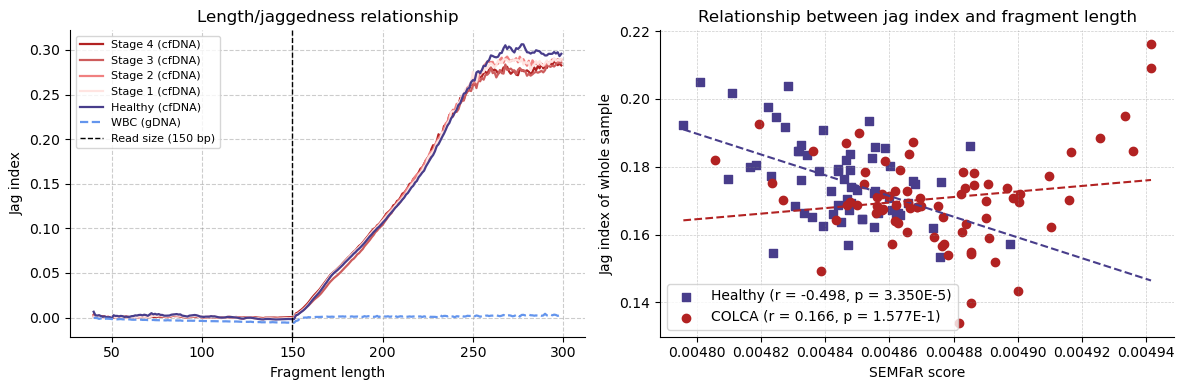

In [78]:
from modalibpy.end_motifs import REFERENCE_GENOME_END_MOTIF_FREQS, compute_f_profiles, semfar_scores

linewidth = 1.6
plt.figure(figsize=(12, 4))

ax = plt.subplot(1, 2, 1)
y = np.asarray([annot.is_cancer for annot in dataset_colca.annotations], dtype=int)
colors = ['firebrick', 'indianred', 'lightcoral', 'mistyrose']
for stage, color in zip([4, 3, 2, 1], colors):
    mask = np.asarray([annot.is_cancer and (float(annot) == stage) for annot in dataset_colca.annotations], dtype=bool)
    r1_meth = np.mean(dataset_colca.data['R1 methylation'][mask], axis=0)[:300]
    r2_meth = np.mean(dataset_colca.data['R2 methylation'][mask], axis=0)[:300]
    jag = (r1_meth - r2_meth) / r1_meth
    ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label=f'Stage {stage} (cfDNA)', color=color)
r1_meth = np.mean(dataset_colca.data['R1 methylation'][y == 0], axis=0)[:300]
r2_meth = np.mean(dataset_colca.data['R2 methylation'][y == 0], axis=0)[:300]
jag = (r1_meth - r2_meth) / r1_meth
label = 'Healthy (cfDNA)'
ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label=label, color='darkslateblue')
r1_meth = np.mean(dataset_gdna.data['R1 methylation'], axis=0)[:300]
r2_meth = np.mean(dataset_gdna.data['R2 methylation'], axis=0)[:300]
jag = (r1_meth - r2_meth) / r1_meth
ax.plot(np.arange(40, len(jag)), jag[40:], linewidth=linewidth, label='WBC (gDNA)', linestyle='--', color='cornflowerblue')
ax.axvline(x=150, linewidth=1, label='Read size (150 bp)', linestyle='--', color='black')
ax.set_title("Length/jaggedness relationship")
ax.set_xlabel('Fragment length')
ax.set_ylabel('Jag index')
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.grid(linestyle='--', alpha=0.4, color='gray')
plt.legend(prop={'size': 8})

ax = plt.subplot(1, 2, 2)
X = dataset_colorectal.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]
semfar = semfar_scores(X)
jag_col = JaggednessModality.compute_jaggedness(dataset_colorectal.data, method='jag-index')
xs, ys = semfar, jag_col
y = dataset_colorectal.y
coef = np.polyfit(xs[y == 0], ys[y == 0], 1)
poly1d_fn = np.poly1d(coef)
ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
r, p = scipy.stats.pearsonr(xs[y == 0], ys[y == 0])
ax.scatter(xs[y == 0], ys[y == 0], color='darkslateblue', label=f'Healthy (r = {r:.3f}, p = {decimal.Decimal(p):.3E})', marker='s')
coef = np.polyfit(xs[y == 1], ys[y == 1], 1)
poly1d_fn = np.poly1d(coef)
ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="firebrick")
r, p = scipy.stats.pearsonr(xs[y == 1], ys[y == 1])
ax.scatter(xs[y == 1], ys[y == 1], color='firebrick', label=f'COLCA (r = {r:.3f}, p = {decimal.Decimal(p):.3E})')
ax.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('SEMFaR score')
ax.set_ylabel('Jag index of whole sample')
ax.set_title('Relationship between jag index and fragment length')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'jag-cancer-colca-only.png'), dpi=300)
plt.show()

<h1 id="ndr">Nucleosome position scoring</h1> <a class="anchor" id="ndr"></a>

In [32]:
dataset = load_dataset([os.path.join(DATA_PATH, 'downsampled-50kb-noXY', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])

hist_all = dataset.data['Fragment length counts'][:, :-1]
hist_all = hist_all / np.sum(hist_all, axis=1)[:, np.newaxis]
hist_all = np.mean(hist_all, axis=0)

nuc_all = dataset.data['Nucleosome score histogram']
nuc_all = nuc_all / np.sum(nuc_all, axis=1)[:, np.newaxis]
nuc_all = np.mean(nuc_all, axis=0)

In [33]:
dataset = load_dataset([os.path.join(DATA_PATH, 'ctcf-noXY', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])

hist_ctcf = dataset.data['Fragment length counts'][:, :-1]
hist_ctcf = hist_ctcf / np.sum(hist_ctcf, axis=1)[:, np.newaxis]
hist_ctcf = np.mean(hist_ctcf, axis=0)

nuc_ctcf = dataset.data['Nucleosome score histogram']
nuc_ctcf = nuc_ctcf / np.sum(nuc_ctcf, axis=1)[:, np.newaxis]
nuc_ctcf = np.mean(nuc_ctcf, axis=0)

In [34]:
dataset = load_dataset([os.path.join(DATA_PATH, 'tss-noXY', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])

hist_tss = dataset.data['Fragment length counts'][:, :-1]
hist_tss = hist_tss / np.sum(hist_tss, axis=1)[:, np.newaxis]
hist_tss = np.mean(hist_tss, axis=0)

nuc_tss = dataset.data['Nucleosome score histogram']
nuc_tss = nuc_tss / np.sum(nuc_tss, axis=1)[:, np.newaxis]
nuc_tss = np.mean(nuc_tss, axis=0)

In [35]:
dataset = load_dataset([os.path.join(DATA_PATH, 'genebodies-noXY', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])

hist_genebodies = dataset.data['Fragment length counts'][:, :-1]
hist_genebodies = hist_genebodies / np.sum(hist_genebodies, axis=1)[:, np.newaxis]
hist_genebodies = np.mean(hist_genebodies, axis=0)

nuc_genebodies = dataset.data['Nucleosome score histogram']
nuc_genebodies = nuc_genebodies / np.sum(nuc_genebodies, axis=1)[:, np.newaxis]
nuc_genebodies = np.mean(nuc_genebodies, axis=0)

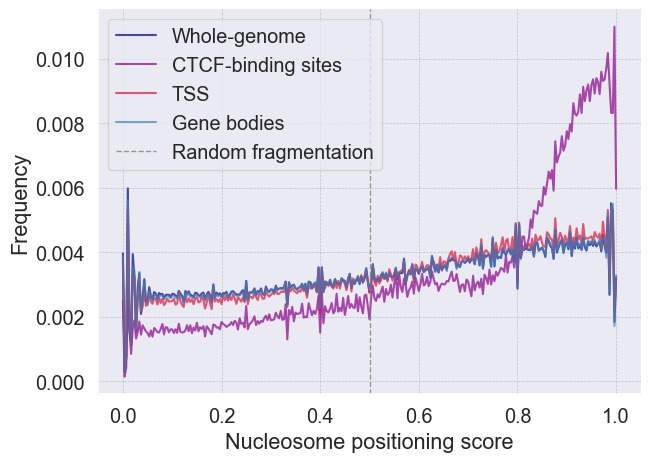

Average nucleosome positioning score for whole-genome:  0.5485488190795674
Average nucleosome positioning score for gene bodies :  0.551223131593962
Average nucleosome positioning score for TSSs        :  0.5615542877514803
Average nucleosome positioning score for CTCF sites  :  0.6605910673810164


In [36]:
colors = ['darkblue', 'darkmagenta', 'crimson', 'darkcyan', 'steelblue']

xs = np.linspace(0, 1, len(nuc_all))

plt.figure(figsize=(7, 5))
ax = plt.subplot(1, 1, 1)
kwargs = {'alpha': 0.7, 'linewidth': 1.5}
ax.plot(xs, nuc_all, color=colors[0], label='Whole-genome', **kwargs)
ax.plot(xs, nuc_ctcf, color=colors[1], label='CTCF-binding sites', **kwargs)
ax.plot(xs, nuc_tss, color=colors[2], label='TSS', **kwargs)
ax.plot(xs, nuc_genebodies, color=colors[4], label='Gene bodies', **kwargs)
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.axvline(x=0.5, linestyle='--', linewidth=1, color='grey', alpha=0.8, label='Random fragmentation')
ax.set_xlabel('Nucleosome positioning score')
ax.set_ylabel('Frequency')
ax.legend()
plt.savefig(os.path.join(FIGURES_PATH, 'ctcf-nucleosome-scores.png'), dpi=300)
plt.show()

print('Average nucleosome positioning score for whole-genome: ', np.sum(xs * nuc_all))
print('Average nucleosome positioning score for gene bodies : ', np.sum(xs * nuc_genebodies))
print('Average nucleosome positioning score for TSSs        : ', np.sum(xs * nuc_tss))
print('Average nucleosome positioning score for CTCF sites  : ', np.sum(xs * nuc_ctcf))

BRCA TtestResult(statistic=-2.1246829961383322, pvalue=0.038901191310778925, df=47.0)
COLCA TtestResult(statistic=-6.910153914010812, pvalue=1.7417355000374558e-10, df=135.0)


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 8.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


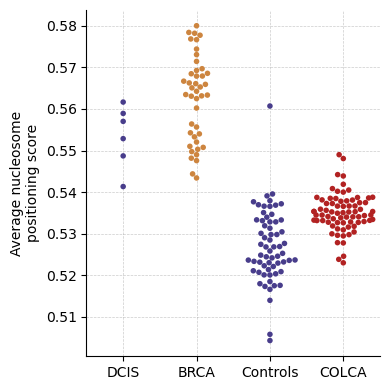

BRCA TtestResult(statistic=1.6581466153372295, pvalue=0.10394830721122376, df=47.0)
COLCA TtestResult(statistic=6.743397225095508, pvalue=4.130272632891167e-10, df=135.0)


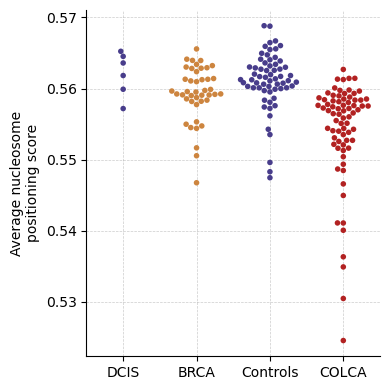

BRCA TtestResult(statistic=1.5247893751769417, pvalue=0.13401303579014961, df=47.0)
COLCA TtestResult(statistic=7.040333883150257, pvalue=8.81954113874422e-11, df=135.0)


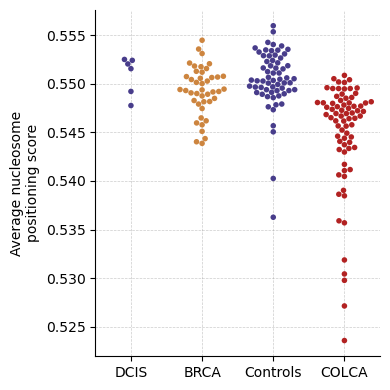

In [40]:
seaborn.reset_orig()

for subfolder in ['ctcf-noXY', 'promoters-noXY', '50kb-noXY']:
    
    dataset_breast = load_dataset([os.path.join(DATA_PATH, subfolder, f'{gc_code}.npz') for gc_code in GC_BREAST_CANCERS])
    dataset_breast.y = np.asarray([float(annot) > 0 for annot in dataset_breast.annotations], dtype=int)
    dataset_colorectal = load_dataset([os.path.join(DATA_PATH, subfolder, f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
    dataset_colorectal.y = np.asarray([annot.is_cancer for annot in dataset_colorectal.annotations], dtype=int)
    
    plt.figure(figsize=(4, 4))
    
    ax = plt.subplot(1, 1, 1)
    nuc_breast = np.mean(dataset_breast.data['Nucleosome positioning'], axis=1)
    nuc_colorectal = np.mean(dataset_colorectal.data['Nucleosome positioning'], axis=1)
    
    xs = ['DCIS'] * len(nuc_breast[dataset_breast.y == 0]) + ['BRCA'] * len(nuc_breast[dataset_breast.y == 1]) + ['Controls'] * len(nuc_colorectal[dataset_colorectal.y == 0]) + ['COLCA'] * len(nuc_colorectal[dataset_colorectal.y == 1])
    ys = np.concatenate((nuc_breast[dataset_breast.y == 0], nuc_breast[dataset_breast.y == 1], nuc_colorectal[dataset_colorectal.y == 0], nuc_colorectal[dataset_colorectal.y == 1]), axis=0)
    
    print('BRCA', scipy.stats.ttest_ind(nuc_breast[dataset_breast.y == 0], nuc_breast[dataset_breast.y == 1]))
    print('COLCA', scipy.stats.ttest_ind(nuc_colorectal[dataset_colorectal.y == 0], nuc_colorectal[dataset_colorectal.y == 1]))
    
    palette = {'DCIS': 'darkslateblue', 'BRCA': 'peru', 'Controls': 'darkslateblue', 'COLCA': 'firebrick'}
    seaborn.swarmplot(ax=ax, x=xs, y=ys, hue=xs, s=4, palette=palette)
    
    ax.set_ylabel('Average nucleosome\npositioning score')
    
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_PATH, f'nuc-scores-{subfolder}.png'), dpi=300)
    
    plt.show()

COLCA TtestResult(statistic=np.float64(-6.910153914010812), pvalue=np.float64(1.7417355000374558e-10), df=np.float64(135.0))


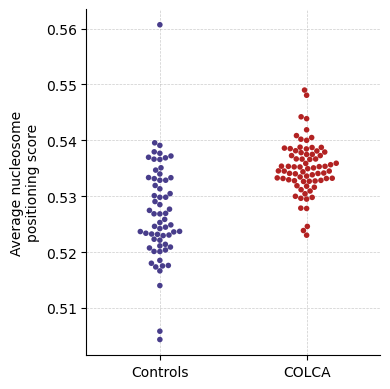

COLCA TtestResult(statistic=np.float64(6.743397225095508), pvalue=np.float64(4.130272632891167e-10), df=np.float64(135.0))


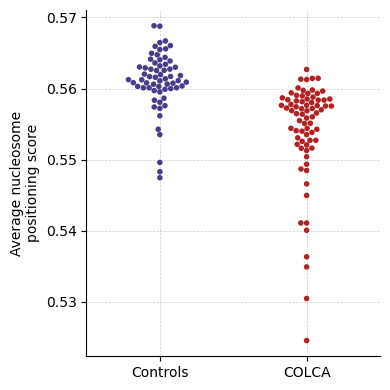

COLCA TtestResult(statistic=np.float64(7.040333883150257), pvalue=np.float64(8.81954113874422e-11), df=np.float64(135.0))


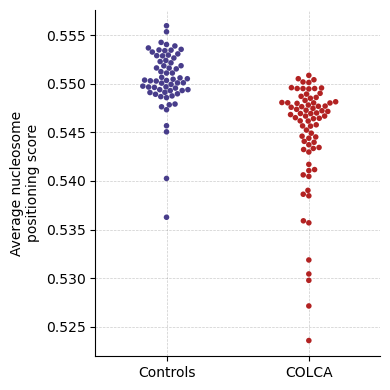

In [81]:
seaborn.reset_orig()

for subfolder in ['ctcf-noXY', 'promoters-noXY', '50kb-noXY']:

    dataset_colorectal = load_dataset([os.path.join(DATA_PATH, subfolder, f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
    dataset_colorectal.y = np.asarray([annot.is_cancer for annot in dataset_colorectal.annotations], dtype=int)
    
    plt.figure(figsize=(4, 4))
    
    ax = plt.subplot(1, 1, 1)
    nuc_breast = np.mean(dataset_breast.data['Nucleosome positioning'], axis=1)
    nuc_colorectal = np.mean(dataset_colorectal.data['Nucleosome positioning'], axis=1)
    
    xs = ['Controls'] * len(nuc_colorectal[dataset_colorectal.y == 0]) + ['COLCA'] * len(nuc_colorectal[dataset_colorectal.y == 1])
    ys = np.concatenate((nuc_colorectal[dataset_colorectal.y == 0], nuc_colorectal[dataset_colorectal.y == 1]), axis=0)
    
    print('COLCA', scipy.stats.ttest_ind(nuc_colorectal[dataset_colorectal.y == 0], nuc_colorectal[dataset_colorectal.y == 1]))
    
    palette = {'Controls': 'darkslateblue', 'COLCA': 'firebrick'}
    seaborn.swarmplot(ax=ax, x=xs, y=ys, hue=xs, s=4, palette=palette)
    
    ax.set_ylabel('Average nucleosome\npositioning score')
    
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_PATH, f'nuc-scores-{subfolder}-colca-only.png'), dpi=300)
    
    plt.show()

<h1 id="ndr">Fragment lengths</h1>

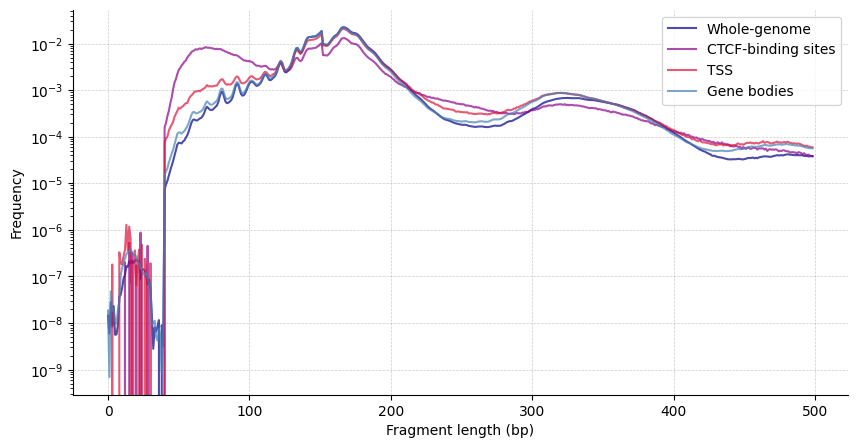

In [376]:
colors = ['darkblue', 'darkmagenta', 'crimson', 'darkcyan', 'steelblue']
linestyles = ['-', '-', '-', '-', '-']

alpha = 0.7
linewidth = 1.5
plt.figure(figsize=(10, 5))
ax = plt.subplot(1, 1, 1)
ax.plot(hist_all, label='Whole-genome', color=colors[0], alpha=alpha, linestyle=linestyles[0], linewidth=linewidth)
ax.plot(hist_ctcf, label='CTCF-binding sites', color=colors[1], linestyle=linestyles[1], alpha=alpha, linewidth=linewidth)
ax.plot(hist_tss, label='TSS', color=colors[2], linestyle=linestyles[2], alpha=alpha, linewidth=linewidth)
ax.plot(hist_genebodies, label='Gene bodies', color=colors[4], linestyle=linestyles[4], alpha=alpha, linewidth=linewidth)
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.legend()
ax.set_yscale('log')
ax.set_xlabel('Fragment length (bp)')
ax.set_ylabel('Frequency')
plt.savefig(os.path.join(FIGURES_PATH, 'fragment-lengths-log-scale.png'), dpi=300)
plt.show()

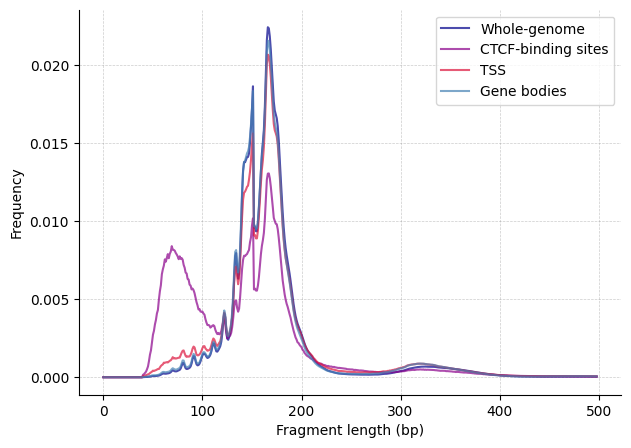

In [379]:
alpha = 0.7
linewidth = 1.5
plt.figure(figsize=(7, 5))
ax = plt.subplot(1, 1, 1)
ax.plot(hist_all, label='Whole-genome', color=colors[0], linestyle=linestyles[0], alpha=alpha, linewidth=linewidth)
ax.plot(hist_ctcf, label='CTCF-binding sites', color=colors[1], linestyle=linestyles[1], alpha=alpha, linewidth=linewidth)
ax.plot(hist_tss, label='TSS', color=colors[2], linestyle=linestyles[2], alpha=alpha, linewidth=linewidth)
ax.plot(hist_genebodies, label='Gene bodies', color=colors[4], linestyle=linestyles[4], alpha=alpha, linewidth=linewidth)
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.legend()
ax.set_xlabel('Fragment length (bp)')
ax.set_ylabel('Frequency')
plt.savefig(os.path.join(FIGURES_PATH, 'fragment-lengths-linear-scale.png'), dpi=300)
plt.show()

<h1 id="housekeeping-genes">Gene expression</h1> <a class="anchor" id="housekeeping-genes"></a>

In [82]:
filepath = os.path.join(ROOT, 'regions', 'gene-bodies-no-XY.csv')
df = pd.read_csv(filepath, sep=',', names=['chr_id', 'start', 'end', 'gene'])
gene_names = np.asarray(list(df['gene'].to_numpy()), dtype=object)

In [83]:
df = pd.read_csv(os.path.join(ROOT, 'gene-expression/HK_genes.txt'), sep=' \t', header=None)
housekeeping_genes = set([s.strip() for s in df.loc[:, 0].to_numpy()])
print(f'Number of housekeeping genes: {len(housekeeping_genes)}')

df = pd.read_csv(os.path.join(ROOT, 'gene-expression/HV_genes.txt'), sep=' \t', header=None)
hv_genes = set([s.strip() for s in df.loc[:, 0].to_numpy()])
print(f'Number of highly-variable genes: {len(hv_genes)}')

Number of housekeeping genes: 3804
Number of highly-variable genes: 3000


C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\300058885.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(os.path.join(ROOT, 'gene-expression/HK_genes.txt'), sep=' \t', header=None)
C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\300058885.py:5: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(os.path.join(ROOT, 'gene-expression/HV_genes.txt'), sep=' \t', header=None)


In [85]:
dataset_promoters = load_dataset([os.path.join(DATA_PATH, 'promoters-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
dataset_tss = load_dataset([os.path.join(DATA_PATH, 'tss-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
dataset_genes = load_dataset([os.path.join(DATA_PATH, 'genebodies-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])

In [86]:
RE = np.load(os.path.join(ROOT, 'gene-expression/expression-profiles.npz'), allow_pickle=True)
mask = np.asarray([cell_type not in {'Unknown'} for cell_type in RE['cell_types']], dtype=bool)
cell_types = RE['cell_types'][mask]
compartments = RE['compartments'][mask]
tissues = RE['tissues'][mask]
mu = RE['mu'][mask]
RE = GeneExpressionData(mu, RE['gene_symbols'])

Promoters Nucleosome positioning -0.011685150376101032
Promoters CpG Methylation (first moment) 0.10678278133913736
Promoters Proportion of long fragments -0.36619639350023875
TSS Nucleosome positioning 0.026565801545454317
TSS CpG Methylation (first moment) -0.092497965128997
TSS Proportion of long fragments -0.31111045705118107
Gene bodies Nucleosome positioning -0.1044713590921569
Gene bodies CpG Methylation (first moment) 0.04956455417849294
Gene bodies Proportion of long fragments -0.44632303254363437


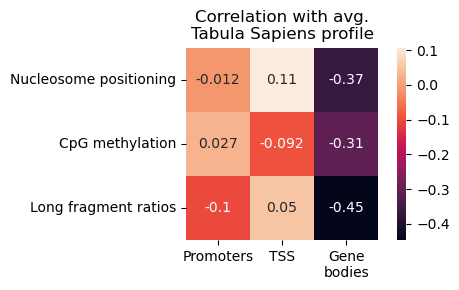

In [87]:
values = np.zeros((3, 3))
for i, (dname, dataset) in enumerate(zip(['Promoters', 'TSS', 'Gene bodies'], [dataset_promoters, dataset_tss, dataset_genes])):
    for j, key in enumerate(['Nucleosome positioning', 'CpG Methylation (first moment)', 'Proportion of long fragments']):
        X = dataset.data[key]
        n = dataset.data['Coverage']
        idx = np.argsort(np.min(n, axis=0))[-5000:]
        XE = GeneExpressionData(X[:, idx], gene_names[idx])
        XE_, RE_ = XE.match(RE)
        values[i, j] = scipy.stats.spearmanr(np.mean(XE_.X, axis=0), np.mean(RE_.X, axis=0)).statistic
        print(dname, key, values[i, j])

plt.figure(figsize=(5, 3))
ax = plt.subplot(1, 1, 1)
seaborn.heatmap(values, ax=ax, square=True, annot=True, xticklabels=['Promoters', 'TSS', 'Gene\nbodies'], yticklabels=['Nucleosome positioning', 'CpG methylation', 'Long fragment ratios'])
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title('Correlation with avg.\nTabula Sapiens profile')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'expression-modality-correlations.png'), dpi=300)
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_17720\3623509050.py:21: RuntimeWarning: divide by zero encountered in log
  ax.scatter(xs, np.log(ys), alpha=0.1, color='darkslateblue')


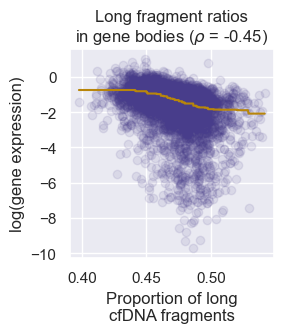

In [88]:
X = dataset_genes.data['Proportion of long fragments']

n = dataset_genes.data['Coverage']
idx = np.argsort(np.min(n, axis=0))[-5000:]
XE = GeneExpressionData(X[:, idx], gene_names[idx])
XE_, RE_ = XE.match(RE)
XE_.X.shape, RE_.X.shape
xs = np.mean(XE_.X, axis=0)
ys = np.mean(RE_.X, axis=0)

rho = scipy.stats.spearmanr(np.mean(XE_.X, axis=0), np.mean(RE_.X, axis=0)).statistic

model = IsotonicRegression(increasing=False)
model.fit(xs, ys)
xs_hat = np.sort(xs)
ys_hat = model.predict(xs_hat)

seaborn.set_theme()
plt.figure(figsize=(3, 3.5))
ax = plt.subplot(1, 1, 1)
ax.scatter(xs, np.log(ys), alpha=0.1, color='darkslateblue')
ax.plot(xs_hat, np.log(ys_hat), color='darkgoldenrod')
ax.set_xlabel('Proportion of long\ncfDNA fragments')
ax.set_ylabel('log(gene expression)')
ax.set_title('Long fragment ratios\nin gene bodies ' + r'($\rho$ = ' + f'{rho:.2f}' + ')')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'ratios-vs-gene-expression-isotonic.png'), dpi=300)
plt.show()

In [89]:
labels = []
for annot in dataset.annotations:
    if not annot.is_cancer:
        labels.append('Healthy')
    elif annot.cancer_type == 'breast':
        labels.append('BRCA')
    elif annot.cancer_type == 'colorectal':
        labels.append('COLCA')
    else:
        assert False
labels = np.asarray(labels, dtype=object)

In [90]:
n = dataset_genes.data['Coverage']
idx = np.argsort(np.min(n, axis=0))[-5000:]

X = dataset_genes.data['Proportion of long fragments']

X = X - np.median(X, axis=1)[:, np.newaxis]

XE = GeneExpressionData(X[:, idx], gene_names[idx])
XE_, RE_ = XE.match(RE)

In [91]:
for gene_name in XE.gene_names:
    if gene_name in {'DNASE1L3', 'DFFB', 'DNASE1'}:
        print(gene_name)
    #if len(gene_name) > 10:
    #    print(gene_name)
#print(XE_.gene_names)

DNASE1L3


In [92]:
from modalibpy.gene_expression.cell_ranking import CellRanking
print(XE_.X.shape, RE_.X.shape)
cell_ranking = CellRanking(XE_.X, labels, RE_.X, cell_types, tissues, compartments)

(137, 4813) (161, 4813)


Cell ranking: 100%|██████████████████████████████████████████████████████████████████| 137/137 [00:24<00:00,  5.49it/s]


In [93]:
from modalibpy.deconvolution.gene_expression import crossdomain_deconvolution
alpha = crossdomain_deconvolution(XE_.X, RE_.X, max_n_iter=1000)

-0.2808436155319214: 100%|█████████████████████████████████████████████████████████| 1000/1000 [00:13<00:00, 76.70it/s]



★
★★★
★★★






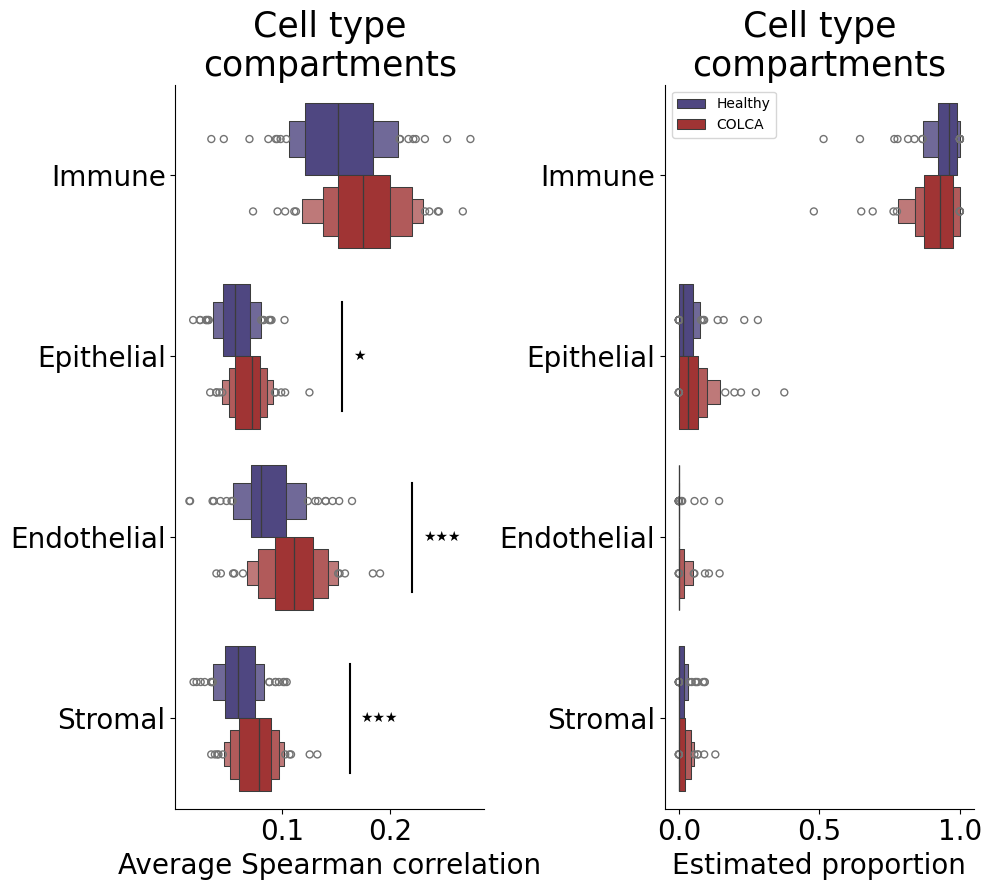

In [106]:
mask_sample = np.asarray([annot.is_cancer for annot in dataset_genes.annotations], dtype=bool)

unique_compartments = ['immune', 'epithelial', 'endothelial', 'stromal']

seaborn.reset_orig()
palette = {'Healthy': 'darkslateblue', 'COLCA': 'firebrick'}
plt.figure(figsize=(10, 9))

for k in range(2):
    ax = plt.subplot(1, 2, k + 1)
    xs, ys, hue = [], [], []
    for j in range(len(unique_compartments)):
        mask = (compartments == unique_compartments[j])
        if k == 0:
            p = np.mean(np.abs(cell_ranking.C[:, mask]), axis=1)
        else:
            p = np.sum(alpha[:, mask], axis=1)
        for i in range(len(alpha)):
            compartment = unique_compartments[j][0].upper() + unique_compartments[j][1:]
            xs.append(p[i])
            ys.append(compartment)
            hue.append(labels[i])

        mask = (labels != 'Healthy')
        p_value = scipy.stats.ttest_ind(p[mask], p[~mask]).pvalue
        if p_value < 1e-6:
            stars = '★★★★'
        elif p_value < 1e-5:
            stars = '★★★'
        elif p_value < 1e-4:
            stars = '★★'
        elif p_value < 1e-3:
            stars = '★'
        else:
            stars = ''
        if k == 0:
            if stars:
                ax.plot([np.max(p) + 0.03, np.max(p) + 0.03], [j - 0.3, j + 0.3], color='black')
            ax.annotate(stars, (np.max(p) + 0.04, j), va='center')
        else:
            if stars:
                ax.plot([np.max(p) + 0.1, np.max(p) + 0.1], [j - 0.3, j + 0.3], color='black')
            ax.annotate(stars, (np.max(p) + 0.14, j), fontweight='bold', va='center')
    
    seaborn.boxenplot(
        x=xs, y=ys, hue=hue, palette=palette, width_method='linear',
        legend=(k == 1),
        ax=ax,
    )
    ax.set_xlabel('Average Spearman correlation' if (k == 0) else 'Estimated proportion', fontsize=20)
    #ax.set_title('Correlation between Tabula Sapiens data\nand long fragment ratios' if (k == 0) else 'Cell type deconvolution')
    ax.set_title('Cell type\ncompartments', fontsize=25)
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=20)
    #ax.tick_params(axis='both', which='minor', labelsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'expression-deconvolution-compartments.png'), dpi=300)
plt.show()

In [99]:
for tissue in list(set(tissues)):
    mask = (tissues == tissue)
    p = np.sum(alpha[:, mask], axis=1)
    print(tissue, np.mean(p))

blood 0.01653846
bladder organ 0.0011835917
cornea 2.6627563e-06
vasculature 3.0199897e-06
kidney 0.0011732653
cardiac atrium 1.6521913e-06
skin of chest 0.011496161
trachea 0.008965543
sclera 0.016052663
lymph node 0.0037295166
thymus 0.15838817
muscle tissue 0.003102982
liver 0.012531156
aorta 0.047498
adipose tissue 0.0014155916
mammary gland 0.0007854754
exocrine pancreas 1.4014697e-06
cardiac ventricle 0.00011868623
rectus abdominis muscle 0.002749101
prostate gland 0.012871337
spleen 0.3169312
myometrium 1.3976569e-06
muscle of pelvic diaphragm 0.0052273497
small intestine 0.012213455
posterior part of tongue 0.002685946
sublingual gland 0.00017945097
endocrine pancreas 0.012796602
lung 0.034945305
bone marrow 0.22295591
eye 0.00083093805
inguinal lymph node 0.08588552
large intestine 0.0047724126
uterus 0.0010028658
retinal neural layer 0.00096322387


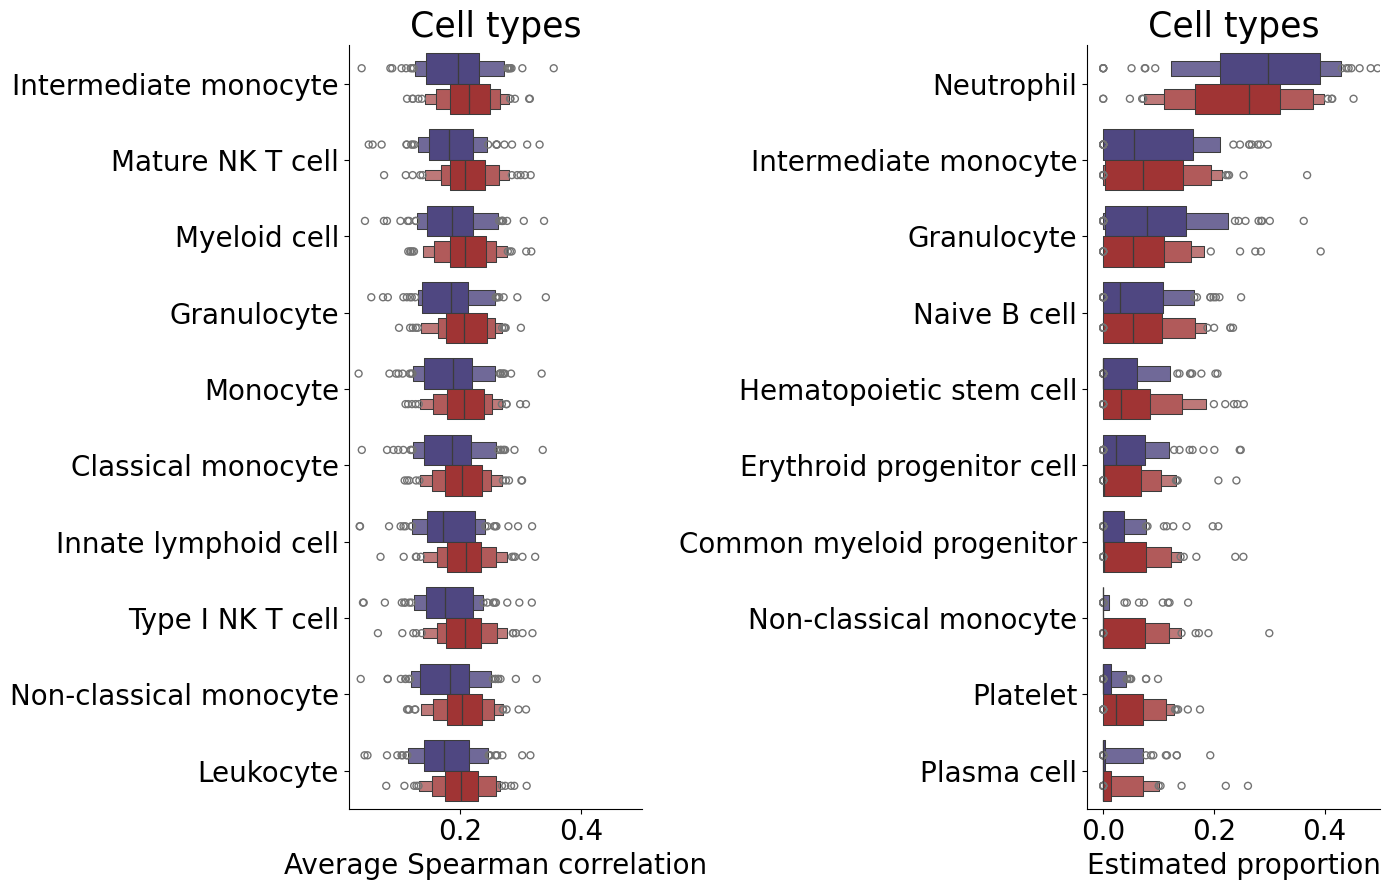

In [109]:
palette = {'Healthy': 'darkslateblue', 'COLCA': 'firebrick'}
plt.figure(figsize=(14, 9))
for k in range(2):
    ax = plt.subplot(1, 2, k + 1)

    if k == 1:
        proportions = np.mean(alpha, axis=0)
    else:
        proportions = np.mean(np.abs(cell_ranking.C), axis=0)
    idx = np.argsort(proportions)[::-1]
    
    xs, ys, hue = [], [], []
    for j2, j in enumerate(idx[:10]):

        if k == 0:
            p = np.abs(cell_ranking.C[:, j])
        else:
            p = alpha[:, j]
        
        for i in range(len(alpha)):
            cell_type = cell_types[j][0].upper() + cell_types[j][1:]
            xs.append(p[i])
            ys.append(cell_type)
            hue.append(labels[i])

        mask = (labels != 'Healthy')
        p_value = scipy.stats.ttest_ind(p[mask], p[~mask]).pvalue
        if p_value < 1e-6:
            stars = '★★★★'
        elif p_value < 1e-5:
            stars = '★★★'
        elif p_value < 1e-4:
            stars = '★★'
        elif p_value < 1e-3:
            stars = '★'
        else:
            stars = ''
        if k == 0:
            if stars:
                ax.plot([np.max(p) + 0.03, np.max(p) + 0.03], [j - 0.3, j + 0.3], color='black')
            ax.annotate(stars, (np.max(p) + 0.04, j), va='center')
        else:
            if stars:
                ax.plot([np.max(p) + 0.1, np.max(p) + 0.1], [j - 0.3, j + 0.3], color='black')
            ax.annotate(stars, (np.max(p) + 0.14, j), fontweight='bold', va='center')

    seaborn.boxenplot(
        x=xs, y=ys, hue=hue, palette=palette, width_method='linear',
        #legend=(k == 1),
        legend=False,
        ax=ax,
    )
    ax.set_xlim([None, 0.5])
    ax.set_xlabel('Average Spearman correlation' if (k == 0) else 'Estimated proportion', fontsize=20)
    #ax.set_title('Correlation between Tabula Sapiens data\nand long fragment ratios' if (k == 0) else 'Cell type deconvolution', fontsize=25)
    ax.set_title('Cell types', fontsize=25)
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=20)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'expression-deconvolution.png'), dpi=300)
plt.show()

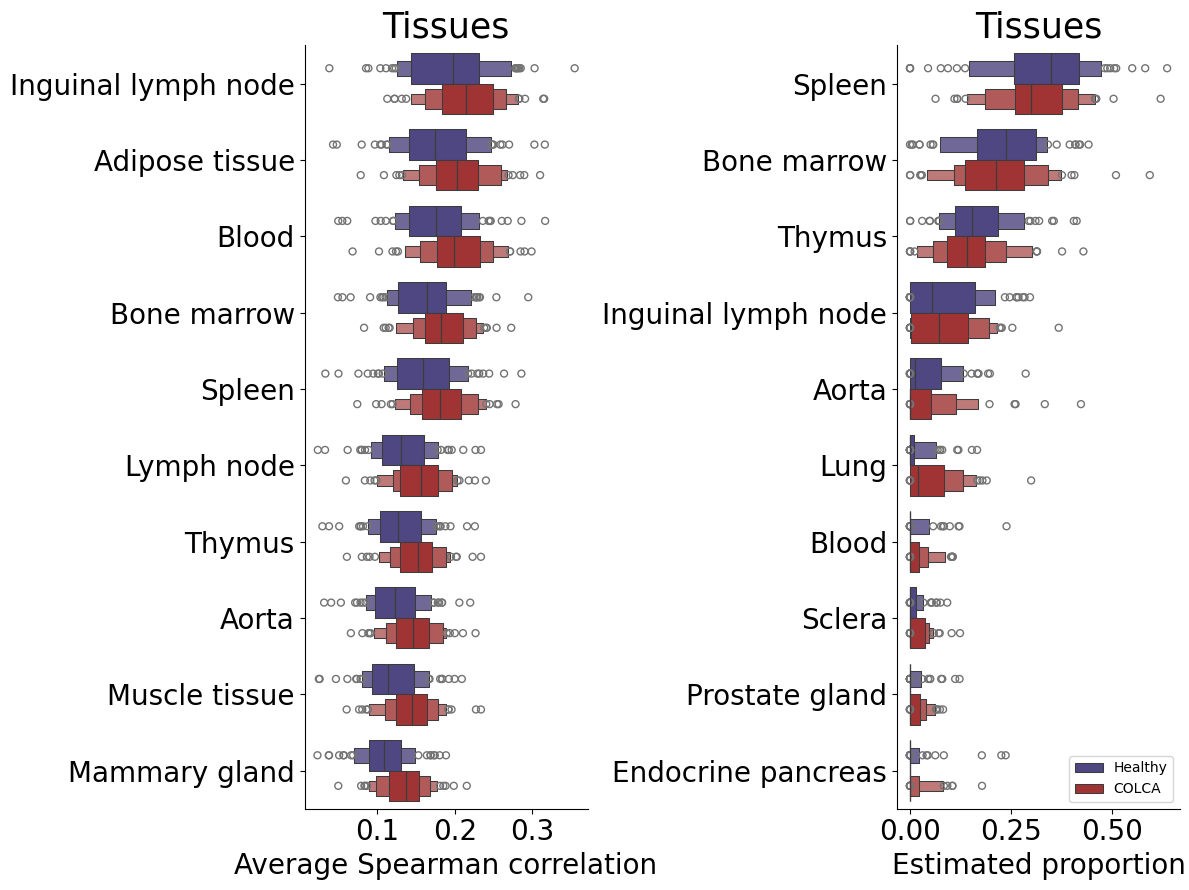

In [102]:
mask_sample = np.asarray([annot.is_cancer for annot in dataset_genes.annotations], dtype=bool)

palette = {'Healthy': 'darkslateblue', 'COLCA': 'firebrick'}
plt.figure(figsize=(12, 9))

for k in range(2):

    values = []
    unique_tissues_ = list(set(tissues))
    for j in range(len(unique_tissues_)):
        mask = (tissues == unique_tissues_[j])
        if k == 0:
            p = np.mean(np.abs(cell_ranking.C[:, mask]), axis=1)
        else:
            p = np.sum(alpha[:, mask], axis=1)
        values.append(np.mean(p))
    idx = np.argsort(values)[::-1][:10]
    unique_tissues = [unique_tissues_[j] for j in idx]
    
    ax = plt.subplot(1, 2, k + 1)
    xs, ys, hue = [], [], []
    for j in range(len(unique_tissues)):
        mask = (tissues == unique_tissues[j])
        if k == 0:
            p = np.mean(np.abs(cell_ranking.C[:, mask]), axis=1)
        else:
            p = np.sum(alpha[:, mask], axis=1)
        for i in range(len(alpha)):
            tissue = unique_tissues[j][0].upper() + unique_tissues[j][1:]
            xs.append(p[i])
            ys.append(tissue)
            hue.append(labels[i])

        mask = (labels != 'Healthy')
        p_value = scipy.stats.ttest_ind(p[mask], p[~mask]).pvalue
        if p_value < 1e-6:
            stars = '★★★★'
        elif p_value < 1e-5:
            stars = '★★★'
        elif p_value < 1e-4:
            stars = '★★'
        elif p_value < 1e-3:
            stars = '★'
        else:
            stars = ''
        #if k == 0:
        #    if stars:
        #        ax.plot([np.max(p) + 0.03, np.max(p) + 0.03], [j - 0.3, j + 0.3], color='black')
        #    ax.annotate(stars, (np.max(p) + 0.04, j), va='center')
        #else:
        #    if stars:
        #        ax.plot([np.max(p) + 0.05, np.max(p) + 0.05], [j - 0.3, j + 0.3], color='black')
        #    ax.annotate(stars, (np.max(p) + 0.08, j), fontweight='bold', va='center')
    
    seaborn.boxenplot(
        x=xs, y=ys, hue=hue, palette=palette, width_method='linear',
        legend=(k == 1),
        ax=ax,
    )
    ax.set_xlabel('Average Spearman correlation' if (k == 0) else 'Estimated proportion', fontsize=20)
    #ax.set_title('Correlation between Tabula Sapiens data\nand long fragment ratios' if (k == 0) else 'Cell type deconvolution', fontsize=25)
    ax.set_title('Tissues', fontsize=25)
    ax.spines[['right', 'top']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=20)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'expression-deconvolution-tissues.png'), dpi=300)
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


CpG Methylation (first moment) 1.0581411175458962e-39


C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))
C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


Nucleosome positioning 1.619841611299743e-33
Proportion of long fragments 1.015825809951278e-173


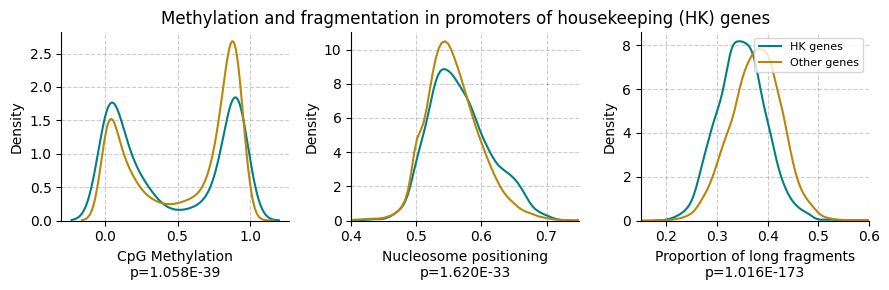

C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


CpG Methylation (first moment) 9.699043415713881e-37


C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


Nucleosome positioning 0.42244788730324445


C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


Proportion of long fragments 5.376672466596791e-23


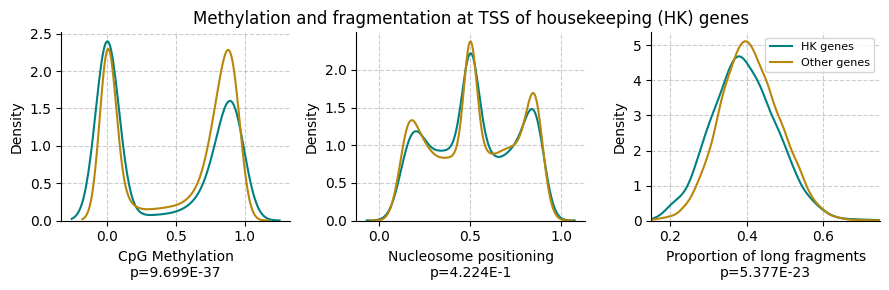

C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


CpG Methylation (first moment) 0.1635938274277522


C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))
C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\1716102508.py:12: RuntimeWarning: invalid value encountered in divide
  x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))


Nucleosome positioning 0.9704648271548498
Proportion of long fragments 1.726295223934422e-167


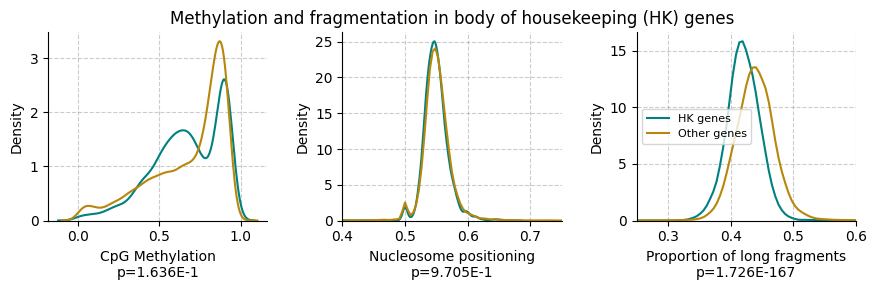

In [403]:
for region_t in ['promoters', 'tss', 'genebodies']:
    dataset_genes = load_dataset([os.path.join(DATA_PATH, f'{region_t}-noXY', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])
    
    seaborn.reset_orig()
    plt.figure(figsize=(9, 3))
    is_housekeeping_gene = np.asarray([(gene_name in housekeeping_genes) for gene_name in gene_names], dtype=bool)
    n = dataset_genes.data['Coverage']
    for k, (xlabel, key, alternative) in enumerate(zip(['CpG Methylation', 'Nucleosome positioning', 'Proportion of long fragments'], ['CpG Methylation (first moment)', 'Nucleosome positioning', 'Proportion of long fragments'], ['less', 'greater', 'less'])):
        ax = plt.subplot(1, 3, k + 1)
        
        X = dataset_genes.data[key]
        x = (np.sum(n * X, axis=0) / np.sum(n, axis=0))
        hk_x = x[is_housekeeping_gene]
        nhk_x = x[~is_housekeeping_gene]
        hk_x, nhk_x = hk_x[~np.isnan(hk_x)], nhk_x[~np.isnan(nhk_x)]
    
        p_value = scipy.stats.ttest_ind(hk_x, nhk_x, alternative=alternative).pvalue
        print(key, p_value)
    
        seaborn.kdeplot(x[is_housekeeping_gene], ax=ax, label='HK genes', color='teal')
        seaborn.kdeplot(x[~is_housekeeping_gene], ax=ax, label='Other genes', color='darkgoldenrod')
    
        ax.spines[['right', 'top']].set_visible(False)
        ax.grid(alpha=0.4, color='grey', linestyle='--')
        ax.set_xlabel(f'{xlabel}\np={decimal.Decimal(p_value):.3E}')
        if k == 1:
            if region_t == 'tss':
                pass #ax.set_xlim([0.4, 0.75])
            else:
                ax.set_xlim([0.4, 0.75])
            if region_t == 'tss':
                ax.set_title('Methylation and fragmentation at TSS of housekeeping (HK) genes')
            elif region_t == 'promoters':
                ax.set_title('Methylation and fragmentation in promoters of housekeeping (HK) genes')
            else:
                ax.set_title('Methylation and fragmentation in body of housekeeping (HK) genes')
        if k == 2:
            if region_t == 'promoters':
                ax.set_xlim([0.15, 0.6])
            elif region_t == 'tss':
                ax.set_xlim([0.15, 0.75])
            else:
                ax.set_xlim([0.25, 0.6])
            ax.legend(prop={'size': 8})
    
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_PATH, f'hk-genes-{region_t}.png'), dpi=300)
    plt.show()

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:34<00:00, 58.21it/s]


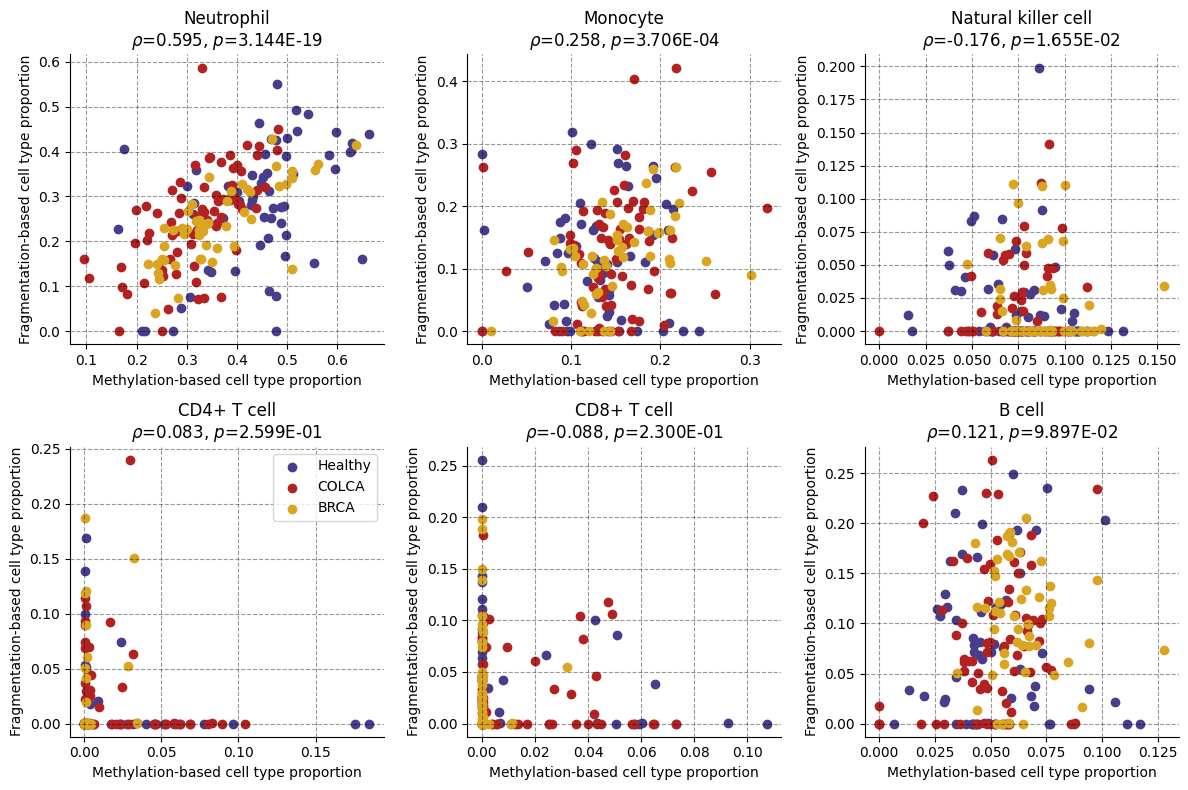

In [494]:
dataset = get_dataset('emseq')

modality = FragCellTypeDeconvolutionModality(use_compartments=False, mod_options={'cache': False, 'probability': True})
modality.process(dataset.data)
modality = MethCellTypeDeconvolutionModality(mod_options={'cache': False, 'probability': True})
modality.process(dataset.data)

settings = [
    (['neutrophil'], ['neutrophil'], 'Neutrophil'),
    (['monocyte'], ['classical monocyte', 'intermediate monocyte', 'monocyte', 'non-classical monocyte'], 'Monocyte'),
    (['naturalkillercell'], ['immature natural killer cell'], 'Natural killer cell'),
    (['cd4tcell'], ['CD4-positive helper T cell', 'CD4-positive, alpha-beta T cell', 'CD4-positive, alpha-beta memory T cell', 'effector CD4-positive, alpha-beta T cell', 'naive thymus-derived CD4-positive, alpha-beta T cell'], 'CD4+ T cell'),
    (['cd8tcell'], ['CD8-positive, alpha-beta T cell', 'CD8-positive, alpha-beta cytokine secreting effector T cell', 'CD8-positive, alpha-beta cytotoxic T cell', 'CD8-positive, alpha-beta memory T cell', 'effector CD8-positive, alpha-beta T cell', 'naive thymus-derived CD8-positive, alpha-beta T cell'], 'CD8+ T cell'),
    (['bcell'], ['B cell', 'memory B cell', 'naive B cell'], 'B cell'),
]

plt.figure(figsize=(12, 8))
for k, setting in enumerate(settings):

    ax = plt.subplot(2, 3, k + 1)

    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.4, linestyle='--', linewidth=0.8, color='black')
    
    xs = np.zeros(len(dataset))
    for key in setting[0]:
        j = np.where(np.asarray(metdecode_cell_types, dtype=object) == key)[0][0]
        xs += dataset.data['Cell type proportions'][:, j]
    
    ys = np.zeros(len(dataset))
    for key in setting[1]:
        j = np.where(np.asarray(dataset.data['Gene-expression-reference-cell-types'], dtype=object) == key)[0][0]
        ys += dataset.data['Frag cell type proportions'][:, j]

    mask = (dataset.y == 0)
    ax.scatter(xs[mask], ys[mask], color='darkslateblue', label='Healthy')
    mask = np.logical_and(dataset.y == 1, [annot.cancer_type == 'colorectal' for annot in dataset.annotations])
    ax.scatter(xs[mask], ys[mask], color='firebrick', label='COLCA')
    mask = np.logical_and(dataset.y == 1, [annot.cancer_type == 'breast' for annot in dataset.annotations])
    ax.scatter(xs[mask], ys[mask], color='goldenrod', label='BRCA')
    
    if k == 3:
        ax.legend()
    
    ax.set_xlabel('Methylation-based cell type proportion')
    ax.set_ylabel('Fragmentation-based cell type proportion')
    res = scipy.stats.spearmanr(xs, ys)
    ax.set_title(setting[2] + '\n' + r'$\rho$=' + f'{res.statistic:.3f}' r', $p$=' + '%.3E' % decimal.Decimal(str(res.pvalue)))
    print()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'meth-vs-frag-deconvolution.png'), dpi=300)
plt.show()

100%|█████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:14<00:00, 136.59it/s]


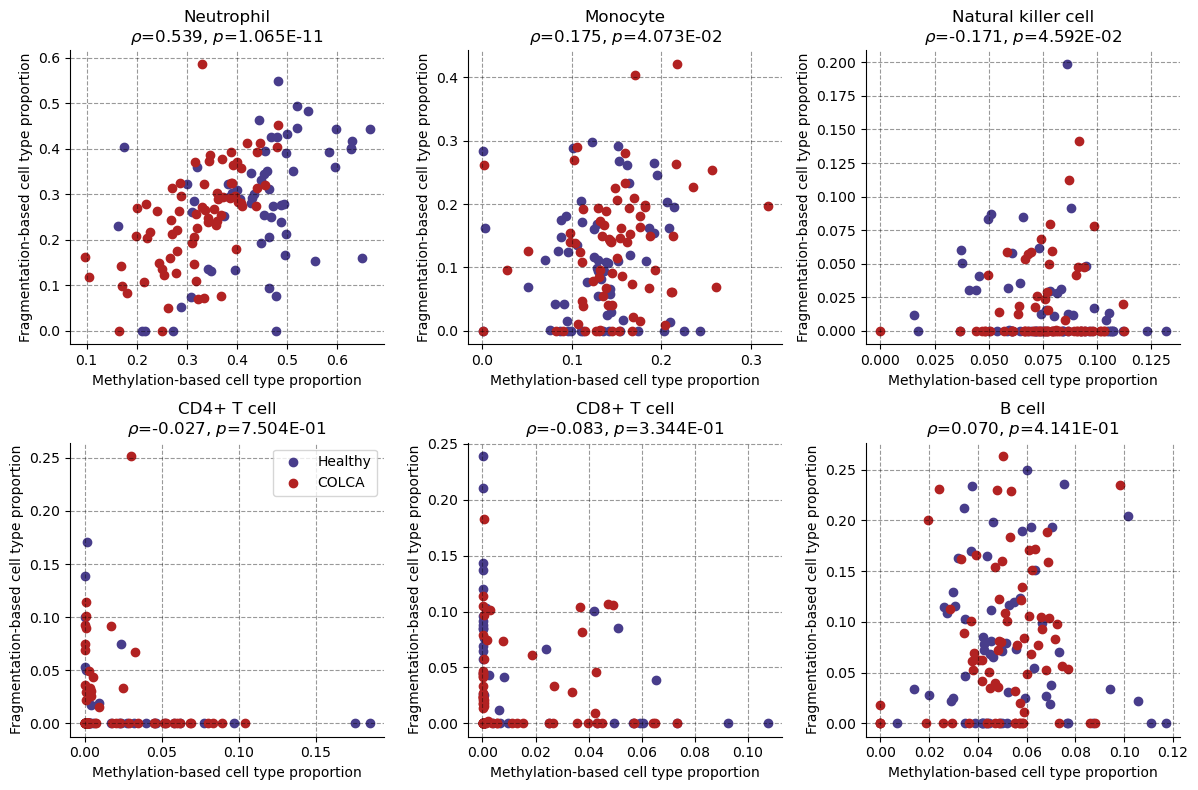

In [110]:
dataset = get_dataset('colorectal-train')

modality = FragCellTypeDeconvolutionModality(use_compartments=False, mod_options={'cache': False, 'probability': True})
modality.process(dataset.data)
modality = MethCellTypeDeconvolutionModality(mod_options={'cache': False, 'probability': True})
modality.process(dataset.data)

settings = [
    (['neutrophil'], ['neutrophil'], 'Neutrophil'),
    (['monocyte'], ['classical monocyte', 'intermediate monocyte', 'monocyte', 'non-classical monocyte'], 'Monocyte'),
    (['naturalkillercell'], ['immature natural killer cell'], 'Natural killer cell'),
    (['cd4tcell'], ['CD4-positive helper T cell', 'CD4-positive, alpha-beta T cell', 'CD4-positive, alpha-beta memory T cell', 'effector CD4-positive, alpha-beta T cell', 'naive thymus-derived CD4-positive, alpha-beta T cell'], 'CD4+ T cell'),
    (['cd8tcell'], ['CD8-positive, alpha-beta T cell', 'CD8-positive, alpha-beta cytokine secreting effector T cell', 'CD8-positive, alpha-beta cytotoxic T cell', 'CD8-positive, alpha-beta memory T cell', 'effector CD8-positive, alpha-beta T cell', 'naive thymus-derived CD8-positive, alpha-beta T cell'], 'CD8+ T cell'),
    (['bcell'], ['B cell', 'memory B cell', 'naive B cell'], 'B cell'),
]

plt.figure(figsize=(12, 8))
for k, setting in enumerate(settings):

    ax = plt.subplot(2, 3, k + 1)

    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.4, linestyle='--', linewidth=0.8, color='black')
    
    xs = np.zeros(len(dataset))
    for key in setting[0]:
        j = np.where(np.asarray(metdecode_cell_types, dtype=object) == key)[0][0]
        xs += dataset.data['Cell type proportions'][:, j]
    
    ys = np.zeros(len(dataset))
    for key in setting[1]:
        j = np.where(np.asarray(dataset.data['Gene-expression-reference-cell-types'], dtype=object) == key)[0][0]
        ys += dataset.data['Frag cell type proportions'][:, j]

    mask = (dataset.y == 0)
    ax.scatter(xs[mask], ys[mask], color='darkslateblue', label='Healthy')
    mask = np.logical_and(dataset.y == 1, [annot.cancer_type == 'colorectal' for annot in dataset.annotations])
    ax.scatter(xs[mask], ys[mask], color='firebrick', label='COLCA')
    
    if k == 3:
        ax.legend()
    
    ax.set_xlabel('Methylation-based cell type proportion')
    ax.set_ylabel('Fragmentation-based cell type proportion')
    res = scipy.stats.spearmanr(xs, ys)
    ax.set_title(setting[2] + '\n' + r'$\rho$=' + f'{res.statistic:.3f}' r', $p$=' + '%.3E' % decimal.Decimal(str(res.pvalue)))
    print()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'meth-vs-frag-deconvolution-colca-only.png'), dpi=300)
plt.show()

<h1 id="cna">Copy number aberrations</h1> <a class="anchor" id="cna"></a>

In [404]:
from modalibpy.modalities.coverage import CoverageModality
from modalibpy.region import Region, Regions
from modalibpy.cna import CoverageData

In [415]:
dataset_name = 'colca'

if dataset_name == 'brca':
    dataset = load_dataset([os.path.join(DATA_PATH, '50kb', f'{gc_code}.npz') for gc_code in GC_BREAST_DATASET])
elif dataset_name == 'colca':
    dataset = load_dataset([os.path.join(DATA_PATH, '50kb', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

In [416]:
X = CoverageModality(use_kernel=False, cache=False).fit_transform(dataset.data)

In [417]:
cd = CoverageData(
    X,
    Regions.load(os.path.join(ROOT, 'regions', 'all-regions.csv')),
    Regions.load_cytobands(os.path.join(EXTERNAL_DATA_PATH, 'cytoband.txt')),
    Regions.load(os.path.join(ROOT, 'regions', 'genebodies.csv'))
)

In [418]:
p_values = []
mat = []
for cytoband in tqdm.tqdm(cd.cytobands):
    mat.append(cd[cytoband.name])
    if dataset_name == 'brca':
        mask = np.asarray([(float(annot) > 0) for annot in dataset.annotations], dtype=bool)
    else:
        mask = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=bool)
    p_values.append(scipy.stats.ttest_ind(mat[-1][~mask], mat[-1][mask]).pvalue)
mat = np.asarray(mat)
scaler = RobustScaler().fit(mat.T)
mat = scaler.transform(mat.T).T

100%|████████████████████████████████████████████████████████████████████████████████| 862/862 [00:12<00:00, 67.74it/s]


In [419]:
best_band_idx = np.argsort(p_values)[:30]
gene_names = set()
for i in best_band_idx:
    cytoband = cd.cytobands[i]
    gene_names.update(cd.get_gene_set(cytoband.name))
print(len(gene_names))

569


In [420]:
chr_regions = [
    # OncoKB
    ('17q12', 'greater', 'ERBB2'),
    ('12q15', 'greater', 'MDM2'),
    ('9p21.3', 'less', 'MTAP'),
    ('19q12', 'greater', 'CCNE1'),
    ('10q26.13', 'greater', 'FGFR2'),
]

In [421]:
mat3 = []
for (cytoband_name, _, _) in chr_regions:
    mat3.append(cd[cytoband_name])
mat3 = np.asarray(mat3)
scaler = RobustScaler().fit(mat3.T)
mat3 = scaler.transform(mat3.T).T

[63, 0, 21, 17, 19, 13]


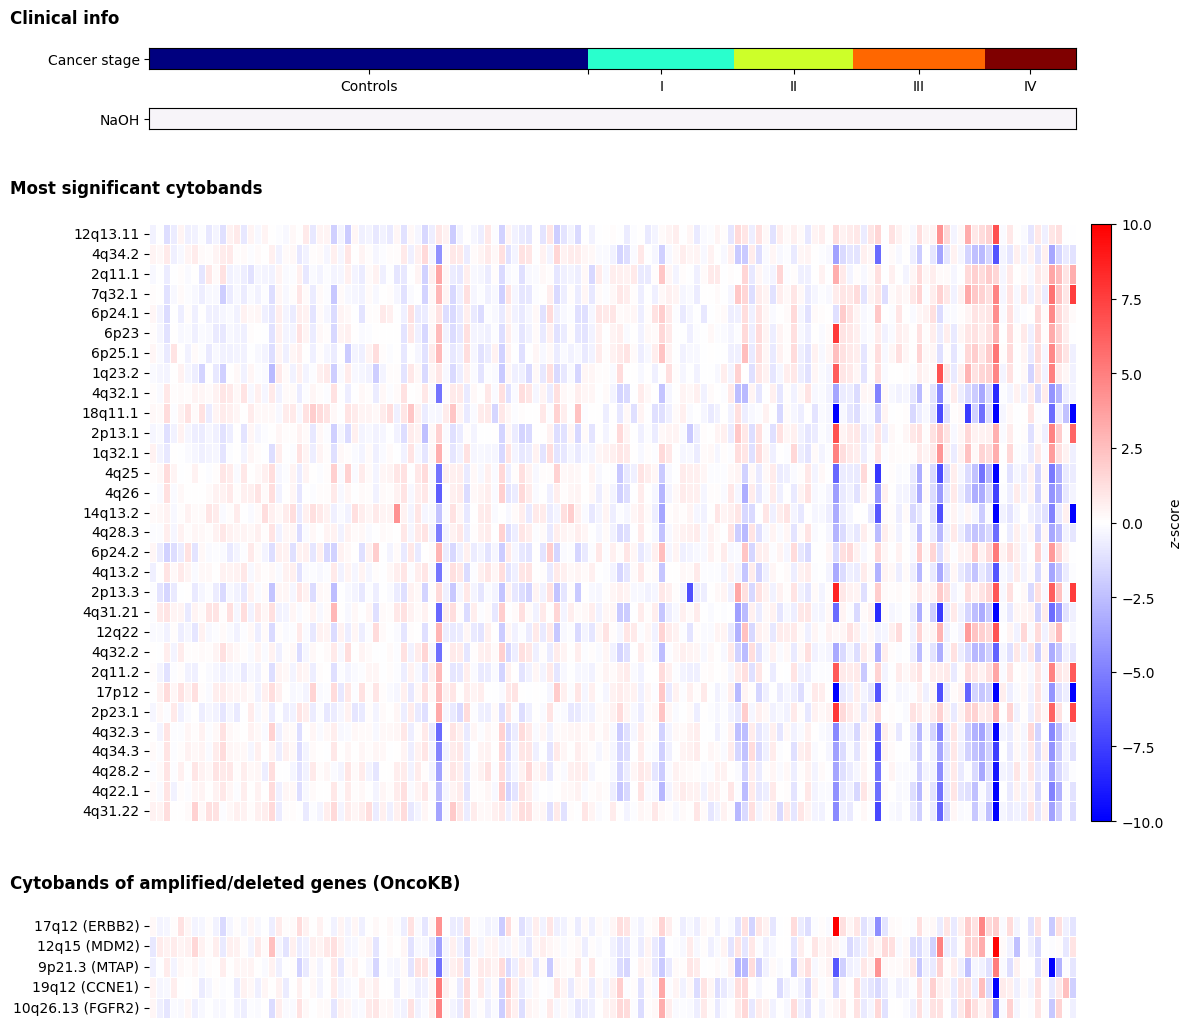

In [422]:
annotations = dataset.annotations
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

idx = []
if dataset_name != 'breast-no-control':
    idx.append(np.where(np.asarray([(not annot.is_cancer) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 0)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 1)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 2)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 3)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 4)) for annot in dataset.annotations], dtype=bool))[0])
#idx.append(np.where(np.asarray([(annot.is_cancer and np.isnan(float(annot))) for annot in dataset.annotations], dtype=bool))[0])
#for i in range(len(idx)):
#    idx_idx = np.argsort(dataset.ichor[idx[i]])
#    idx[i] = idx[i][idx_idx]
lengths = [len(x) for x in idx]
print(lengths)
bounds = np.asarray([0] + list(np.cumsum(lengths)))
idx = np.concatenate(idx, axis=0)

seaborn.reset_orig()
f, axs = plt.subplots(6, 2, height_ratios=(0.25, 0.25, 0.2, 7, 0.2, 1.2), width_ratios=(9, 0.2), figsize=(12, 10))

ax = axs[1, 0]
#ys = np.nan_to_num(dataset.ichor[idx])
ys = np.asarray([isinstance(s, str) and ('NaOH' in s) for s in dataset.notes[idx]])
ax.imshow(ys[np.newaxis, :], aspect='auto', interpolation='none', cmap='PuRd')
ax.set_yticks([0])
#ax.set_yticklabels(['TF (ichorCNA)'])
ax.set_yticklabels(['NaOH'])
ax.set_xticks([])
ax.set_xticklabels([])
if dataset == 'breast-no-control':
    for pos in bounds[1:-1]:
        ax.axvline(pos - 0.5, color='black', linewidth=0.5)

ax = axs[1, 1]
ax.set_axis_off()

ax = axs[0, 0]
ys = np.concatenate([np.asarray([i] * length) for i, length in enumerate(lengths)], axis=0)
ax.imshow(ys[np.newaxis, :], aspect='auto', interpolation='none', cmap='jet')
ax.set_yticks([0])
ax.set_yticklabels(['Cancer stage'])
ax.set_xticks(0.5 * (bounds[1:] + bounds[:-1]) - 0.5)
if dataset_name == 'breast-no-control':
    for pos in bounds[1:-1]:
        ax.axvline(pos - 0.5, color='black', linewidth=0.5)
ax.set_xticklabels([label if (length > 0) else '' for label, length in zip(['Controls', '0', 'I', 'II', 'III', 'IV'], lengths)])

ax = axs[0, 1]
ax.set_axis_off()

ax = axs[2, 0]
ax.set_axis_off()

ax = axs[2, 1]
ax.set_axis_off()

ax = axs[3, 0]
hm = seaborn.heatmap(
    mat[best_band_idx, :][:, idx],
    ax=ax,
    cmap='bwr',
    cbar=False,
    linecolor='white',
    linewidths=0.5,
    vmin=-10,
    vmax=10
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
if dataset == 'breast-no-control':
    for pos in bounds[1:-1]:
        ax.axvline(pos, color='black', linewidth=0.5)
ax.set_yticks(np.arange(len(best_band_idx)) + 0.5)
#ax.set_yticklabels([f'{region} ({gene})' if (gene is not None) else region for (region, alternative, gene) in chr_regions])
ax.set_yticklabels([cd.cytobands[i].name for i in best_band_idx])
ax.set_xticks([])
ax.set_xticklabels([])
#ax.set_xticks(np.arange(mat.shape[1]) + 0.5)
#ax.set_xticklabels(np.arange(mat.shape[1]), fontsize=6)

ax = axs[3, 1]
f.colorbar(
    hm.collections[0],
    cax=ax, orientation='vertical', label=r'$z$-score',
    location='right',
)
#cb = plt.colorbar(im)
#cb.set_label('\nPred. probability')

ax = axs[4, 0]
ax.set_axis_off()

ax = axs[4, 1]
ax.set_axis_off()

ax = axs[5, 0]
hm = seaborn.heatmap(
    mat3[:, idx],
    ax=ax,
    cmap='bwr',
    cbar=False,
    linecolor='white',
    linewidths=0.5,
    vmin=-10,
    vmax=10
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
if dataset == 'breast-no-control':
    for pos in bounds[1:-1]:
        ax.axvline(pos, color='black')
#ax.set_yticks(np.arange(len(best_band_idx)) + 0.5)
#ax.set_yticklabels([f'{region} ({gene})' if (gene is not None) else region for (region, alternative, gene) in chr_regions])
ax.set_yticklabels([f'{cytoband_name} ({gene_name})' for (cytoband_name, _, gene_name) in chr_regions])
ax.set_xticks([])
ax.set_xticklabels([])

ax = axs[5, 1]
ax.set_axis_off()

f.text(0.01, 1.015, 'Clinical info', ha='left', va='center', fontsize=12, fontweight='bold')
f.text(0.01, 0.845, 'Most significant cytobands', ha='left', va='center', fontsize=12, fontweight='bold')
f.text(0.01, 0.15, 'Cytobands of amplified/deleted genes (OncoKB)', ha='left', va='center', fontsize=12, fontweight='bold')

plt.tight_layout()

if dataset_name == 'mm':
    plt.savefig('mm-cnas.png', dpi=300, bbox_inches='tight', pad_inches=0.1)
elif dataset_name == 'brca':
    plt.savefig('breast-cnas.png', dpi=300, bbox_inches='tight', pad_inches=0.1)
else:
    plt.savefig('colorectal-cnas.png', dpi=300, bbox_inches='tight', pad_inches=0.1)

plt.savefig(os.path.join(FIGURES_PATH, f'frequent-cnas.png'), dpi=300)
plt.show()

<h1 id="nucleases">Nuclease activity profiles</h1> <a class="anchor" id="nucleases"></a>

In [14]:
def modality_swarm_plots(data, title, k):
    
    #nuclease_activities = compute_nuclease_activity_profiles(data)
    nuclease_activities = NucleaseActivityEstimator(length_only=False).fit_transform(data)
    
    stages = np.asarray([-1 if (not annot.is_cancer) else float(annot) for annot in dataset.annotations], dtype=float)
    
    for k2 in range(3):
        print(scipy.stats.kendalltau(stages, nuclease_activities[:, k2], nan_policy='omit'))
    
    jag_indexes = compute_jaggedness(data)
    healthy_mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
    stage_0_mask = np.asarray([annot.is_cancer and (float(annot) == 0) for annot in dataset.annotations], dtype=bool)
    stage_1_mask = np.asarray([annot.is_cancer and (float(annot) == 1) for annot in dataset.annotations], dtype=bool)
    stage_2_mask = np.asarray([annot.is_cancer and (float(annot) == 2) for annot in dataset.annotations], dtype=bool)
    stage_3_mask = np.asarray([annot.is_cancer and (float(annot) == 3) for annot in dataset.annotations], dtype=bool)
    stage_4_mask = np.asarray([annot.is_cancer and (float(annot) == 4) for annot in dataset.annotations], dtype=bool)
    
    plt.figure(figsize=(8, 2.5))
    
    ax = plt.subplot(1, 1, 1)
    sp = seaborn.violinplot(
        [nuclease_activities[healthy_mask, k], nuclease_activities[stage_0_mask, k], nuclease_activities[stage_1_mask, k], nuclease_activities[stage_2_mask, k], nuclease_activities[stage_3_mask, k], nuclease_activities[stage_4_mask, k]],
        ax=ax,
        palette=['royalblue', 'slateblue', 'orchid', 'deeppink', 'coral', 'firebrick']
    )
    
    sp.set_xticklabels(['Healthy', 'Stage 0', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4'])
    ax.set_ylabel(f'Relative {["DFFB", "DNASE1", "DNASE1L3"][k]} activity')
    ax.set_title(title)
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
        
    plt.show()

In [15]:
dataset = get_dataset('colorectal-train')

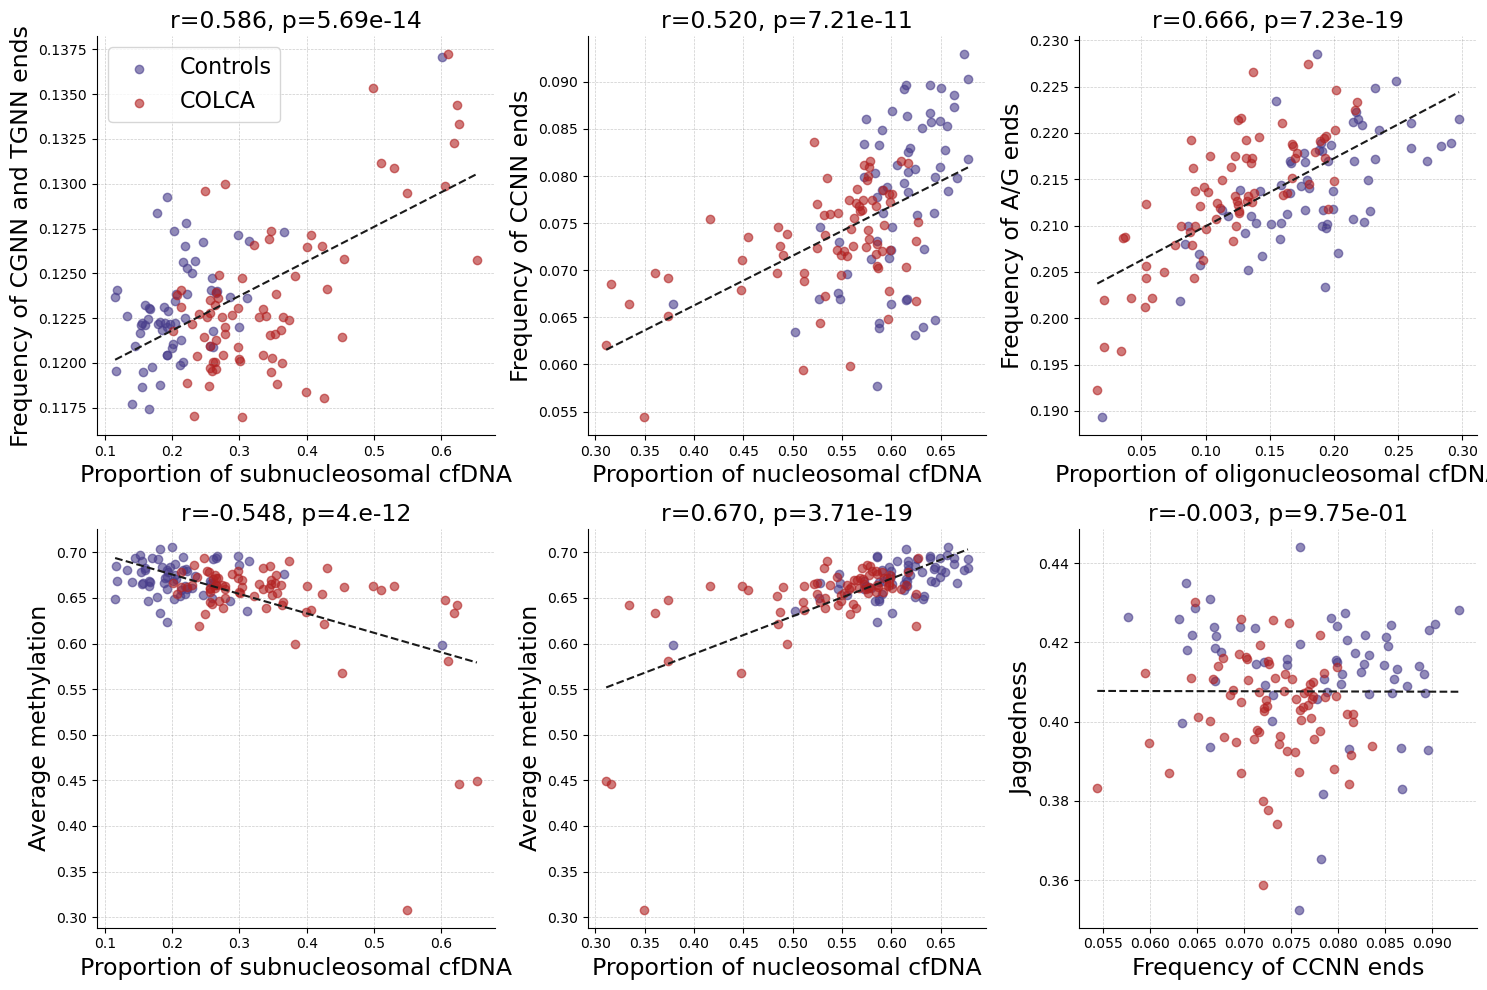

In [16]:
def correlation_plot(ax, xs, ys, y, xlabel, ylabel, legend: bool = False, sep: bool = False):
    mask = np.array([(not annot.is_cancer) for annot in dataset.annotations])
    if sep:
        coef = np.polyfit(xs[mask], ys[mask], 1)
        poly1d_fn = np.poly1d(coef)
        ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="darkslateblue")
        r, p = scipy.stats.pearsonr(xs[mask], ys[mask])
        ax.scatter(xs[mask], ys[mask], color='darkslateblue', label=f'Controls (r = {r:.3f}, p = {decimal.Decimal(p):.3E})')
    else:
        ax.scatter(xs[mask], ys[mask], alpha=0.6, label='Controls', color='darkslateblue')
    
    mask = np.array([(annot.cancer_type == 'colorectal') for annot in dataset.annotations])
    if sep:
        coef = np.polyfit(xs[mask], ys[mask], 1)
        poly1d_fn = np.poly1d(coef)
        ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k', color="firebrick")
        r, p = scipy.stats.pearsonr(xs[mask], ys[mask])
        ax.scatter(xs[mask], ys[mask], color='firebrick', label=f'COLCA (r = {r:.3f}, p = {decimal.Decimal(p):.3E})')
    else:
        ax.scatter(xs[mask], ys[mask], alpha=0.6, label='COLCA', color='firebrick')
    

    if legend:
        ax.legend(prop={'size': 16})

    if not sep:
        coef = np.polyfit(xs, ys, 1)
        poly1d_fn = np.poly1d(coef)
        ax.plot([], [], 'yo', [np.min(xs), np.max(xs)], poly1d_fn([np.min(xs), np.max(xs)]), '--k')
    
    rho, p_value = scipy.stats.pearsonr(xs, ys)
    rho = f'{rho:.3f}'
    p_value = np.format_float_scientific(p_value, precision=2)
    ax.set_title(f'r={rho}, p={p_value}', fontsize=17)
    ax.set_xlabel(xlabel, fontsize=17)
    ax.set_ylabel(ylabel, fontsize=17)
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)


def modality_correlations(data, y, with_brca: bool = True):

    seaborn.reset_orig()
    
    # Modalities (single-valued)
    frag_length_dist = data['Fragment length counts']
    frag_length_dist = frag_length_dist[:, :-1]
    frag_length_dist[:, 40:] /= np.sum(frag_length_dist[:, 40:], axis=1)[:, np.newaxis]
    subnucleosomal = np.sum(frag_length_dist[:, 40:150], axis=1)
    nucleosomal = np.sum(frag_length_dist[:, 150:190], axis=1)
    oligonucleosomal = np.sum(frag_length_dist[:, 190:], axis=1)
    methylation = np.sum(data['CpG Methylation (first moment)'] * data['CpG count'], axis=1) / np.sum(data['CpG count'], axis=1)
    jaggedness = JaggednessModality.compute_jaggedness(data)
    emh = EndMotifHistograms(data['End-motif probability (5 prime)'])

    plt.figure(figsize=(15, 10))
    ax = plt.subplot(2, 3, 1)
    correlation_plot(ax, subnucleosomal, emh['CGNN'] + emh['TGNN'], y, 'Proportion of subnucleosomal cfDNA', 'Frequency of CGNN and TGNN ends', legend=True)
    ax = plt.subplot(2, 3, 2)
    correlation_plot(ax, nucleosomal, emh['CCNN'], y, 'Proportion of nucleosomal cfDNA', 'Frequency of CCNN ends')
    ax = plt.subplot(2, 3, 3)
    correlation_plot(ax, oligonucleosomal, emh['ANNC'] + emh['ANNT'] + emh['GNNC'] + emh['GNNT'], y, 'Proportion of oligonucleosomal cfDNA', 'Frequency of A/G ends')
    #ax.legend()
    
    ax = plt.subplot(2, 3, 4)
    correlation_plot(ax, subnucleosomal, methylation, y, 'Proportion of subnucleosomal cfDNA', 'Average methylation')
    ax = plt.subplot(2, 3, 5)
    correlation_plot(ax, nucleosomal, methylation, y, 'Proportion of nucleosomal cfDNA', 'Average methylation')
    ax = plt.subplot(2, 3, 6)
    correlation_plot(ax, emh['CCNN'], jaggedness, y, 'Frequency of CCNN ends', 'Jaggedness')

    plt.tight_layout()
    if with_brca:
        plt.savefig(os.path.join(FIGURES_PATH, 'modality-correlations.png'), dpi=300)
    else:
        plt.savefig(os.path.join(FIGURES_PATH, 'modality-correlations-colca-only.png'), dpi=300)
    plt.show()


y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)
modality_correlations(dataset.data, y)

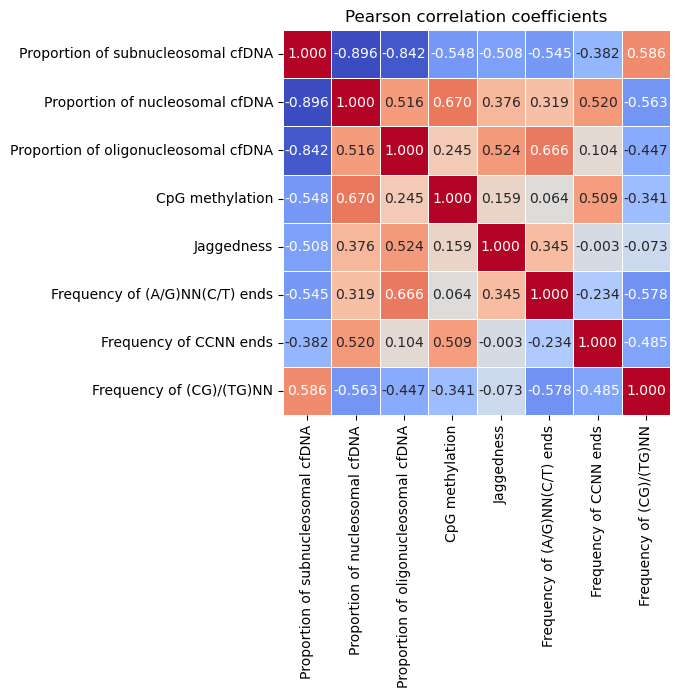

In [17]:
dataset = get_dataset('colorectal-train')
frag_length_dist = dataset.data['Fragment length counts']
frag_length_dist = frag_length_dist[:, :-1]
frag_length_dist[:, 40:] /= np.sum(frag_length_dist[:, 40:], axis=1)[:, np.newaxis]
subnucleosomal = np.sum(frag_length_dist[:, 40:150], axis=1)
nucleosomal = np.sum(frag_length_dist[:, 150:190], axis=1)
oligonucleosomal = np.sum(frag_length_dist[:, 190:], axis=1)
methylation = np.sum(dataset.data['CpG Methylation (first moment)'] * dataset.data['CpG count'], axis=1) / np.sum(dataset.data['CpG count'], axis=1)
jaggedness = JaggednessModality.compute_jaggedness(dataset.data)
emh = EndMotifHistograms(dataset.data['End-motif probability (5 prime)'])
ccnn = emh['CCNN']
cgtgnn = emh['CGNN'] + emh['TGNN']
cgnnct = emh['ANNC'] + emh['ANNT'] + emh['GNNC'] + emh['GNNT']

df = pd.DataFrame({
    'Proportion of subnucleosomal cfDNA': subnucleosomal,
    'Proportion of nucleosomal cfDNA': nucleosomal,
    'Proportion of oligonucleosomal cfDNA': oligonucleosomal,
    'CpG methylation': methylation,
    'Jaggedness': jaggedness,
    'Frequency of (A/G)NN(C/T) ends': cgnnct,
    'Frequency of CCNN ends': ccnn,
    'Frequency of (CG)/(TG)NN': cgtgnn
})

plt.figure(figsize=(5, 5))
plt.title("Pearson correlation coefficients")
seaborn.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5, cbar=False)
plt.show()

In [70]:
filepaths = [os.path.join(DATA_PATH, '50kb-noXY', f'{gc_code}.npz') for gc_code in set(GC_COLORECTAL_DATASET_TRAIN)]
filepaths += [os.path.join(DATA_PATH, 'promoters-noXY', f'{gc_code}.npz') for gc_code in set(GC_COLORECTAL_DATASET_TRAIN)]
dataset = load_dataset(filepaths)

In [86]:
nuclease_activities = NucleaseActivityEstimator(max_n_iter=100000).fit_transform(dataset.data)

-0.7892884612083435:  33%|█████████████████▍                                   | 33012/100000 [01:02<02:07, 525.85it/s]


C:\Users\antoi\anaconda3\Lib\site-packages\ternary\plotting.py:148: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(xs, ys, vmin=vmin, vmax=vmax, **kwargs)


TtestResult(statistic=np.float64(-1.8223944802359908), pvalue=np.float64(0.9647040280755335), df=np.int64(136))


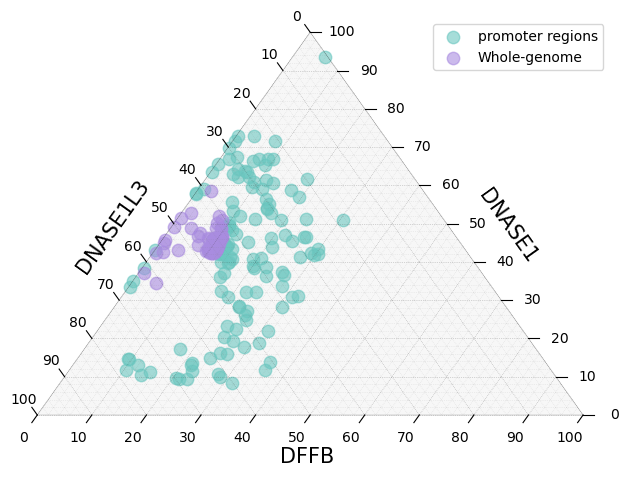

In [87]:
import ternary
figure, tax = ternary.figure(scale=100)

s = 80
mask = np.asarray([True] * len(GC_COLORECTAL_DATASET_TRAIN) + [False] * len(GC_COLORECTAL_DATASET_TRAIN), dtype=bool)
tax.scatter(nuclease_activities[~mask, :], alpha=0.6, color='#6bc7c0', label='promoter regions', s=s)
tax.scatter(nuclease_activities[mask, :], alpha=0.6, color='#a98ce0', label='Whole-genome', s=s)

print(scipy.stats.ttest_rel(nuclease_activities[~mask, 1], nuclease_activities[mask, 1], alternative='greater'))

tax.boundary(linewidth=0.1)
tax.gridlines(color='grey', multiple=2, alpha=0.2)
tax.gridlines(color='black', multiple=10, linewidth=0.5, alpha=0.2)

fontsize = 15
#tax.set_title('Relative nuclease activities', fontsize=fontsize)
tax.bottom_axis_label('DFFB', fontsize=fontsize)
tax.right_axis_label('DNASE1', fontsize=fontsize, offset=0.12)
tax.left_axis_label('DNASE1L3', fontsize=fontsize, offset=0.12)

# Set ticks
tax.ticks(axis='lbr', linewidth=0.8, offset=0.02, multiple=10)

# Remove default Matplotlib Axes
tax.clear_matplotlib_ticks()

plt.axis('off')

plt.legend()
plt.tight_layout()

plt.savefig(os.path.join(FIGURES_PATH, f'nuclease-activity-profile-promoters.png'), dpi=300)

plt.show()

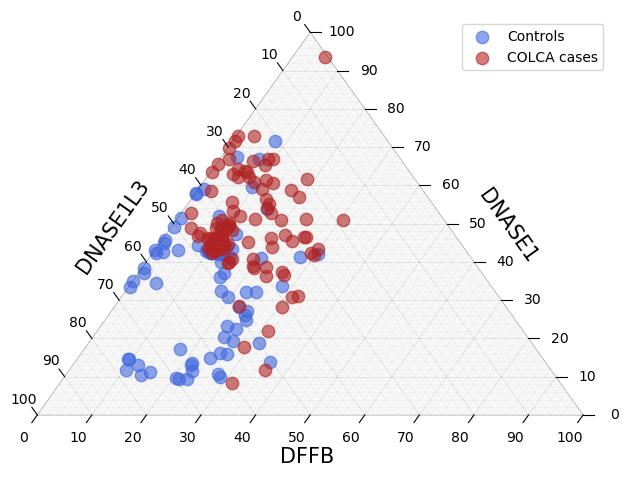

In [88]:
figure, tax = ternary.figure(scale=100)

s = 80
mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
tax.scatter(nuclease_activities[mask, :], alpha=0.6, color='royalblue', label='Controls', s=s)
mask = np.asarray([annot.cancer_type == 'colorectal' for annot in dataset.annotations], dtype=bool)
tax.scatter(nuclease_activities[mask, :], alpha=0.6, color='firebrick', label='COLCA cases', s=s)

tax.boundary(linewidth=0.1)
tax.gridlines(color='grey', multiple=2, alpha=0.2)
tax.gridlines(color='black', multiple=10, linewidth=0.5, alpha=0.2)

fontsize = 15
#tax.set_title('Relative nuclease activities', fontsize=fontsize)
tax.bottom_axis_label('DFFB', fontsize=fontsize)
tax.right_axis_label('DNASE1', fontsize=fontsize, offset=0.12)
tax.left_axis_label('DNASE1L3', fontsize=fontsize, offset=0.12)

# Set ticks
tax.ticks(axis='lbr', linewidth=0.8, offset=0.02, multiple=10)

# Remove default Matplotlib Axes
tax.clear_matplotlib_ticks()

plt.axis('off')

plt.legend()
plt.tight_layout()

plt.savefig(os.path.join(FIGURES_PATH, f'nuclease-activity-profile-cancer.png'), dpi=300)

plt.show()

0.004344363053223844 0.004939840461618482


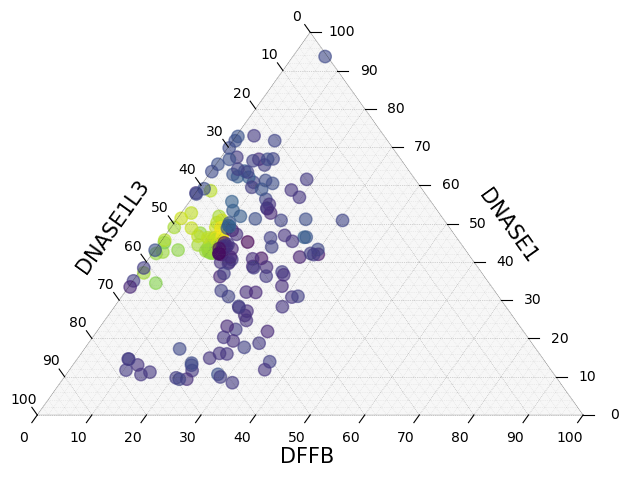

In [107]:
figure, tax = ternary.figure(scale=100)

s = 80

from modalibpy.end_motifs import REFERENCE_GENOME_END_MOTIF_FREQS, compute_f_profiles, semfar_scores
X = dataset.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]
c = semfar_scores(X)
print(np.min(c), np.max(c))
c = (c - np.min(c)) / (np.max(c) - np.min(c))
tax.scatter(nuclease_activities, alpha=0.6, c=c, colorbar=False, s=80)

tax.boundary(linewidth=0.1)
tax.gridlines(color='grey', multiple=2, alpha=0.2)
tax.gridlines(color='black', multiple=10, linewidth=0.5, alpha=0.2)

fontsize = 15
#tax.set_title('Relative nuclease activities', fontsize=fontsize)
tax.bottom_axis_label('DFFB', fontsize=fontsize)
tax.right_axis_label('DNASE1', fontsize=fontsize, offset=0.12)
tax.left_axis_label('DNASE1L3', fontsize=fontsize, offset=0.12)

# Set ticks
tax.ticks(axis='lbr', linewidth=0.8, offset=0.02, multiple=10)

# Remove default Matplotlib Axes
tax.clear_matplotlib_ticks()

plt.axis('off')

#legend = plt.legend()
#legend.get_frame().set_alpha(None)
plt.tight_layout()

plt.savefig(os.path.join(FIGURES_PATH, f'nuclease-activity-ichorcna.png'), dpi=300)

plt.show()

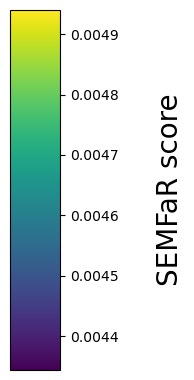

In [112]:
mpl = matplotlib
vmin, vmax = 0.004344363053223844, 0.004939840461618482
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
cmap = mpl.cm.viridis

fig = plt.figure(figsize=(2.5, 4.0))
cax = fig.add_axes([0.25, 0.05, 0.2, 0.9])

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])  # for older Matplotlib
cbar = plt.colorbar(sm, cax=cax)
cbar.set_label("\nSEMFaR score", fontsize=20)
plt.savefig(os.path.join(FIGURES_PATH, f'colorbar.png'), transparent=True, dpi=300)

In [ ]:
dataset = get_dataset('colorectal-train')

In [72]:
nuclease_activities = NucleaseActivityEstimator(max_n_iter=100000).fit_transform(dataset.data)

-0.7643238306045532:  70%|█████████████████████████████████████▏               | 70071/100000 [02:20<01:00, 498.26it/s]


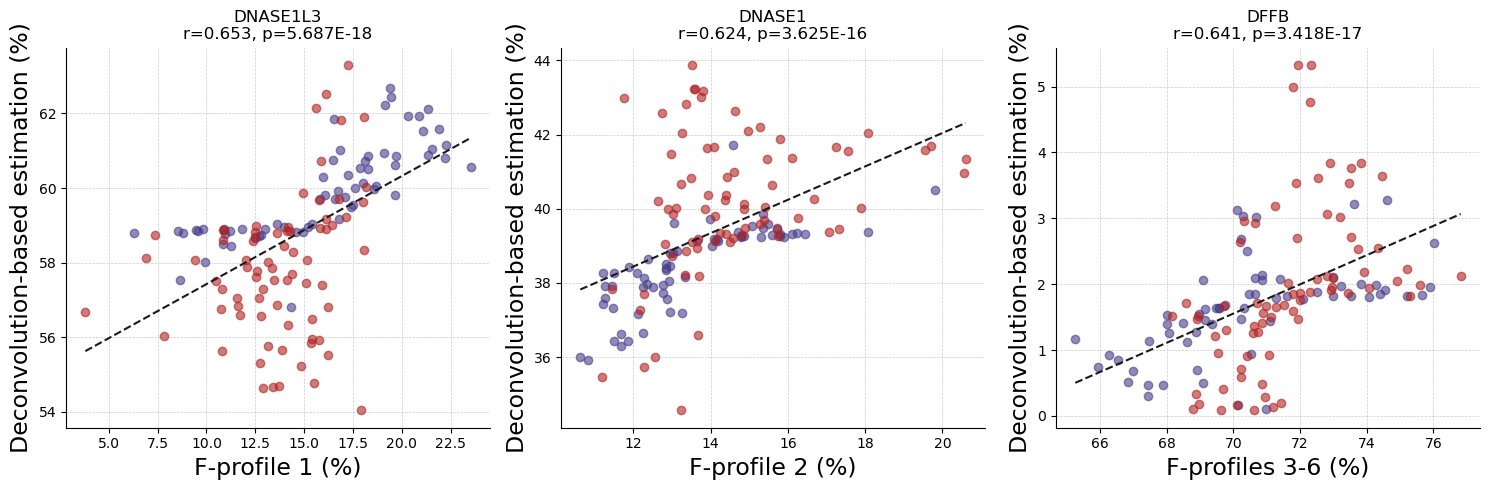

In [75]:
from modalibpy.end_motifs import compute_f_profiles

seaborn.reset_orig()

f_profiles = compute_f_profiles(dataset.data['End-motif probability (5 prime)']) * 100
f_profiles[:, 2] = np.sum(f_profiles[:, 2:], axis=1)
#f_profiles = f_profiles[:, :3] / np.sum(f_profiles[:, :3], axis=1)[:, np.newaxis]
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

plt.figure(figsize=(15, 5))
ax = plt.subplot(1, 3, 1)
correlation_plot(ax, f_profiles[:, 0], nuclease_activities[:, 2], y, 'F-profile 1 (%)', 'Deconvolution-based estimation (%)')
r, p = scipy.stats.spearmanr(f_profiles[:, 0], nuclease_activities[:, 2])
ax.set_title(f"DNASE1L3\nr={r:.3f}, p={p:.3E}")
ax = plt.subplot(1, 3, 2)
correlation_plot(ax, f_profiles[:, 1], nuclease_activities[:, 1], y, 'F-profile 2 (%)', 'Deconvolution-based estimation (%)')
r, p = scipy.stats.spearmanr(f_profiles[:, 1], nuclease_activities[:, 1])
ax.set_title(f"DNASE1\nr={r:.3f}, p={p:.3E}")
ax = plt.subplot(1, 3, 3)
correlation_plot(ax, f_profiles[:, 2], nuclease_activities[:, 0], y, 'F-profiles 3-6 (%)', 'Deconvolution-based estimation (%)')
r, p = scipy.stats.spearmanr(f_profiles[:, 2], nuclease_activities[:, 0])
ax.set_title(f"DFFB\nr={r:.3f}, p={p:.3E}")
#ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'nuclease-activity-profile-fprofiles.png'), dpi=300)
plt.show()

<h1 id="end-motifs">End motifs</h1> <a class="anchor" id="end-motifs"></a>

In [152]:
from modalibpy.end_motifs import REFERENCE_GENOME_END_MOTIF_FREQS, compute_f_profiles, semfar_scores
random_end_motif_profile = REFERENCE_GENOME_END_MOTIF_FREQS
random_end_motif_profile /= np.sum(random_end_motif_profile)

In [153]:
dataset = load_dataset([os.path.join(DATA_PATH, '50kb', f'{gc_code}.npz') for gc_code in GC_FEMALE_CONTROLS])

168


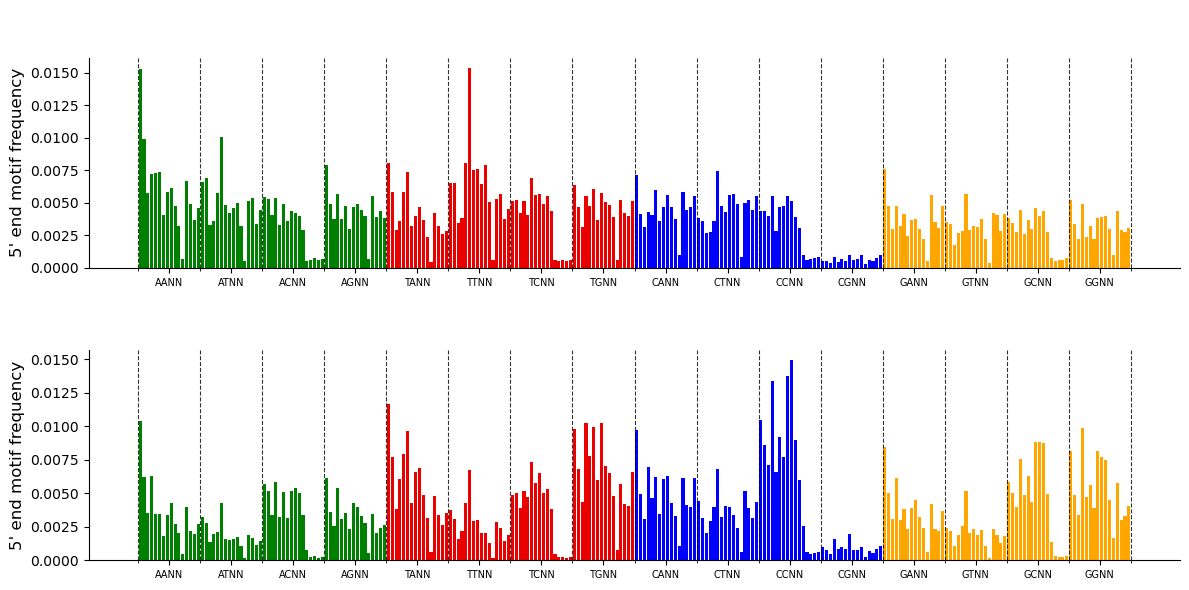

In [154]:
seaborn.reset_orig()
plt.figure(figsize=(12, 6))

ax = plt.subplot(2, 1, 1)
hist1 = random_end_motif_profile
hist1 = hist1 / np.sum(hist1)
xs, ys = np.arange(len(hist1)) + 0.5, hist1
plt.bar(xs[:64], ys[:64], color='#008000')
plt.bar(xs[64:128], ys[64:128], color='#eb0000')
plt.bar(xs[128:192], ys[128:192], color='#0000ff')
plt.bar(xs[192:], ys[192:], color='#ffa600')
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xticks(range(0, 257, 16), minor=True)
ax.set_xticklabels(['' for _ in range(17)], minor=True)
ax.set_xticks(np.arange(0, 256, 16) + 8, minor=False)
labels = ['AANN', 'ATNN', 'ACNN', 'AGNN', 'TANN', 'TTNN', 'TCNN', 'TGNN', 'CANN', 'CTNN', 'CCNN', 'CGNN', 'GANN', 'GTNN', 'GCNN', 'GGNN']
ax.set_xticklabels(labels, minor=False, fontsize=7)
ax.grid(which='minor', alpha=0.8, linestyle='--', linewidth=0.8, color='black')
plt.axhline(y=0, linestyle='--', color='black', linewidth=0.5)
ax.set_ylabel('5\' end motif frequency', fontsize=12)
#ax.set_title('Random fragmentation', fontsize=15)
ax.set_title('\n', fontsize=15)

ax = plt.subplot(2, 1, 2)
X = dataset.data['End-motif probability (5 prime)']
hist1 = np.sum(X, axis=0)
print(np.argmax(hist1))
hist1 = hist1 / np.sum(hist1)
xs, ys = np.arange(len(hist1)) + 0.5, hist1
plt.bar(xs[:64], ys[:64], color='#008000')
plt.bar(xs[64:128], ys[64:128], color='#eb0000')
plt.bar(xs[128:192], ys[128:192], color='#0000ff')
plt.bar(xs[192:], ys[192:], color='#ffa600')
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xticks(range(0, 257, 16), minor=True)
ax.set_xticklabels(['' for _ in range(17)], minor=True)
ax.set_xticks(np.arange(0, 256, 16) + 8, minor=False)
labels = ['AANN', 'ATNN', 'ACNN', 'AGNN', 'TANN', 'TTNN', 'TCNN', 'TGNN', 'CANN', 'CTNN', 'CCNN', 'CGNN', 'GANN', 'GTNN', 'GCNN', 'GGNN']
ax.set_xticklabels(labels, minor=False, fontsize=7)
ax.grid(which='minor', alpha=0.8, linestyle='--', linewidth=0.8, color='black')
plt.axhline(y=0, linestyle='--', color='black', linewidth=0.5)
ax.set_ylabel('5\' end motif frequency', fontsize=12)
#ax.set_title('cfDNA samples (controls)', fontsize=15)
ax.set_title('\n', fontsize=15)

plt.tight_layout()

plt.savefig(os.path.join(FIGURES_PATH, 'random-fragmentation.png'), dpi=300)

plt.show()

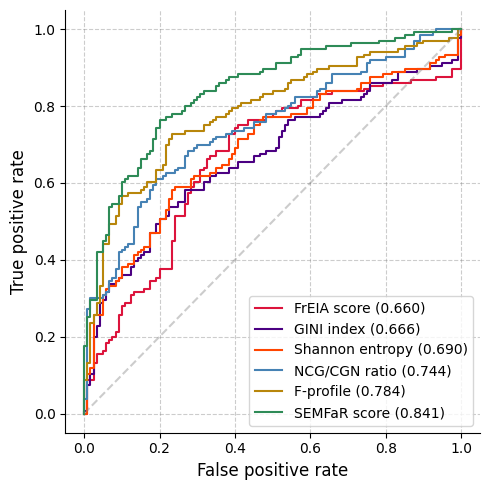

In [547]:
dataset_name = 'colorectal'

dataset = get_dataset(dataset_name)
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

X = dataset.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]

# CGN/NCG motif ratio
y_cgnncg = cgnngc_ratios(X)
y_ncgcgn = 1. / y_cgnncg

# GINI index
y_gini = 1 - np.sum(np.square(X), axis=1)

# Shannon entropy
y_shannon = -np.sum(X * np.log(X), axis=1) / np.log(256)

# FrEIA score
whitelist_decreased = {'CCT', 'CCA', 'ACC', 'CCC', 'CGT', 'CAT', 'CAC', 'CGA', 'CTT', 'GGC', 'ACA', 'CGC', 'ACT', 'CGG', 'GCC'}
whitelist_increased = {'ACG', 'ATG', 'TTC', 'TCG', 'TTG', 'AGG', 'GTG', 'TTA', 'AAG', 'GCG', 'AGA', 'ATA', 'GAG', 'GTA'}
idx_decreased, idx_increased = [], []
for k in range(256):
    motif = uint8_motif_to_str(k)
    if motif[:3] in whitelist_decreased:
        idx_decreased.append(k)
    elif motif[:3] in whitelist_increased:
        idx_increased.append(k)
idx_decreased, idx_increased = np.asarray(idx_decreased), np.asarray(idx_increased)
y_freia = y_shannon * np.sum(X[:, idx_increased], axis=1) / np.sum(X[:, idx_decreased], axis=1)

# F-profile NMF
y_nmf = compute_f_profiles(X)[:, 5]

# Proposed method
#y_mae = np.dot(X, random_end_motif_profile)
y_mae = semfar_scores(X)

seaborn.reset_orig()
plt.figure(figsize=(5, 5))
ax = plt.subplot(1, 1, 1)
colors = ['crimson', 'indigo', 'orangered', 'steelblue', 'darkgoldenrod', 'seagreen']
for y_pred, name, color in zip([y_freia, y_gini, y_shannon, y_ncgcgn, y_nmf, y_mae], ['FrEIA score', 'GINI index', 'Shannon entropy', 'NCG/CGN ratio', 'F-profile', 'SEMFaR score'], colors):
    fpr, tpr, _ = roc_curve(y, y_pred)
    auroc = roc_auc_score(y, y_pred)
    plt.plot(fpr, tpr, label=f'{name} ({auroc:.3f})', color=color)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', alpha=0.4)
ax.grid(linestyle='--', color='grey', alpha=0.4)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.legend(loc='lower right')
ax.set_xlabel('False positive rate', fontsize=12)
ax.set_ylabel('True positive rate', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f'end-motif-unsupervised-perf-roc.png'), dpi=300)
plt.show()

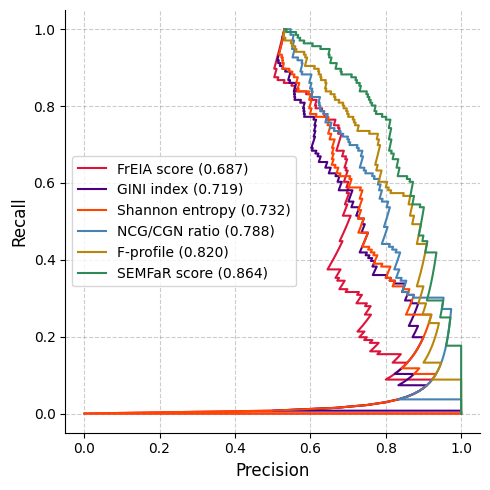

In [548]:
seaborn.reset_orig()
plt.figure(figsize=(5, 5))
ax = plt.subplot(1, 1, 1)
colors = ['crimson', 'indigo', 'orangered', 'steelblue', 'darkgoldenrod', 'seagreen']
for y_pred, name, color in zip([y_freia, y_gini, y_shannon, y_ncgcgn, y_nmf, y_mae], ['FrEIA score', 'GINI index', 'Shannon entropy', 'NCG/CGN ratio', 'F-profile', 'SEMFaR score'], colors):
    precision, recall, _ = precision_recall_curve(y, y_pred)
    auprc = average_precision_score(y, y_pred)
    plt.plot(precision, recall, label=f'{name} ({auprc:.3f})', color=color)
#ax.plot([0, 1], [0, 1], linestyle='--', color='grey', alpha=0.4)
ax.grid(linestyle='--', color='grey', alpha=0.4)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.legend(loc='center left')
ax.set_xlabel('Precision', fontsize=12)
ax.set_ylabel('Recall', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f'end-motif-unsupervised-perf-pr.png'), dpi=300)
plt.show()

In [552]:
dataset = get_dataset('colorectal-train')

SignificanceResult(statistic=np.float64(0.4912539436593425), pvalue=np.float64(1.0933524682373573e-09))


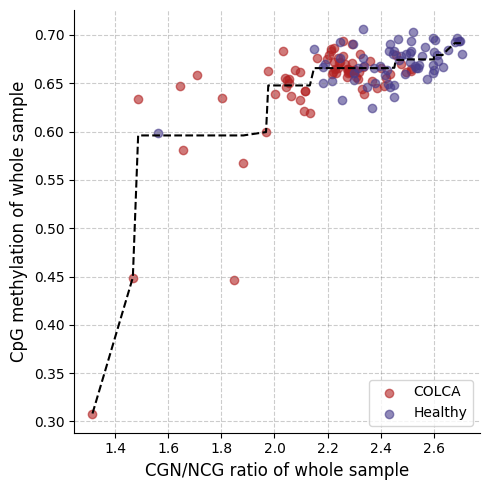

In [557]:
X = dataset.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]

y_cgnncg = cgnngc_ratios(X)

n = dataset.data['CpG count']
X = dataset.data['CpG Methylation (first moment)']
meth = np.sum(n * X, axis=1) / np.sum(n, axis=1)

xs, ys = y_cgnncg, meth

model = IsotonicRegression(increasing=True)
model.fit(xs, ys)
xs_hat = np.sort(xs)
ys_hat = model.predict(xs_hat)

plt.figure(figsize=(5, 5))
ax = plt.subplot(1, 1, 1)
print(scipy.stats.spearmanr(meth, y_cgnncg))
mask = np.asarray([annot.cancer_type == 'colorectal' for annot in dataset.annotations], dtype=bool)
ax.scatter(xs[mask], ys[mask], alpha=0.6, color='firebrick', label='COLCA')
mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
ax.scatter(xs[mask], ys[mask], alpha=0.6, color='darkslateblue', label='Healthy')
ax.plot(xs_hat, ys_hat, color='black', linestyle='--')
ax.legend(loc='lower right')
ax.set_ylabel('CpG methylation of whole sample', fontsize=12)
ax.set_xlabel('CGN/NCG ratio of whole sample', fontsize=12)
ax.grid(linestyle='--', color='grey', alpha=0.4)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'cgnncg-meth.png'), dpi=300)
plt.show()

SignificanceResult(statistic=np.float64(0.3879608294930876), pvalue=np.float64(0.0016795825569802824))


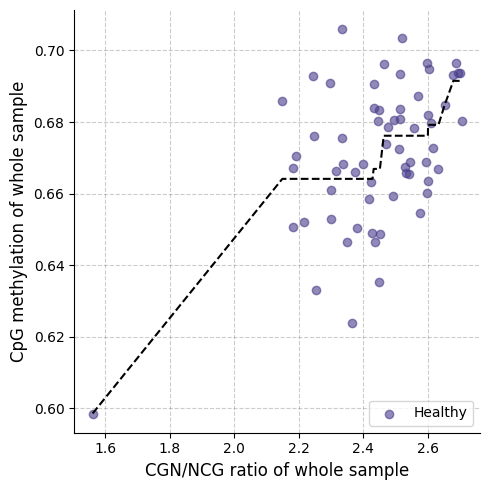

In [556]:
X = dataset.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]

y_cgnncg = cgnngc_ratios(X)

n = dataset.data['CpG count']
X = dataset.data['CpG Methylation (first moment)']
meth = np.sum(n * X, axis=1) / np.sum(n, axis=1)

mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
xs, ys = y_cgnncg[mask], meth[mask]

model = IsotonicRegression(increasing=True)
model.fit(xs, ys)
xs_hat = np.sort(xs)
ys_hat = model.predict(xs_hat)

plt.figure(figsize=(5, 5))
ax = plt.subplot(1, 1, 1)
print(scipy.stats.spearmanr(meth[mask], y_cgnncg[mask]))
ax.scatter(xs, ys, alpha=0.6, color='darkslateblue', label='Healthy')
ax.plot(xs_hat, ys_hat, color='black', linestyle='--')
ax.legend(loc='lower right')
ax.set_ylabel('CpG methylation of whole sample', fontsize=12)
ax.set_xlabel('CGN/NCG ratio of whole sample', fontsize=12)
ax.grid(linestyle='--', color='grey', alpha=0.4)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'cgnncg-meth-controls.png'), dpi=300)
plt.show()

<h1 id="multimodal-heatmaps">Multimodal heatmaps</h1> <a class="anchor" id="multimodal-heatmaps"></a>

In [216]:
dataset_name = 'colorectal-train'
dataset = get_dataset(dataset_name)
#dataset = get_dataset('colorectal-train')
#dataset = get_dataset('misc')

C:\Users\antoi\AppData\Local\Temp\ipykernel_16196\1232919659.py:141: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  tf_cmap_ = matplotlib.cm.get_cmap('YlGn')
C:\Users\antoi\AppData\Local\Temp\ipykernel_16196\1232919659.py:143: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  age_cmap_ = matplotlib.cm.get_cmap('GnBu')


colorectal-train


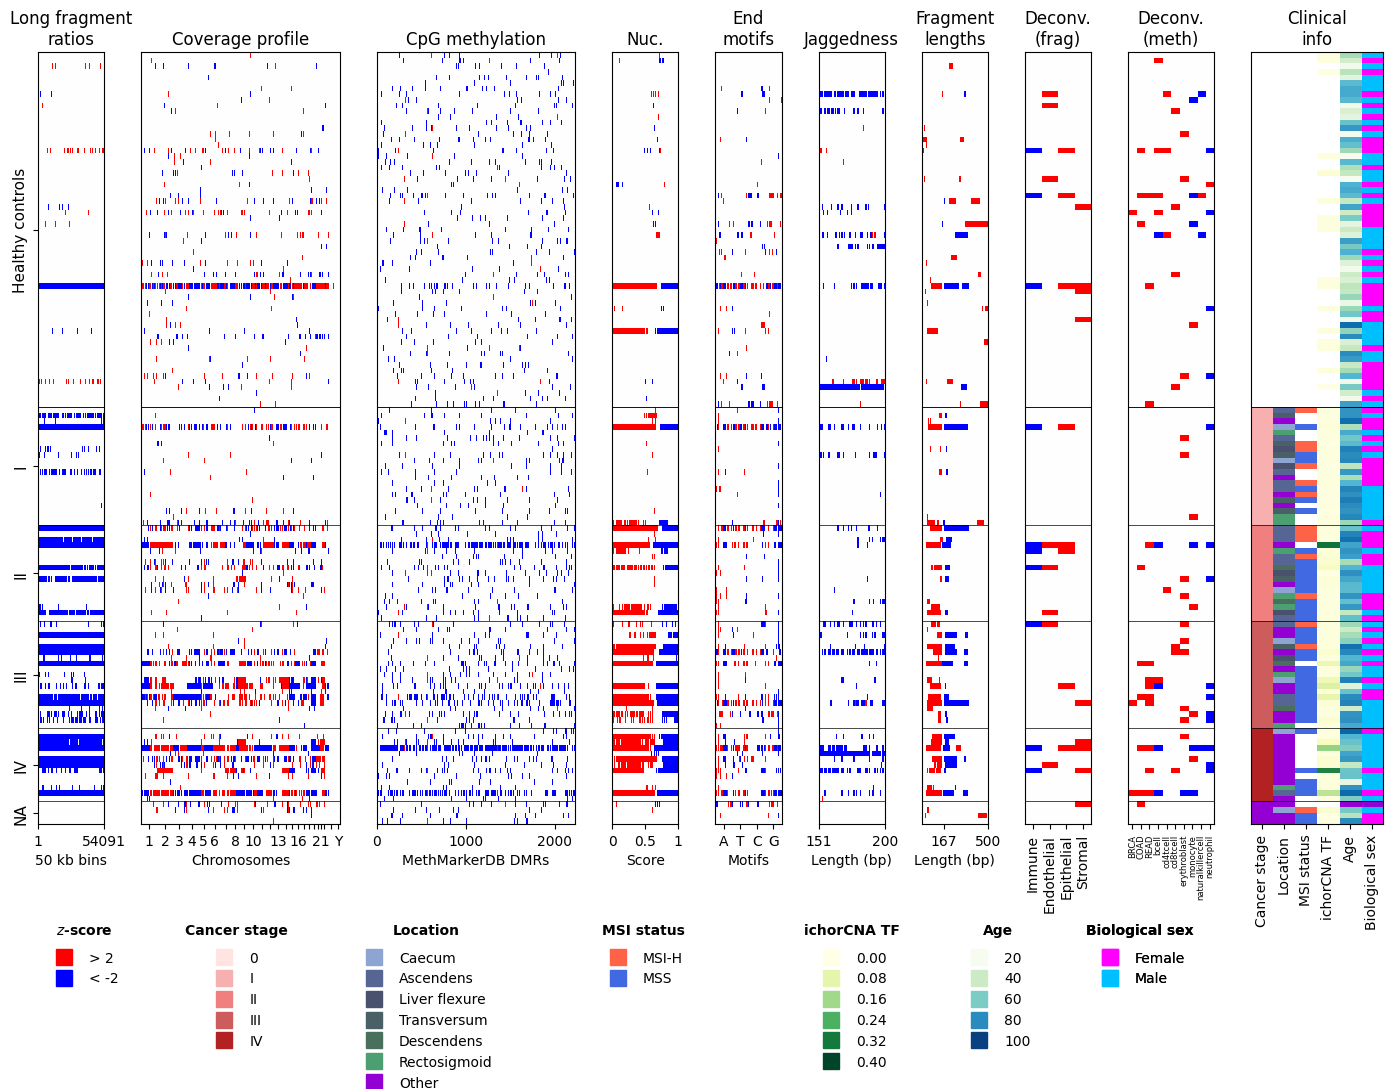

In [226]:
from modalibpy.modalities.jaggedness import JaggednessModality
from modalibpy.modalities.end_motif_frequency import EndMotifFrequencyModality
from modalibpy.modalities.coverage import CoverageModality
from modalibpy.modalities.cpg_methylation import CpGMethylationModality
from modalibpy.modalities.nucleosome_positioning import NucleosomePositioningModality
from modalibpy.modalities.frag_length_counts import FragLengthCountModality
from modalibpy.modalities.long_frag_ratio import LongFragmentRatioModality
from modalibpy.modalities.cell_type_deconvolution import FragCellTypeDeconvolutionModality, MethCellTypeDeconvolutionModality
from modalibpy.modalities.mutational import MutationalSignatureModality


def multimodal_heatmap(dataset):

    UNKNOWN_COLOR = 'darkviolet'

    if dataset_name == 'breast':
        subtypes = np.asarray([annot.subtype() if annot.cancer_type else '' for annot in dataset.annotations], dtype=object)
        cancer_type_title = 'Cancer subtype'
        tf_max = 0.20
    elif dataset_name == 'colorectal-train':
        subtypes = []
        for annot in dataset.annotations:
            if annot.extra_info in {'Ascendens', 'Caecum', 'Descendens', 'Transversum', 'Liver flexure'}:
                subtypes.append(annot.extra_info)
            elif annot.extra_info == 'Liver flexure + Transversum':
                subtypes.append('Transversum')
            elif annot.extra_info in {'Liver flexure + rectosigmoïd', 'rectum', 'Rectum', 'Rectosigmoid'}:
                subtypes.append('Rectosigmoid')
            else:
                subtypes.append('Other')
        subtypes = np.asarray(subtypes, dtype=object)
        cancer_type_title = 'Location'
        tf_max = 0.4
    else:
        subtypes = np.asarray([annot.cancer_type.strip() if annot.cancer_type else '' for annot in dataset.annotations], dtype=object)
        cancer_type_title = 'Cancer type'
        tf_max = 1.0

    # Sort samples by cancer stage
    idx_s = []
    mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
    idx_s.append(np.where(mask)[0])
    for stage in [0, 1, 2, 3, 4, -1]:
        mask = np.asarray([annot.is_cancer and (np.nan_to_num(float(annot), nan=-1) == stage) for annot in dataset.annotations], dtype=bool)
        idx_s.append(np.where(mask)[0])
        np.random.seed(0xCAFE)
        np.random.shuffle(idx_s[-1])
    sizes = [len(idx_) for idx_ in idx_s]
    idx_s = np.concatenate(idx_s, axis=0)
    
    seaborn.reset_orig()
    
    y = dataset.y
    
    f = plt.figure(figsize=(14, 11))
    gs = matplotlib.gridspec.GridSpec(2, 10, width_ratios=[1, 3, 3, 1, 1, 1, 1, 1, 1.3, 2], height_ratios=[4, 0.7], figure=f)
    
    kwargs = dict(cache=True, probability=True)
    modalities = [
        LongFragmentRatioModality(**kwargs),
        CoverageModality(**kwargs),
        CpGMethylationModality(**kwargs),
        NucleosomePositioningModality(**kwargs),
        EndMotifFrequencyModality(**kwargs),
        JaggednessModality(**kwargs),
        FragLengthCountModality(**kwargs),
        FragCellTypeDeconvolutionModality(use_compartments=True, **kwargs),
        MethCellTypeDeconvolutionModality(**kwargs),
        #MutationalSignatureModality(**kwargs),
    ]
    titles = ['Long fragment\nratios', 'Coverage profile', 'CpG methylation', 'Nuc.', 'End\nmotifs', 'Jaggedness', 'Fragment\nlengths', 'Deconv.\n(frag)', 'Deconv.\n(meth)', 'Info']
    xlabels = ['50 kb bins', 'Chromosomes', 'MethMarkerDB DMRs', 'Score', 'Motifs', 'Length (bp)', 'Length (bp)', '', '', '']
    
    for p, modality in enumerate(modalities):

        ax = f.add_subplot(gs[0, p])
        
        print(modality)
        X = modality.process(dataset.data)
        X = StandardScaler().fit(X[y == 0]).transform(X)
        
        X = np.sign(X) * (np.abs(X) > 2)
        Xs = []
        mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
        Xs.append(X[mask, :])
        for stage in [0, 1, 2, 3, 4, -1]:
            mask = np.asarray([annot.is_cancer and (np.nan_to_num(float(annot), nan=-1) == stage) for annot in dataset.annotations], dtype=bool)
            Xs.append(X[mask, :])
        sizes = [len(X) for X in Xs]
        X = X[idx_s, :]
        
        ax.imshow(X, cmap='bwr', aspect='auto', interpolation='none')
        for split in np.cumsum(sizes)[:-1]:
            ax.axhline(y=split - 0.5, linestyle='-', color='black', linewidth=0.5)
        ax.set_title(titles[p])
        ax.set_xlabel(xlabels[p])
        if p == 0:
            splits = np.asarray([0] + list(np.cumsum(sizes)))
            splits = 0.5 * (splits[:-1] + splits[1:]) - 0.5
            yticklabels, yticks = [], []
            for yticklabel, ytick, size in zip(['Healthy controls', '0', 'I', 'II', 'III', 'IV', 'NA'], splits, sizes):
                if size > 0:
                    yticklabels.append(yticklabel)
                    yticks.append(ytick)
            ax.set_yticks(yticks)
            ax.set_yticklabels(yticklabels, rotation=90, fontsize=11)
            for tick in ax.yaxis.get_majorticklabels():
                tick.set_verticalalignment('center')
        else:
            ax.set_yticks([])
            ax.set_yticklabels([])

        if p == 0:
            ax.set_xticks([0, X.shape[1]], [1, X.shape[1]])
        elif p == 1:
            #chr_pos = np.asarray([0, 24896, 49116, 68946, 87968, 106122, 123203, 139138, 153652, 167492, 180872, 194381, 207709, 219146, 229851, 240052, 249085, 257411, 265449, 271311, 277756, 282427, 287509]) / 287509.
            chr_pos = np.asarray([0, 24896, 49116, 68946, 87968, 106122, 123203, 139138, 153652, 167492, 180872, 194381, 207709, 219146, 229851, 240052, 249085, 257411, 265449, 271311, 277756, 282427, 287509, 302991, 308762]) / 308762.
            chr_pos = np.round(0.5 * (chr_pos[1:] + chr_pos[:-1]) * (X.shape[1] - 1)).astype(int)
            chr_ids = {1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 21, 24}
            xticks = chr_pos
            xticklabels = ['' if ((i + 1) not in chr_ids) else str(i + 1) for i in range(24)]
            xticklabels = [x.replace('23', 'X').replace('24', 'Y') for x in xticklabels]
            ax.set_xticks(xticks, xticklabels)
        elif p == 3:
            ax.set_xticks([0, 0.5 * X.shape[1], X.shape[1]], [0, 0.5, 1])
        elif p == 4:
            ax.set_xticks([32, 96, 160, 224], ['A', 'T', 'C', 'G'])
        elif p == 5:
            ax.set_xticks([0, X.shape[1]], [151, 200])
        elif p == 6:
            ax.set_xticks([167, 500], [167, 500])
        elif p == 7:
            cell_types = ['Immune', 'Endothelial', 'Epithelial', 'Stromal']
            ax.set_xticks(range(len(cell_types)), cell_types, rotation=90, fontsize=10)
        elif p == 8:
            cell_types = ['BRCA', 'COAD', 'READ', 'bcell', 'cd4tcell', 'cd8tcell', 'erythroblast', 'monocyte', 'naturalkillercell', 'neutrophil']
            ax.set_xticks(range(len(cell_types)), cell_types, rotation=90, fontsize=6)

    ax = f.add_subplot(gs[0, 9])
    I = np.zeros((len(dataset), 5 if (dataset_name != 'colorectal-train') else 6, 4), dtype=float)
    tf_cmap_ = matplotlib.cm.get_cmap('YlGn')
    tf_cmap = lambda x: tf_cmap_(np.clip(x, 0, tf_max) / tf_max)
    age_cmap_ = matplotlib.cm.get_cmap('GnBu')
    age_cmap = lambda x: age_cmap_((np.clip(x, 20, 100) - 20) / 80)

    if dataset_name == 'breast':
        subtype_colors = {'DCIS': 'silver', 'Luminal A': 'teal', 'Luminal B': 'mediumseagreen', 'HER2-positive': 'peru', 'Triple negative': 'tomato', 'Unknown': UNKNOWN_COLOR}
    elif dataset_name == 'colorectal-train':
        subtype_colors = {'Caecum': '#8EA4D2', 'Ascendens': '#566594', 'Liver flexure': '#49516F', 'Transversum': '#496066', 'Descendens': '#496F5D', 'Rectosigmoid': '#4C9F70', 'Other': UNKNOWN_COLOR}
    else:
        subtype_colors = {'haematological cancer': 'teal', 'ovarian cancer': 'mediumseagreen', 'cervical cancer': 'peru', 'prostate cancer': 'tomato', 'lip cancer': 'silver', 'Unknown': UNKNOWN_COLOR}
    STAGE_IDX = 0
    SUBTYPE_IDX = 1
    MSI_IDX = 2
    TF_IDX = 2 if (dataset_name != 'colorectal-train') else 3
    AGE_IDX = 3 if (dataset_name != 'colorectal-train') else 4
    SEX_IDX = 4 if (dataset_name != 'colorectal-train') else 5
    for i in range(len(dataset)):
        if isinstance(dataset.annotations[i].msi, str):
            if 'msi-h' in dataset.annotations[i].msi.lower():
                I[i, MSI_IDX, :] = matplotlib.colors.to_rgba('tomato')
            elif 'mss' in dataset.annotations[i].msi.lower():
                I[i, MSI_IDX, :] = matplotlib.colors.to_rgba('royalblue')
        stage = int(np.nan_to_num(float(dataset.annotations[i]), nan=-1))
        stage_dict = {0: 'mistyrose', 1: (0.97, 0.69, 0.69, 1.0), 2: 'lightcoral', 3: 'indianred', 4: 'firebrick'}
        if not np.isnan(dataset.ages[i]):
            I[i, AGE_IDX, :] = age_cmap(dataset.ages[i])
        else:
            I[i, AGE_IDX, :] = matplotlib.colors.to_rgba(UNKNOWN_COLOR)
        if not np.isnan(dataset.ichor[i]):
            I[i, TF_IDX, :] = tf_cmap(np.nan_to_num(dataset.ichor[i]))
        if dataset.annotations[i].is_cancer:
            if stage in stage_dict:
                color = stage_dict[stage]
            else:
                color = UNKNOWN_COLOR
            if isinstance(color, str):
                color = matplotlib.colors.to_rgba(color)
            I[i, STAGE_IDX, :] = color
            if subtypes[i] in subtype_colors:
                I[i, SUBTYPE_IDX, :] = matplotlib.colors.to_rgba(subtype_colors[subtypes[i]])
            else:
                I[i, SUBTYPE_IDX, :] = matplotlib.colors.to_rgba(UNKNOWN_COLOR)
        if np.isnan(dataset.sexes[i]):
            color = UNKNOWN_COLOR
        elif dataset.sexes[i]:
            color = 'fuchsia'
        else:
            color = 'deepskyblue'
        I[i, SEX_IDX, :] = matplotlib.colors.to_rgba(color)
    ax.imshow(I[idx_s, :, :], aspect='auto', interpolation='none')
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_title('Clinical\ninfo')
    #for side in ['left', 'right', 'top']:
    #    ax.spines[side].set_visible(False)
    for split in np.cumsum(sizes)[:-1]:
        ax.axhline(y=split - 0.5, linestyle='-', color='black', linewidth=0.5)
    if (dataset_name != 'colorectal-train'):
        ax.set_xticks(np.arange(5))
        ax.set_xticklabels(['Cancer stage', 'Cancer type', 'ichorCNA TF', 'Age', 'Biological sex'], rotation=90, fontsize=10)
    else:
        ax.set_xticks(np.arange(6))
        ax.set_xticklabels(['Cancer stage', 'Location', 'MSI status', 'ichorCNA TF', 'Age', 'Biological sex'], rotation=90, fontsize=10)

    ax = f.add_subplot(gs[1, :])
    ax.set_axis_off()

    y_offset = 1.25
    
    rect1 = matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color='#FF0000')
    rect2 = matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color='#0000FF')
    legend = plt.legend((rect1, rect2), (r'> 2', r'< -2'), frameon=False, title=r'$z$-score', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)

    colors = ['mistyrose', (0.97, 0.69, 0.69, 1.0), 'lightcoral', 'indianred', 'firebrick']
    labels = ['0', 'I', 'II', 'III', 'IV']
    if dataset_name == 'misc':
        colors.append(UNKNOWN_COLOR)
        labels.append('Unknown')
    handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=color) for color in colors]
    legend = plt.legend(handles, labels, frameon=False, title=r'Cancer stage', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.1, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)

    labels = list(subtype_colors.keys())
    handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=subtype_colors[label]) for label in labels]
    legend = plt.legend(handles, labels, frameon=False, title=cancer_type_title, title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.23, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)

    if dataset_name == 'colorectal-train':
        labels = ['MSI-H', 'MSS']
        colors = ['tomato', 'royalblue']
        handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=color) for color in colors]
        legend = plt.legend(handles, labels, frameon=False, title='MSI status', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.41, y_offset), loc='upper left')
        legend._legend_box.sep = 10
        ax.add_artist(legend)

    if dataset_name == 'misc':
        values = [0.0, 0.2, 0.3, 0.6, 0.8, 1.0]
        labels = ['0.0', '0.2', '0.4', '0.6', '0.8', '1.0']
    elif dataset_name == 'colorectal-train':
        values = [0.0, 0.08, 0.16, 0.24, 0.32, 0.40]
        labels = ['0.00', '0.08', '0.16', '0.24', '0.32', '0.40']
    else:
        values = [0.0, 0.03, 0.06, 0.09, 0.12, 0.15]
        labels = ['0.00', '0.03', '0.06', '0.09', '0.12', '0.15']
    colors = [tf_cmap(value) for value in values]
    handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=color) for color in colors]
    legend = plt.legend(handles, labels, frameon=False, title=r'ichorCNA TF', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.56, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)

    values = [20, 40, 60, 80, 100]
    colors = [age_cmap(value) for value in values]
    labels = [str(value) for value in values]
    if dataset_name == 'misc':
        colors.append(UNKNOWN_COLOR)
        labels.append('Unknown')
    handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=color) for color in colors]
    legend = plt.legend(handles, labels, frameon=False, title=r'Age', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.68, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)

    labels = ['Female']
    colors = ['fuchsia']
    if dataset_name == 'misc':
        colors += ['deepskyblue', UNKNOWN_COLOR]
        labels += ['Male', 'Unknown']
    elif dataset_name == 'colorectal-train':
        colors += ['deepskyblue']
        labels += ['Male']
    handles = [matplotlib.lines.Line2D([], [], marker='s', markersize=12, linewidth=0, color=color) for color in colors]
    legend = plt.legend(handles, labels, frameon=False, title=r'Biological sex', title_fontproperties={'weight': 'bold'}, bbox_to_anchor=(0.77, y_offset), loc='upper left')
    legend._legend_box.sep = 10
    ax.add_artist(legend)
    
    plt.tight_layout()
    print(dataset_name)
    if dataset_name == 'breast':
        plt.savefig(os.path.join(FIGURES_PATH, 'multimodal-heatmap-brca.png'), dpi=300)
    elif dataset_name == 'colorectal-train':
        plt.savefig(os.path.join(FIGURES_PATH, 'multimodal-heatmap-colca.png'), dpi=300)
    else:
        plt.savefig(os.path.join(FIGURES_PATH, 'multimodal-heatmap-misc.png'), dpi=300)
    plt.show()


multimodal_heatmap(dataset)

<h1 id="clustering">t-SNE</h1> <a class="anchor" id="clustering"></a>

In [41]:
dataset_name = 'colorectal-train'
#dataset_name = 'breast-no-control'
dataset = get_dataset(dataset_name, downsampled=True)

In [42]:
y = dataset.y
if dataset_name == 'breast-no-control':
    labels = np.asarray([dataset.annotations[i].subtype() for i in range(len(dataset))], dtype=object)
elif dataset_name == 'breast':
    labels = np.asarray(['Healthy' if (y[i] == 0) else dataset.annotations[i].subtype() for i in range(len(dataset))], dtype=object)
else:
    labels = np.asarray(['Healthy' if (y[i] == 0) else dataset.annotations[i].extra_info for i in range(len(dataset))], dtype=object)
    for i in range(len(labels)):
        if labels[i] in {'Liver flexure + Transversum'}:
            labels[i] = 'Transversum'
        elif labels[i] in {'rectum', 'Rectum', 'Sigmoid', 'Rectosigmoid', 'Liver flexure + rectosigmoïd'}:
            labels[i] = 'Rectosigmoid'
        elif labels[i] in {'splenic flexure'}:
            labels[i] = 'Other'
        elif labels[i] in {'', 'no '}:
            labels[i] = 'Other'

In [43]:
from modalibpy.pipeline.mkl import KernelMatrixExtractor
modalities = [Modalities.NUCLEOSOME_POSITIONING, Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.COVERAGE, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]
#modalities = [Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.CPG_METHYLATION]
Ks = KernelMatrixExtractor(modalities, mod_options={'probabilistic': False, 'cache': True}).fit_transform(dataset.data, y=dataset.y)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:30<00:00, 65.57it/s]


In [44]:
K = MultipleKernelLearning(supervised=False).fit_transform(Ks, y=None)
#K = MultipleKernelLearning(supervised=True).fit_transform(Ks, y=dataset.y)

In [45]:
from sklearn.manifold import TSNE
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering

y_multi = LabelEncoder().fit_transform(labels)
D = np.sqrt(np.diagonal(K)[np.newaxis, :] + np.diagonal(K)[:, np.newaxis] - 2 * K)
#coords = TSNE(metric='precomputed', init='random', perplexity=10, early_exaggeration=20).fit_transform(D)
#coords = TSNE(metric='precomputed', init='random', perplexity=15, early_exaggeration=50).fit_transform(D)
coords = TSNE(metric='precomputed', init='random', random_state=0).fit_transform(D)

y_hat = SpectralClustering(affinity='precomputed', n_clusters=10).fit_predict(K)
print(y_hat)
print(f'Silhouette (breast cancer): {silhouette_score(D, y_multi, metric="precomputed")}')
print(adjusted_rand_score(y_multi, y_hat))

C:\Users\antoi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\antoi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


[8 8 6 8 6 6 8 5 8 6 5 6 6 6 8 8 8 6 8 6 8 8 6 6 8 0 6 5 6 8 6 8 5 8 8 8 6
 6 6 6 8 3 6 6 6 8 8 8 8 5 6 8 6 8 6 8 8 8 6 5 6 6 8 0 8 5 5 5 5 5 9 5 5 8
 8 8 5 8 5 0 7 9 8 0 0 8 8 2 8 5 8 8 5 8 8 8 8 0 8 0 8 9 8 0 5 8 5 8 8 8 4
 0 8 8 0 8 3 8 5 0 5 8 8 4 5 0 0 5 0 5 1 0 0 5 8 8 8]
Silhouette (breast cancer): -0.02998021372378679
0.12446526380042994


C:\Users\antoi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


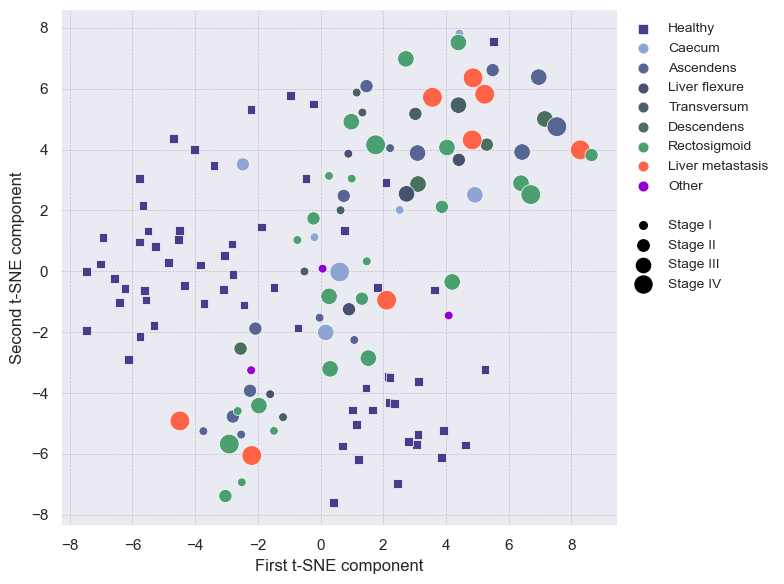

In [46]:
seaborn.set_theme()

plt.figure(figsize=(8, 6))
ax = axl = plt.subplot(1, 1, 1)

cancer_stages = []
for i, annot in enumerate(dataset.annotations):
    if float(annot) == 0:
        cancer_stages.append('0')
    elif float(annot) == 1:
        cancer_stages.append('I')
    elif float(annot) == 2:
        cancer_stages.append('II')
    elif float(annot) == 3:
        cancer_stages.append('III')
    elif float(annot) == 4:
        cancer_stages.append('IV')
    else:
        cancer_stages.append('')
cancer_stages = np.asarray(cancer_stages, dtype=object)

if dataset_name in {'breast', 'breast-no-control'}:
    style_dict = {
        'Healthy': ('darkslateblue', 's'),
        'DCIS': ('silver', 'X'),
        'Luminal A': ('teal', 'o'),
        'Luminal B': ('mediumseagreen', 'o'),
        'HER2-positive': ('peru', 'o'),
        'Triple negative': ('tomato', 'o'),
        'Unknown': ('darkviolet', 'o'),
    }
else:
    style_dict = {
        'Healthy': ('darkslateblue', 's'),
        'Caecum': ('#8EA4D2', 'o'), 
        'Ascendens': ('#566594', 'o'),
        'Liver flexure': ('#49516F', 'o'),
        'Transversum': ('#496066', 'o'),
        'Descendens': ('#496F5D', 'o'),
        'Rectosigmoid': ('#4C9F70', 'o'),
        'Liver metastasis': ('tomato', 'o'),
        'Other': ('darkviolet', 'o'),
    }
stage0_label = 'Stage 0' if (dataset_name != 'breast') else 'DCIS'
legend = True

labels_ = np.copy(labels)

palette = {key: value[0] for key, value in style_dict.items()}
markers = {key: value[1] for key, value in style_dict.items()}

for i in range(len(labels_)):
    key = labels_[i]
    if cancer_stages[i] == '0':
        labels_[i] += '-stage0'
        palette[key + '-stage0'] = palette[key]
        markers[key + '-stage0'] = 'X'

sizes = [39, 40, 90, 140, 200]
size_labels = [stage0_label, 'Stage I', 'Stage II', 'Stage III', 'Stage IV']

cancer_stage_info_available = False
importances = np.full(len(coords), sizes[0])
for k, stage in enumerate(['0', 'I', 'II', 'III', 'IV']):
    importances[cancer_stages == stage] = sizes[k]
    if np.any(cancer_stages == stage):
        cancer_stage_info_available = True

idx = np.arange(len(coords))
np.random.shuffle(idx)  # Shuffle display order to ensure no class is dominating the visual space
g = seaborn.scatterplot(
    ax=ax,
    x=coords[idx, 0],
    y=coords[idx, 1],
    hue=labels_[idx],
    hue_order=list(palette.keys()),
    style=labels_[idx],
    size=importances[idx],
    sizes=(min(sizes), max(sizes)),
    palette=palette,
    markers=markers,
    legend=False
)
ax.grid(alpha=0.4, linestyle='--', linewidth=0.5, color='grey')
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('First t-SNE component')
ax.set_ylabel('Second t-SNE component')

# Custom legend
if legend:
    handles, labels_ = [], []

    # Marker color labels
    for label, (color, marker) in style_dict.items():
        handles.append(plt.scatter([], [], s=sizes[0], color=color, marker=marker))
        labels_.append(label)

    if cancer_stage_info_available:

        # Add white space
        handles.append(plt.scatter([], [], s=0))
        labels_.append(' ')

        # Marker size labels
        if np.any(cancer_stages == '0'):
            handles.append(plt.scatter([], [], s=0.75*sizes[0], color='black', marker='x'))
            labels_.append(stage0_label)
        for size, label in zip(sizes[1:], size_labels[1:]):
            handles.append(plt.scatter([], [], s=0.75*size, color='black'))
            labels_.append(label)
    
    axl.legend(
        handles=handles,
        labels=labels_,
        prop={'size': 10},
        bbox_to_anchor=(1.0, 1.0),
        loc='upper left',
        frameon=False
    )
plt.tight_layout()
if dataset_name == 'breast':
    plt.savefig(os.path.join(FIGURES_PATH, 'mkl-tsne-brca.png'), dpi=300)
elif dataset_name == 'colorectal-train':
    plt.savefig(os.path.join(FIGURES_PATH, 'mkl-tsne-colca.png'), dpi=300)
else:
    plt.savefig(os.path.join(FIGURES_PATH, 'mkl-tsne-misc.png'), dpi=300)
plt.show()

<h1 id="trinucleotides">Nucleotide frequencies</h1> <a class="anchor" id="trinucleotides"></a>

In [116]:
TRINUCLEOTIDE_DICT = {
    'AAA': 0, 'AAC': 1, 'AAG': 2, 'AAT': 3, 'ACA': 4, 'ACC': 5, 'ACG': 6, 'ACT': 7, 'AGA': 8, 'AGC': 9, 'AGG': 10, 'AGT': 11, 'ATA': 12, 'ATC': 13, 'ATG': 14, 'ATT': 15,
    'CAA': 16, 'CAC': 17, 'CAG': 18, 'CAT': 19, 'CCA': 20, 'CCC': 21, 'CCG': 22, 'CCT': 23, 'CGA': 24, 'CGC': 25, 'CGG': 26, 'CGT': 27, 'CTA': 28, 'CTC': 29, 'CTG': 30, 'CTT': 31,
    'GAA': 32, 'GAC': 33, 'GAG': 34, 'GAT': 35, 'GCA': 36, 'GCC': 37, 'GCG': 38, 'GCT': 39, 'GGA': 40, 'GGC': 41, 'GGG': 42, 'GGT': 43, 'GTA': 44, 'GTC': 45, 'GTG': 46, 'GTT': 47,
    'TAA': 48, 'TAC': 49, 'TAG': 50, 'TAT': 51, 'TCA': 52, 'TCC': 53, 'TCG': 54, 'TCT': 55, 'TGA': 56, 'TGC': 57, 'TGG': 58, 'TGT': 59, 'TTA': 60, 'TTC': 61, 'TTG': 62, 'TTT': 63
}
TRINUCLEOTIDES = list(TRINUCLEOTIDE_DICT.keys())

In [117]:
data = np.load(os.path.join(ROOT, 'paper/count-motifs/GC114127-perposition.npz'))

C:\Users\antoi\AppData\Local\Temp\ipykernel_3064\2751498955.py:20: RuntimeWarning: divide by zero encountered in divide
  periods = 1. / fftfreqs


<Figure size 400x400 with 0 Axes>

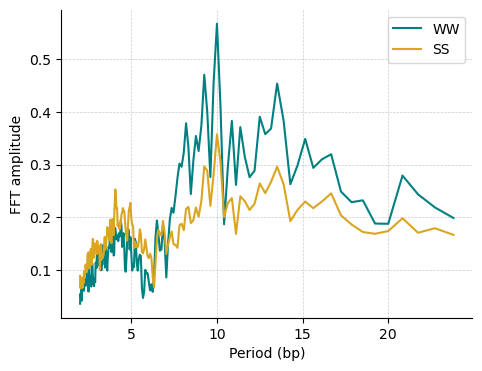

In [151]:
import logomaker

seaborn.reset_orig()

use_wwss_model = False

# WW/SS model
X = data['abs_freqs_5p']  # Trinucleotide frequencies
X = X / (np.sum(X, axis=0)[np.newaxis, :] + 1e-5)
X = X.reshape(4, 4, 4, -1).sum(axis=2)
ww = X[0, 0, :] + X[0, 3, :] + X[3, 0, :] + X[3, 3, :]
ss = X[1, 1, :] + X[1, 2, :] + X[2, 1, :] + X[2, 2, :]


plt.figure(figsize=(4, 4))
f, ax = plt.subplots(1, 1, figsize=(5.3, 4))

l_max = 500
fftfreqs = np.fft.fftfreq(l_max)
periods = 1. / fftfreqs
mask = np.logical_and(periods > 0, periods < 25)
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(ww[:l_max])[mask]), color='teal', label="WW")  # WW
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(ss[:l_max])[mask]), color='goldenrod', label="SS")  # SS
ax.legend()
#ax.axvline(x=10.4, linestyle='--', alpha=0.4, color='grey')
ax.set_xlabel('Period (bp)')
ax.set_ylabel('FFT amplitude')
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.savefig(os.path.join(FIGURES_PATH, 'fft-wwss.png'), dpi=300)
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_3064\170504110.py:30: RuntimeWarning: divide by zero encountered in divide
  periods = 1. / fftfreqs


<Figure size 1200x400 with 0 Axes>

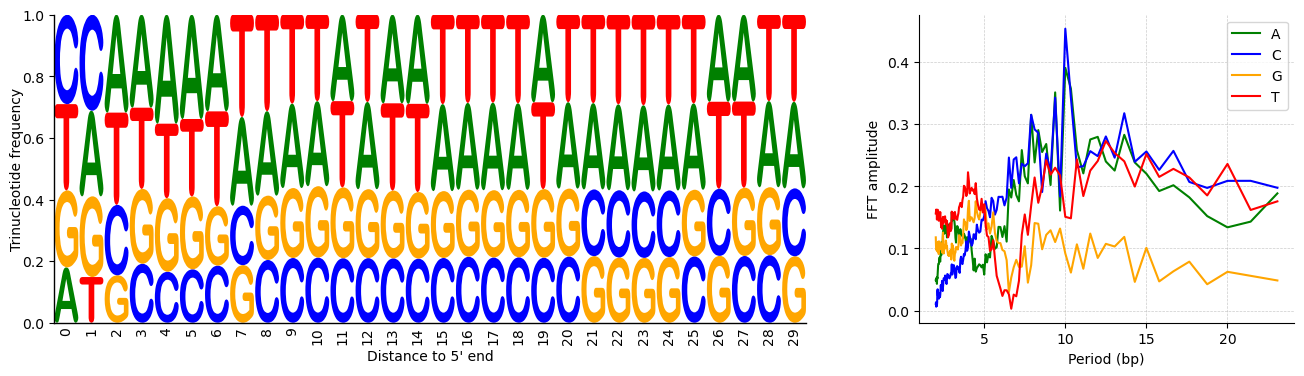

In [140]:
import logomaker

seaborn.reset_orig()

# Mononucleotide model
X = data['abs_freqs_5p']
X = X / (np.sum(X, axis=0)[np.newaxis, :] + 1e-5)
X = X.reshape(4, 16, -1).sum(axis=1)
df = pd.DataFrame(X[:, :30].T, index=np.arange(30), columns=['A', 'C', 'G', 'T'])

plt.figure(figsize=(12, 4))
f, axs = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [2, 1]})

ax = axs[0]
crp_logo = logomaker.Logo(df, ax=ax, shade_below=.5, fade_below=.5, font_name='Arial Rounded MT Bold')
crp_logo.style_spines(visible=False)
crp_logo.style_spines(spines=['left', 'bottom'], visible=True)
crp_logo.style_xticks(rotation=90, fmt='%d', anchor=0)
crp_logo.ax.set_ylabel('Frequency', labelpad=-1)
crp_logo.ax.xaxis.set_ticks_position('none')
crp_logo.ax.xaxis.set_tick_params(pad=-1)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('Distance to 5\' end')
ax.set_ylabel('Trinucleotide frequency')

ax = axs[1]
l_max = 300
fftfreqs = np.fft.fftfreq(l_max)
periods = 1. / fftfreqs
mask = np.logical_and(periods > 0, periods < 25)    
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(X[0, :l_max])[mask]), color='green', label="A")  # A
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(X[1, :l_max])[mask]), color='blue', label="C")  # C
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(X[2, :l_max])[mask]), color='orange', label="G")  # G
ax.plot(1. / fftfreqs[mask], np.abs(np.fft.fft(X[3, :l_max])[mask]), color='red', label="T")  # T
ax.legend()
#ax.axvline(x=10.4, linestyle='--', alpha=0.4, color='grey')
ax.set_xlabel('Period (bp)')
ax.set_ylabel('FFT amplitude')
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.savefig(os.path.join(FIGURES_PATH, 'fft-nucleotides.png'), dpi=300)
plt.show()

<h1 id="heteroscedasticity">MethMarkerDB DMRs</h1> <a class="anchor" id="dmrs"></a>

In [523]:
#dataset = get_dataset('breast')
dataset = get_dataset('colorectal-train')
n_fragments = dataset.data['Library size']

#dataset = load_dataset([os.path.join(DATA_PATH, 'methmarkerdbcolorectal-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET_TRAIN])
#dataset = load_dataset([os.path.join(DATA_PATH, 'downsampled-methmarkerdbcolorectal-noXY', f'{gc_code}.npz') for gc_code in GC_COLORECTAL_DATASET])
#dataset = get_dataset('colorectal-train')

2233 (137, 2233)


C:\Users\antoi\AppData\Local\Temp\ipykernel_6088\497514128.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


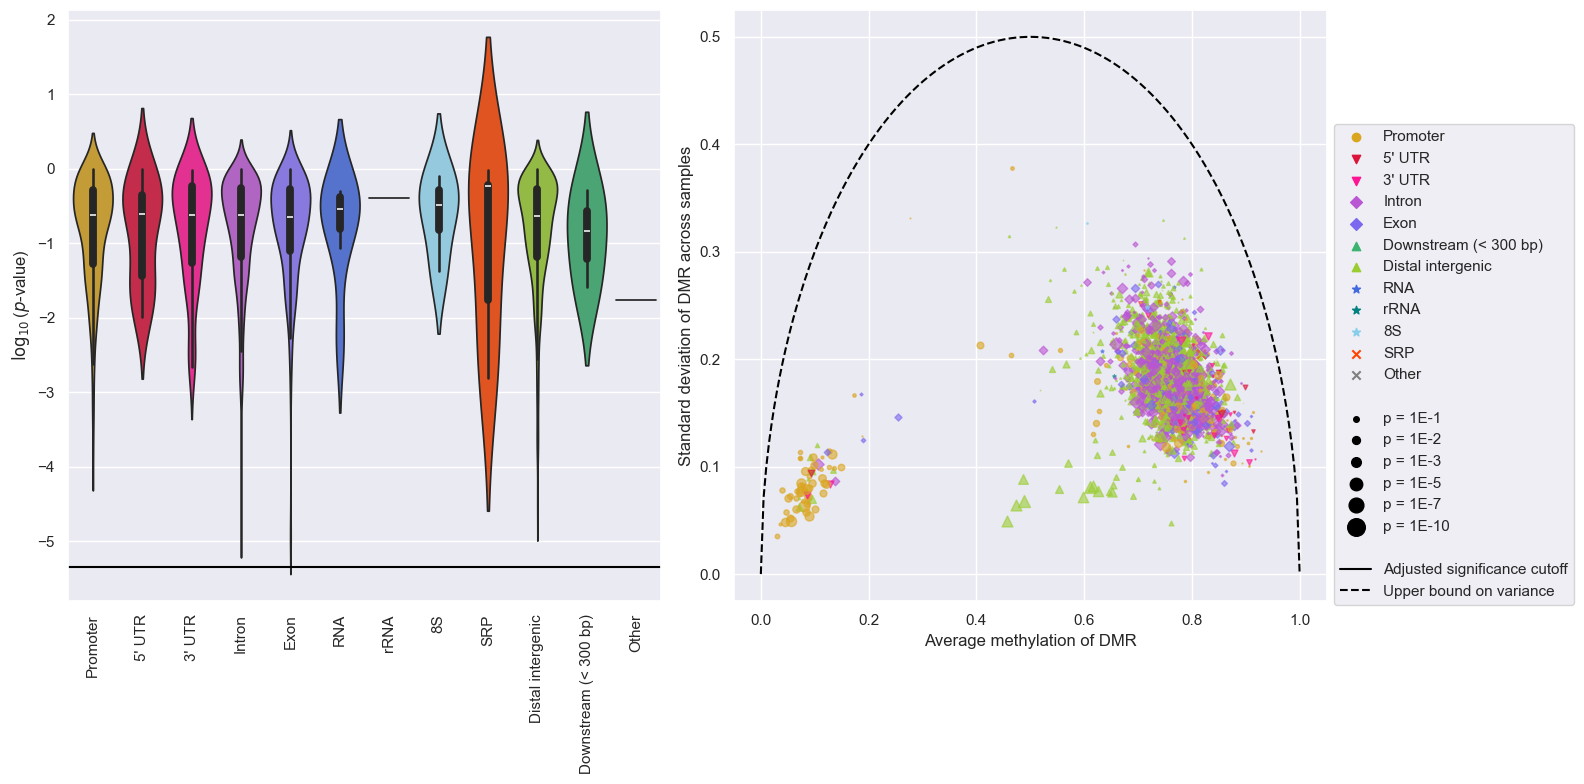

In [524]:
#df = pd.read_csv(os.path.join(ROOT, 'regions/metdecode/dmrs-methmarkerdb-breast.csv'), header=None, names=['chr', 'start', 'end', 'cat'])
df = pd.read_csv(os.path.join(ROOT, 'regions/metdecode/dmrs-methmarkerdb-colorectal.csv'), header=None, names=['chr', 'start', 'end', 'cat'])
categories = np.asarray([name.split('_')[1] for name in df['cat']], dtype=object)
#categories = df['chr']

y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)
X = dataset.data['CpG Methylation (first moment)']
dmr_coverage = np.mean(dataset.data['CpG count'], axis=0)
mu = np.mean(X, axis=0)
mu_cases = np.mean(X[y == 1, :], axis=0)
mu_controls = np.mean(X[y == 0, :], axis=0)
sigma = np.std(X, axis=0)

print(len(df), X.shape)

p_values = f_classif(X, y)[1]
sig_cutoff = 1e-2 / len(p_values)

label_mapping = {key: key for key in ['Promoter', '5\' UTR', '3\' UTR', 'Intron', 'Exon', 'RNA', 'rRNA', '8S', 'SRP']}
label_mapping['Distal intergenic'] = 'Distal Intergenic'
label_mapping['Downstream (< 300 bp)'] = 'Downstream (<=300bp)'
label_mapping['Other'] = '338'
label_reverse_mapping = {key: key for key in ['Promoter', '5\' UTR', '3\' UTR', 'Intron', 'Exon', 'RNA', 'rRNA', '8S', 'SRP']}
label_reverse_mapping['Distal Intergenic'] = 'Distal intergenic'
label_reverse_mapping['Downstream (<=300bp)'] = 'Downstream (< 300 bp)'
label_reverse_mapping['338'] = 'Other'
label_reverse_mapping['exon4'] = 'Exon'
style_dict = {
    'Promoter': ('goldenrod', 'o'),
    '5\' UTR': ('crimson', 'v'),
    '3\' UTR': ('deeppink', 'v'),
    'Intron': ('mediumorchid', 'D'),
    'Exon': ('mediumslateblue', 'D'),
    'exon4': ('mediumslateblue', 'D'),
    'Downstream (<=300bp)': ('mediumseagreen', '^'),
    'Distal Intergenic': ('yellowgreen', '^'),
    'RNA': ('royalblue', '*'),
    'rRNA': ('teal', '*'),
    '8S': ('skyblue', '*'),
    'SRP': ('orangered', 'x'),
    '338': ('gray', 'x'),
}
unique_labels = ['Promoter', '5\' UTR', '3\' UTR', 'Intron', 'Exon', 'Downstream (< 300 bp)', 'Distal intergenic', 'RNA', 'rRNA', '8S', 'SRP', 'Other']
idx = np.arange(len(mu))
np.random.shuffle(idx)
p_value_to_size = lambda p_value: 7 * (-np.log(p_value))

seaborn.set_theme()
plt.figure(figsize=(16, 8))
ax = plt.subplot(1, 2, 1)
palette = {label: style_dict[label_mapping[label]][0] for label in unique_labels}
xs = [label_reverse_mapping[label] for label in categories]
seaborn.violinplot(ax=ax, x=xs, y=np.log10(p_values), hue=xs, palette=palette, legend=False, order=list(label_mapping.keys()))
ax.axhline(y=np.log10(sig_cutoff), color='black', linestyle='-')
ax.set_ylabel(r'$\log_{10}$($p$-value)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

ax = plt.subplot(1, 2, 2)
for i in idx:
    size = p_value_to_size(p_values[i])
    color, marker = style_dict[categories[i]]
    ax.scatter(mu[i], sigma[i], alpha=0.6, marker=marker, c=color, s=size)
xs = np.linspace(0, 1, 200)
ys = np.sqrt(xs * (1 - xs))
ax.plot(xs, ys, color='black', linestyle='--')
handles, labels = [], []
for label in unique_labels:
    color, marker = style_dict[label_mapping[label]]
    handles.append(plt.scatter([], [], color=color, marker=marker))
    labels.append(label)
handles.append(plt.scatter([], [], s=0))
labels.append('')
for p_value in [1e-1, 1e-2, 1e-3, 1e-5, 1e-7, 1e-10]:
    size = p_value_to_size(p_value)
    handles.append(plt.scatter([], [], color='black', marker='o', s=size))
    labels.append(f'p = {decimal.Decimal(p_value):.0E}')
handles.append(plt.scatter([], [], s=0))
labels.append('')
handles.append(plt.Line2D([], [], color='black', linestyle='-'))
labels.append('Adjusted significance cutoff')
handles.append(plt.Line2D([], [], color='black', linestyle='--'))
labels.append('Upper bound on variance')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.4), handles=handles, labels=labels)
ax.set_xlabel('Average methylation of DMR')
ax.set_ylabel('Standard deviation of DMR across samples')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'dmrs-scatter-plot-by-category-breast.png'), dpi=300)
plt.show()

In [46]:
df[p_values < 0.0001]

,chr,start,end,cat
345,4,43903013,43908145,NDUFB4P12_Distal Intergenic
356,4,49096109,49108316,CWH43_Distal Intergenic
642,7,69213467,69218623,AC069280.1_Distal Intergenic
1010,10,2367485,2373126,LINC00701_Distal Intergenic
1062,10,41877254,41891244,KSR1P1_Distal Intergenic
1632,16,25968327,25978112,MIR548W_Intron
1976,20,42279372,42286557,PTPRT_3' UTR


<h1 id="mkl">Multiple kernel learning</h1> <a class="anchor" id="mkl"></a>

In [25]:
dataset = get_dataset('colorectal-train', downsampled=True)

In [65]:
ALL_MODALITIES = [Modalities.NUCLEOSOME_POSITIONING, Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.FULLY_METH_FRAG, Modalities.COVERAGE, Modalities.CAFF, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]

extractor = KernelMatrixExtractor(ALL_MODALITIES, mod_options={"probabilistic": True})
Ks = extractor.fit_transform(dataset.data, y=dataset.y)

### Unsupervised

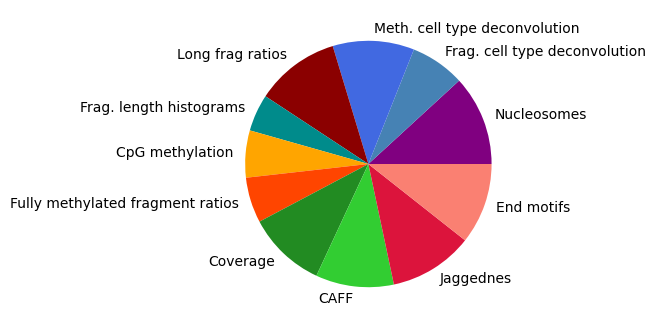

In [66]:
mkl = MultipleKernelLearning(supervised=False)
mkl.fit(Ks, dataset.y)
weights = mkl.weights

plt.figure(figsize=(6.7, 4))
labels = ['Nucleosomes', 'Frag. cell type deconvolution', 'Meth. cell type deconvolution', 'Long frag ratios', 'Frag. length histograms', 'CpG methylation', 'Fully methylated fragment ratios', 'Coverage', 'CAFF', 'Jaggednes', 'End motifs']
colors = ['purple', 'steelblue', 'royalblue', 'darkred', 'darkcyan', 'orange', 'orangered', 'forestgreen', 'limegreen', 'crimson', 'salmon']
plt.pie(weights, labels=labels, colors=colors)
plt.savefig(os.path.join(FIGURES_PATH, 'mkl-weights-unsupervised.png'), dpi=300)
plt.show()

### Supervised

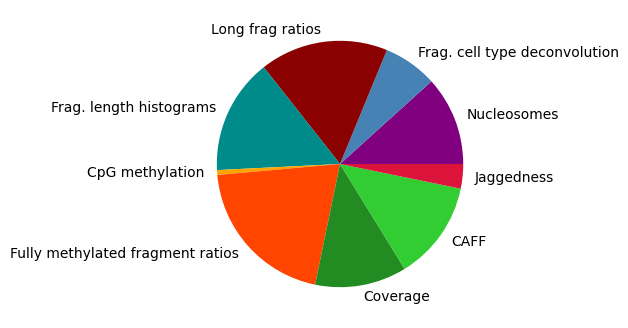

In [70]:
mkl = MultipleKernelLearning(supervised=True)
mkl.fit(Ks, dataset.y)
weights = mkl.weights

plt.figure(figsize=(6.7, 4))
labels = np.array(['Nucleosomes', 'Frag. cell type deconvolution', 'Meth. cell type deconvolution', 'Long frag ratios', 'Frag. length histograms', 'CpG methylation', 'Fully methylated fragment ratios', 'Coverage', 'CAFF', 'Jaggedness', 'End motifs'])
colors = np.array(['purple', 'steelblue', 'royalblue', 'darkred', 'darkcyan', 'orange', 'orangered', 'forestgreen', 'limegreen', 'crimson', 'salmon'])
mask = (weights > 1e-3)
plt.pie(weights[mask], labels=labels[mask], colors=colors[mask])
plt.savefig(os.path.join(FIGURES_PATH, 'mkl-weights-supervised.png'), dpi=300)
plt.show()

## Train/test on colorectal cancer dataset

In [40]:
dataset_train = get_dataset('colorectal-train', downsampled=True)
dataset_test = get_dataset('colorectal-test', downsampled=True)

In [50]:
from modalibpy.pipeline.pipeline import Pipeline


ALL_MODALITIES = [Modalities.NUCLEOSOME_POSITIONING, Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.FULLY_METH_FRAG, Modalities.COVERAGE, Modalities.CAFF, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]

settings = [
    ([Modalities.NUCLEOSOME_POSITIONING], 'Nucleosomes', 'purple', ':', False),
    ([Modalities.FRAG_CELL_TYPE_DECONVOLUTION], 'Frag. cell type deconvolution', 'steelblue', '--', False),
    ([Modalities.METH_CELL_TYPE_DECONVOLUTION], 'Meth. cell type deconvolution', 'royalblue', '-', False),
    ([Modalities.LONG_FRAG_RATIO], 'Long frag. ratios', 'darkred', '-.', False),
    ([Modalities.FRAG_LENGTH_COUNTS], 'Frag. length histograms', 'darkcyan', ':', False),
    ([Modalities.CPG_METHYLATION], 'CpG methylation', 'orange', '--', False),
    ([Modalities.FULLY_METH_FRAG], 'Fully methylated frag. ratios', 'orangered', '--', False),
    ([Modalities.COVERAGE], 'Coverage', 'forestgreen', '-.', False),
    ([Modalities.CAFF], 'CAFF', 'limegreen', '-.', False),
    ([Modalities.JAGGEDNESS], 'Jaggedness', 'crimson', ':', False),
    ([Modalities.END_MOTIFS], 'End motifs', 'salmon', '--', False),
    (ALL_MODALITIES, 'MKL (unsupervised)', 'black', '--', False),
    (ALL_MODALITIES, 'MKL (supervised)', 'black', '-', True)
]

for model_name in ['svm-reimpl', 'stage-svm', 'carsvm']:
    print()
    print(model_name)
    for kernel_idx, label, color, linestyle, supervised_mkl in settings:
    
        pipeline = Pipeline(kernel_idx, model_name=model_name, supervised_mkl=supervised_mkl, mod_options={"probabilistic": True, "cache": True})
        pipeline.fit(dataset_train)
    
        y_pred = pipeline.predict_proba(dataset_test)[:, 1]
        y_target = dataset_test.y
    
        auc = roc_auc_score(y_target, y_pred)
        roc = roc_curve(y_target, y_pred)
        pr = precision_recall_curve(y_target, y_pred)
        aupr = average_precision_score(y_target, y_pred)
        print(label, auc)
    
        os.makedirs(os.path.join(PREDICTIONS_PATH, "colca", model_name), exist_ok=True)
        with open(os.path.join(PREDICTIONS_PATH, "colca", model_name, f"{label}.json"), 'w') as f:
            data = {
                "y-pred": [float(x) for x in y_pred],
                "y": [int(x) for x in dataset_test.y],
                "stage": [float(annot) for annot in dataset_test.annotations],
                "auroc": float(auc),
                "aupr": float(aupr),
                "roc": [[float(x) for x in roc[0]], [float(x) for x in roc[1]]],
                "pr": [[float(x) for x in pr[0]], [float(x) for x in pr[1]]],
            }
            json.dump(data, f)


svm-reimpl
before [[1.         0.14318139 0.78968478 ... 0.12036612 0.43827508 0.88769412]
 [0.14318139 1.         0.37044819 ... 0.89879923 0.73385771 0.30053423]
 [0.78968478 0.37044819 1.         ... 0.29443518 0.70481946 0.92106473]
 ...
 [0.12036612 0.89879923 0.29443518 ... 1.         0.718051   0.25819029]
 [0.43827508 0.73385771 0.70481946 ... 0.718051   1.         0.68028101]
 [0.88769412 0.30053423 0.92106473 ... 0.25819029 0.68028101 1.        ]]
after [[1.         0.14318139 0.78968478 ... 0.12036612 0.43827508 0.88769412]
 [0.14318139 1.         0.37044819 ... 0.89879923 0.73385771 0.30053423]
 [0.78968478 0.37044819 1.         ... 0.29443518 0.70481946 0.92106473]
 ...
 [0.12036612 0.89879923 0.29443518 ... 1.         0.718051   0.25819029]
 [0.43827508 0.73385771 0.70481946 ... 0.718051   1.         0.68028101]
 [0.88769412 0.30053423 0.92106473 ... 0.25819029 0.68028101 1.        ]]
Nucleosomes 0.8338992642897567
before [[1.         0.39220232 0.26161839 ... 0.41977637

KeyboardInterrupt: 

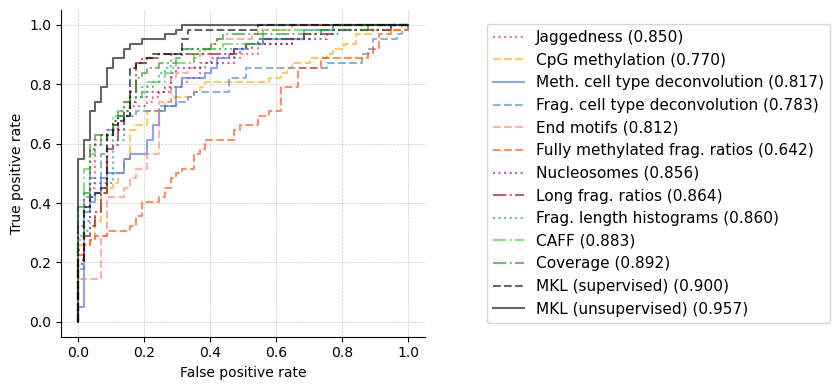

In [43]:
settings = [
    ([Modalities.JAGGEDNESS], 'Jaggedness', 'crimson', ':', False),
    ([Modalities.CPG_METHYLATION], 'CpG methylation', 'orange', '--', False),
    ([Modalities.METH_CELL_TYPE_DECONVOLUTION], 'Meth. cell type deconvolution', 'royalblue', '-', False),
    ([Modalities.FRAG_CELL_TYPE_DECONVOLUTION], 'Frag. cell type deconvolution', 'steelblue', '--', False),
    ([Modalities.END_MOTIFS], 'End motifs', 'salmon', '-', False),
    ([Modalities.FULLY_METH_FRAG], 'Fully methylated frag. ratios', 'orangered', '--', False),
    ([Modalities.NUCLEOSOME_POSITIONING], 'Nucleosomes', 'purple', ':', False),
    ([Modalities.LONG_FRAG_RATIO], 'Long frag. ratios', 'darkred', '-.', False),
    ([Modalities.FRAG_LENGTH_COUNTS], 'Frag. length histograms', 'darkcyan', ':', False),
    ([Modalities.CAFF], 'CAFF', 'limegreen', '-.', False),
    ([Modalities.COVERAGE], 'Coverage', 'forestgreen', '-.', False),
    (ALL_MODALITIES, 'MKL (supervised)', 'black', '--', True),
    (ALL_MODALITIES, 'MKL (unsupervised)', 'black', '-', False),
    
]

seaborn.reset_orig()
fig, ax = plt.subplots(1, 1, figsize=(9, 4))

for kernel_idx, label, color, linestyle, supervised_mkl in settings:
    with open(os.path.join(PREDICTIONS_PATH, "colca", "stage-svm", f"{label}.json"), 'r') as f:
        data = json.load(f)
    roc = data['roc']
    pr = data['pr']
    auc = data['auroc']
    aupr = data['aupr']

    ax.plot(roc[0], roc[1], alpha=0.6, label=f'{label} ({auc:.3f})', color=color, linestyle=linestyle)

# plt.tight_layout()
ax.legend(prop={'size': 11}, loc='center left', bbox_to_anchor=(1.15, 0.5))
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, 'colca-perf.png'), dpi=300)
plt.show()

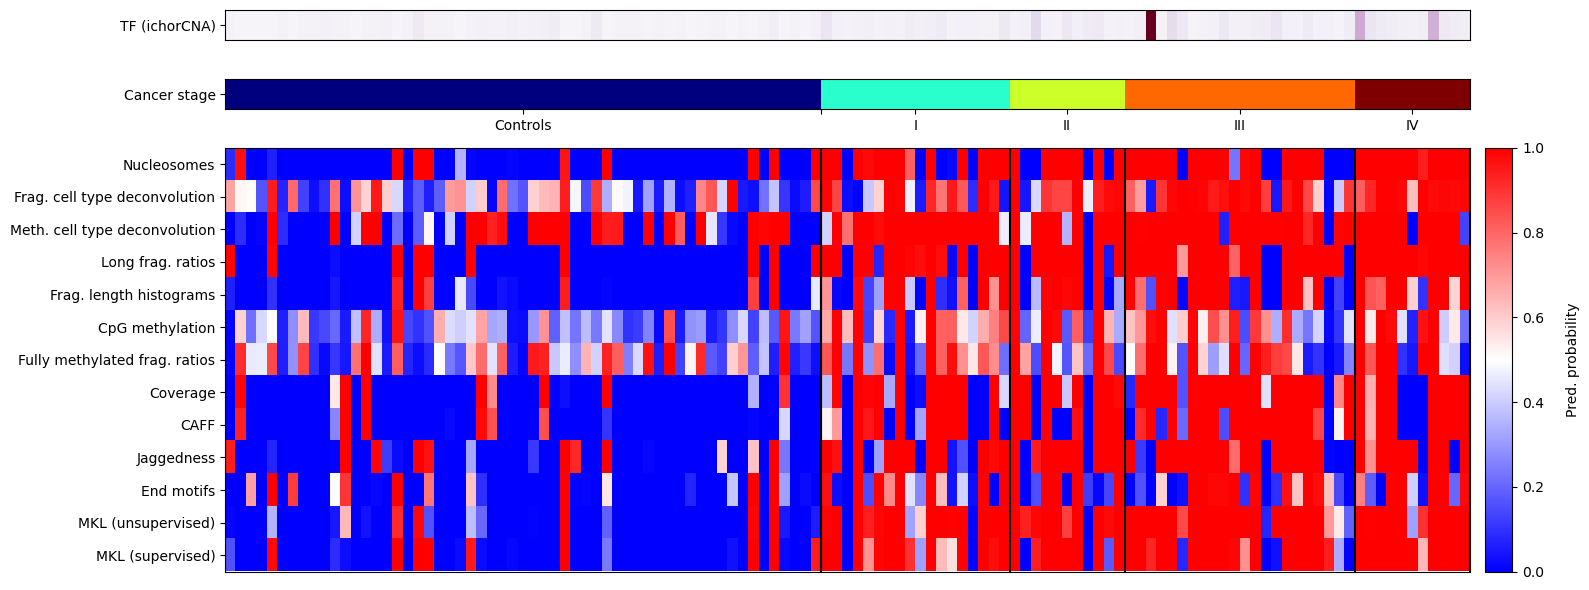

In [71]:
settings = [
    ([Modalities.NUCLEOSOME_POSITIONING], 'Nucleosomes', 'purple', ':', False),
    ([Modalities.FRAG_CELL_TYPE_DECONVOLUTION], 'Frag. cell type deconvolution', 'steelblue', '--', False),
    ([Modalities.METH_CELL_TYPE_DECONVOLUTION], 'Meth. cell type deconvolution', 'royalblue', '-', False),
    ([Modalities.LONG_FRAG_RATIO], 'Long frag. ratios', 'darkred', '-.', False),
    ([Modalities.FRAG_LENGTH_COUNTS], 'Frag. length histograms', 'darkcyan', ':', False),
    ([Modalities.CPG_METHYLATION], 'CpG methylation', 'orange', '--', False),
    ([Modalities.FULLY_METH_FRAG], 'Fully methylated frag. ratios', 'orangered', '--', False),
    ([Modalities.COVERAGE], 'Coverage', 'forestgreen', '-.', False),
    ([Modalities.CAFF], 'CAFF', 'limegreen', '-.', False),
    ([Modalities.JAGGEDNESS], 'Jaggedness', 'crimson', ':', False),
    ([Modalities.END_MOTIFS], 'End motifs', 'salmon', '--', False),
    (ALL_MODALITIES, 'MKL (unsupervised)', 'black', '--', False),
    (ALL_MODALITIES, 'MKL (supervised)', 'black', '-', True)
]

dataset = dataset_test

annotations = dataset.annotations
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

mat = []
for kernel_idx, label, color, linestyle, supervised_mkl in settings:

    filepath = os.path.join(PREDICTIONS_PATH, "colca", "stage-svm", f"{label}.json")

    with open(filepath, 'r') as f:
        results = json.load(f)

    y_pred = results["y-pred"]

    mat.append(y_pred)
mat = np.asarray(mat)

idx = []
idx.append(np.where(np.asarray([(not annot.is_cancer) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 0)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 1)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 2)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 3)) for annot in dataset.annotations], dtype=bool))[0])
idx.append(np.where(np.asarray([(annot.is_cancer and (float(annot) == 4)) for annot in dataset.annotations], dtype=bool))[0])
#idx.append(np.where(np.asarray([(annot.is_cancer and np.isnan(float(annot))) for annot in dataset.annotations], dtype=bool))[0])
lengths = [len(x) for x in idx]
bounds = np.asarray([0] + list(np.cumsum(lengths)))
idx = np.concatenate(idx, axis=0)

f, axs = plt.subplots(3, 2, height_ratios=(0.5, 0.5, 7), width_ratios=(9, 0.2), figsize=(16, 6))

ax = axs[0, 0]
ys = np.nan_to_num(dataset.ichor[idx])
ax.imshow(ys[np.newaxis, :], aspect='auto', interpolation='none', cmap='PuRd')
ax.set_yticks([0])
ax.set_yticklabels(['TF (ichorCNA)'])
ax.set_xticks([])
ax.set_xticklabels([])

ax = axs[0, 1]
ax.set_axis_off()

ax = axs[1, 0]
ys = np.concatenate([np.asarray([i] * length) for i, length in enumerate(lengths)], axis=0)
ax.imshow(ys[np.newaxis, :], aspect='auto', interpolation='none', cmap='jet')
ax.set_yticks([0])
ax.set_yticklabels(['Cancer stage'])
ax.set_xticks(0.5 * (bounds[1:] + bounds[:-1]) - 0.5)
ax.set_xticklabels(['Controls', '', 'I', 'II', 'III', 'IV'])

ax = axs[1, 1]
ax.set_axis_off()

ax = axs[2, 0]
im = ax.imshow(mat[:, :], aspect='auto', interpolation='none', cmap='bwr', vmin=0, vmax=1)
for pos in bounds:
    ax.axvline(pos - 0.5, color='black')
ax.set_yticks(range(len(settings)))
ax.set_yticklabels([setting[1] for setting in settings])
ax.set_xticks([])
ax.set_xticklabels([])

ax = axs[2, 1]
f.colorbar(
    im,
    cax=ax, orientation='vertical', label='\nPred. probability',
    location='right',
)
#cb = plt.colorbar(im)
#cb.set_label('\nPred. probability')

plt.tight_layout()

plt.savefig(os.path.join(FIGURES_PATH, 'colca-raw-pred-heatmap.png'), dpi=300)

plt.show()

## Successive removal of modalities

In [56]:
ALL_MODALITIES = [Modalities.NUCLEOSOME_POSITIONING, Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.FULLY_METH_FRAG, Modalities.COVERAGE, Modalities.CAFF, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]
dataset_train = get_dataset('colorectal-train', downsampled=True)
dataset_test = get_dataset('colorectal-test', downsampled=True)

In [57]:
extractor = KernelMatrixExtractor(ALL_MODALITIES, mod_options={'probabilistic': True})
extractor.preprocess(dataset_train.data, fit=True)
Ks_train = extractor.fit_transform(dataset_train.data, dataset_train.y)
extractor.preprocess(dataset_test.data, fit=False)
Ks_test = extractor.transform(dataset_test.data)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:21<00:00, 91.86it/s]


In [76]:
len(ALL_MODALITIES)

11

In [87]:
from modalibpy.svm import SVM, MultiStageSVM, CARSVM


#NUCLEOSOME_POSITIONING, FRAG_CELL_TYPE_DECONVOLUTION, METH_CELL_TYPE_DECONVOLUTION, LONG_FRAG_RATIO, FRAG_LENGTH_COUNTS, CPG_METHYLATION, FULLY_METH_FRAG, COVERAGE, CAFF, JAGGEDNESS, END_MOTIFS

MASKS = np.array([
    [1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1],
    [1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1],
    [0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0],
    [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1],
    [1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1],
    [0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0],
    [1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1],
    [1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
], dtype=bool)
settings_names = [
    "No frag. cell type deconvolution",
    "No fully meth. fragments",
    "No coverage",
    "None of the 3 above",
    "No fragmentomics",
    "Fragmentomics only",
    "No CAFF or coverage",
    "Methylation unavailable",
    "Methylation unavailable, no fragmentomics",
    "Methylation unavailable, fragmentomics only",
    "No modality with negative OLS coefficient",
    "All modalities"
]


y_train = dataset_train.y

all_predictions = []
for k in range(len(MASKS)):

    # Multiple kernel learning
    mask = MASKS[k, :]
    mkl = MultipleKernelLearning(supervised=False)
    K_train = mkl.fit_transform(Ks_train[mask, :, :], y=y_train)
    K_test = mkl.transform(Ks_test[mask, :, :])

    # Fit model on training set
    C = 1
    model = MultiStageSVM(C=C, C_aux=C, platt_scaling=False, random_state=0xCAFE)
    model.fit(K_train, dataset_train.annotations)
    
    # Evaluate model on test set
    y_pred = model.predict_proba(K_test)[:, 1]
    all_predictions.append(y_pred)

for k in range(len(all_predictions)):
    _, p_value = MLstatkit.stats.Delong_test(dataset_test.y, all_predictions[-1], all_predictions[k])
    auroc = roc_auc_score(dataset_test.y, all_predictions[k])
    markers = ['\\faCheck' if MASKS[k, l] else '-' for l in range(MASKS.shape[1])]
    print(f"{settings_names[k]} & {' & '.join(markers)} & {auroc:.3f} & {p_value:.5f} \\\\")

No frag. cell type deconvolution & \faCheck & - & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & 0.959 & 0.16993 \\
No fully meth. fragments & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & - & \faCheck & \faCheck & \faCheck & \faCheck & 0.957 & 1.00000 \\
No coverage & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & - & \faCheck & \faCheck & \faCheck & 0.943 & 0.00935 \\
None of the 3 above & \faCheck & - & \faCheck & \faCheck & \faCheck & \faCheck & - & - & \faCheck & \faCheck & \faCheck & 0.943 & 0.04915 \\
No fragmentomics & - & - & \faCheck & - & - & \faCheck & \faCheck & \faCheck & \faCheck & - & - & 0.899 & 0.02564 \\
Fragmentomics only & \faCheck & \faCheck & - & \faCheck & \faCheck & - & - & - & - & \faCheck & \faCheck & 0.898 & 0.00098 \\
No CAFF or coverage & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & \faCheck & - & - & \faCheck & \faCheck & 0.916 & 0.00

C:\Users\antoi\anaconda3\Lib\site-packages\MLstatkit\stats.py:85: RuntimeWarning: invalid value encountered in divide
  z = np.abs(np.diff(aucs)) / np.sqrt(np.dot(np.dot(l, delongcov), l.T)).flatten()


## Benchmarking

In [60]:
with open(os.path.join(PREDICTIONS_PATH, 'colca', 'ichorcna.json'), 'w') as f:
    y_target = dataset_test.y
    y_pred = dataset_test.ichor
    mask = ~np.isnan(y_pred)
    auc = roc_auc_score(y_target[mask], y_pred[mask])
    roc = roc_curve(y_target[mask], y_pred[mask])
    pr = precision_recall_curve(y_target[mask], y_pred[mask])
    aupr = average_precision_score(y_target[mask], y_pred[mask])
    data = {
        "y-pred": [float(x) if (not np.isnan(x)) else None for x in y_pred],
        "y": [int(x) for x in y_target],
        "stage": [float(np.nan_to_num(float(annot), nan=-1)) for annot in annotations],
        "auroc": float(auc),
        "aupr": float(aupr)
    }
    json.dump(data, f)

In [61]:
with open(os.path.join(PREDICTIONS_PATH, 'colca', 'tf-nn.json'), 'w') as f:
    y_target = dataset_test.y
    y_pred = dataset_test.tf
    mask = ~np.isnan(y_pred)
    auc = roc_auc_score(y_target[mask], y_pred[mask])
    roc = roc_curve(y_target[mask], y_pred[mask])
    pr = precision_recall_curve(y_target[mask], y_pred[mask])
    aupr = average_precision_score(y_target[mask], y_pred[mask])
    data = {
        "y-pred": [float(x) if (not np.isnan(x)) else None for x in y_pred],
        "y": [int(x) for x in y_target],
        "stage": [float(np.nan_to_num(float(annot), nan=-1)) for annot in annotations],
        "auroc": float(auc),
        "aupr": float(aupr)
    }
    json.dump(data, f)

In [62]:
from sklearn.ensemble import RandomForestClassifier


class THEMIS(object):

    def __init__(self):
        self.models = {key: None for key in ['MFR', 'FSI', 'CAFF', 'FEM']}

    def extract_features(self, gc_codes: List[str]) -> Dict[str, np.ndarray]:

        # Load data
        dataset_cin = load_dataset([os.path.join(DATA_PATH, 'themis-cin', f'{gc_code}.npz') for gc_code in gc_codes])
        dataset_fsn = load_dataset([os.path.join(DATA_PATH, 'themis-fsi', f'{gc_code}.npz') for gc_code in gc_codes])
        dataset_mfr = load_dataset([os.path.join(DATA_PATH, 'themis-mfr', f'{gc_code}.npz') for gc_code in gc_codes])

        # End motifs
        X = dataset_cin.data['End-motif probability (THEMIS)']
        X = X / np.sum(X, axis=1)[:, np.newaxis]
        features = {'FEM': X}

        # Fragment size index
        X = np.clip(dataset_cin.data['Proportion of long fragments'], 0.01, 0.99)
        features['FSI'] = X / (1 - X)

        # CAFF
        X = dataset_cin.data['CAFF']
        X = X / np.median(X, axis=1)[:, np.newaxis]
        features['CAFF'] = X

        # CpG methylation
        X = dataset_mfr.data['Fully methylated fragment ratio']
        features['MFR'] = X

        return features

    def fit(self, gc_codes: List[str]) -> 'THEMIS':
        dataset = load_dataset([os.path.join(DATA_PATH, 'themis-cin', f'{gc_code}.npz') for gc_code in gc_codes])
        y = np.array([annot.is_cancer for annot in dataset.annotations], dtype=int)
        features = self.extract_features(gc_codes)
        for key in features.keys():
            self.models[key] = RandomForestClassifier(n_estimators=2000)
            self.models[key].fit(features[key], y)
        return self

    def predict_proba(self, gc_codes: List[str]) -> np.ndarray:
        predictions = {}
        features = self.extract_features(gc_codes)
        for key in features.keys():
            predictions[key] = self.models[key].predict_proba(features[key])[:, 1]
        y_logit = 0.57 + 0.33 * predictions['MFR'] + 0.34 * predictions['FSI']
        y_logit += 0.06 * predictions['CAFF'] + 0.58 * predictions['FEM']
        return scipy.special.expit(y_logit)


themis = THEMIS()
themis.fit(GC_COLORECTAL_DATASET_TRAIN)
y_pred = themis.predict_proba(GC_COLORECTAL_DATASET_TEST)
with open(os.path.join(PREDICTIONS_PATH, 'colca', 'themis.json'), 'w') as f:
    y_target = dataset_test.y
    mask = ~np.isnan(y_pred)
    auc = roc_auc_score(y_target[mask], y_pred[mask])
    roc = roc_curve(y_target[mask], y_pred[mask])
    pr = precision_recall_curve(y_target[mask], y_pred[mask])
    aupr = average_precision_score(y_target[mask], y_pred[mask])
    data = {
        "y-pred": [float(x) if (not np.isnan(x)) else None for x in y_pred],
        "y": [int(x) for x in y_target],
        "stage": [float(np.nan_to_num(float(annot), nan=-1)) for annot in annotations],
        "auroc": float(auc),
        "aupr": float(aupr)
    }
    json.dump(data, f)

In [63]:
import shutil

for model_name in ['svm-reimpl', 'stage-svm', 'carsvm']:
    shutil.copyfile(
        os.path.join(PREDICTIONS_PATH, "colca", model_name, f"MKL (unsupervised).json"),
        os.path.join(PREDICTIONS_PATH, "colca", f"{model_name}.json")
    )

In [64]:
import MLstatkit.stats

with open(os.path.join(PREDICTIONS_PATH, "colca", f"stage-svm.json"), 'r') as f:
    data = json.load(f)
    best_pred = np.array(data['y-pred'])

for method_name in ['ichorcna', 'themis', 'tf-nn', 'svm-reimpl', 'carsvm', 'stage-svm']:
    with open(os.path.join(PREDICTIONS_PATH, "colca", f"{method_name}.json"), 'r') as f:
        data = json.load(f)
        auroc = data['auroc']
        aupr = data['aupr']
        y_target = np.array(data['y'])
        y_pred = np.array(data['y-pred'])

        mask = ~np.asarray([x is None for x in y_pred])
        
        _, p_value = MLstatkit.stats.Delong_test(y_target[mask], best_pred[mask], y_pred[mask])
        print(f"{method_name}, AUPR={aupr:.3f}, AUROC={auroc:.3f}, p-value={p_value}")

ichorcna, AUPR=0.854, AUROC=0.826, p-value=0.0004645165290318245
themis, AUPR=0.902, AUROC=0.884, p-value=0.0022543141385044903
tf-nn, AUPR=0.776, AUROC=0.784, p-value=1.7438990631351725e-06
svm-reimpl, AUPR=0.914, AUROC=0.906, p-value=0.00012156751829093405
carsvm, AUPR=0.923, AUROC=0.909, p-value=0.0006419953196299707
stage-svm, AUPR=0.960, AUROC=0.957, p-value=nan


C:\Users\antoi\anaconda3\Lib\site-packages\MLstatkit\stats.py:85: RuntimeWarning: invalid value encountered in divide
  z = np.abs(np.diff(aucs)) / np.sqrt(np.dot(np.dot(l, delongcov), l.T)).flatten()


## Assessing the added value of each design choice using a linear model

In [14]:
#ALL_MODALITIES = [Modalities.CPG_METHYLATION]
ALL_MODALITIES = [Modalities.NUCLEOSOME_POSITIONING, Modalities.FRAG_CELL_TYPE_DECONVOLUTION, Modalities.METH_CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.FULLY_METH_FRAG, Modalities.COVERAGE, Modalities.CAFF, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]
dataset_train = get_dataset('colorectal-train', downsampled=True)
dataset_test = get_dataset('colorectal-test', downsampled=True)

In [15]:
extractor = KernelMatrixExtractor(ALL_MODALITIES, mod_options={'probabilistic': False})
extractor.preprocess(dataset_train.data, fit=True)
Ks_train = extractor.fit_transform(dataset_train.data)
extractor.preprocess(dataset_test.data, fit=False)
Ks_test = extractor.transform(dataset_test.data)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:24<00:00, 81.33it/s]


In [54]:
extractor = KernelMatrixExtractor(ALL_MODALITIES, mod_options={'probabilistic': True})
extractor.preprocess(dataset_train.data, fit=True)
Ksp_train = extractor.fit_transform(dataset_train.data)
extractor.preprocess(dataset_test.data, fit=False)
Ksp_test = extractor.transform(dataset_test.data)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:23<00:00, 86.18it/s]


In [38]:
from modalibpy.svm import SVM, MultiStageSVM, CARSVM
from modalibpy.pipeline.mkl import MultipleKernelLearning

y_train = dataset_train.y

column_names = [str(s).split('.')[1] for s in ALL_MODALITIES]
column_names += ["Probabilistic", "Model_CARSVM", "Model_StageSVM", "SupervisedMKL", "Score"]
data = {name: [] for name in column_names}

for _ in tqdm.tqdm(range(200)):
    for probabilistic in [False, True]:
        for supervised_mkl in [False, True]:
            for model_name in ["svm-reimpl", "carsvm", "stage-svm"]:
            
                # Select random combination of modalitiespip 
                idx = np.arange(len(ALL_MODALITIES))
                np.random.shuffle(idx)
                n_selected = random.randint(1, len(ALL_MODALITIES))
                idx = idx[:n_selected]
                mask = np.zeros(len(ALL_MODALITIES), dtype=bool)
                mask[idx] = True
                idx = [ALL_MODALITIES[i] for i in idx]
            
                # Multiple kernel learning
                
                mkl = MultipleKernelLearning(supervised=supervised_mkl)
                if probabilistic:
                    K_train = mkl.fit_transform(Ksp_train[mask, :, :], y=y_train)
                    K_test = mkl.transform(Ksp_test[mask, :, :])
                else:
                    K_train = mkl.fit_transform(Ks_train[mask, :, :], y=y_train)
                    K_test = mkl.transform(Ks_test[mask, :, :])
            
                # Fit model on training set
                C = 1
                if model_name == 'stage-svm':
                    model = MultiStageSVM(C=C, C_aux=C, platt_scaling=False)
                    model.fit(K_train, dataset_train.annotations)
                elif model_name == 'svm-reimpl':
                    model = SVM(C=C, platt_scaling=False)
                    model.fit(K_train, y_train)
                elif model_name == 'carsvm':
                    model = CARSVM(C_c=C, C_r=0.05*C, epsilon=0.5, platt_scaling=False)
                    tf_train = dataset_train.tf
                    model.fit(K_train, np.asarray([y_train, tf_train]).T)
                else:
                    raise NotImplementedError(f'Unknown model "{model_name}"')
                
                # Evaluate model on test set
                y_pred = model.predict_proba(K_test)[:, 1]
                auroc = roc_auc_score(dataset_test.y, y_pred)
            
                # Store hyper-parameters and results
                for i in range(len(mask)):
                    data[str(ALL_MODALITIES[i]).split(".")[1]].append(bool(mask[i]))
                data["Probabilistic"].append(probabilistic)
                data["Model_CARSVM"].append(model_name == "carsvm")
                data["Model_StageSVM"].append(model_name == "stage-svm")
                data["SupervisedMKL"].append(supervised_mkl)
                data["Score"].append(auroc)

100%|████████████████████████████████████████████████████████████████████████████████| 200/200 [09:07<00:00,  2.74s/it]


In [39]:
import statsmodels.formula.api

df = pd.DataFrame(data)

exog_variables = column_names[:-1]
formula = f'Score ~ {" + ".join(exog_variables)}'
print(formula)

model = statsmodels.formula.api.ols(formula=formula, data=df)
results = model.fit()
print(results.summary())

Score ~ NUCLEOSOME_POSITIONING + FRAG_CELL_TYPE_DECONVOLUTION + METH_CELL_TYPE_DECONVOLUTION + LONG_FRAG_RATIO + FRAG_LENGTH_COUNTS + CPG_METHYLATION + FULLY_METH_FRAG + COVERAGE + CAFF + JAGGEDNESS + END_MOTIFS + Probabilistic + Model_CARSVM + Model_StageSVM + SupervisedMKL
                            OLS Regression Results                            
Dep. Variable:                  Score   R-squared:                       0.255
Model:                            OLS   Adj. R-squared:                  0.250
Method:                 Least Squares   F-statistic:                     54.28
Date:                Sat, 15 Mar 2025   Prob (F-statistic):          6.13e-140
Time:                        13:04:21   Log-Likelihood:                 3686.3
No. Observations:                2400   AIC:                            -7341.
Df Residuals:                    2384   BIC:                            -7248.
Df Model:                          15                                         
Covariance Ty

## Predictions per cancer stage

In [76]:
dataset_test = get_dataset('colorectal-test')

Kendall's tau for svm-reimpl: SignificanceResult(statistic=0.06583241850739636, pvalue=0.2485114548391727)


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 5.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


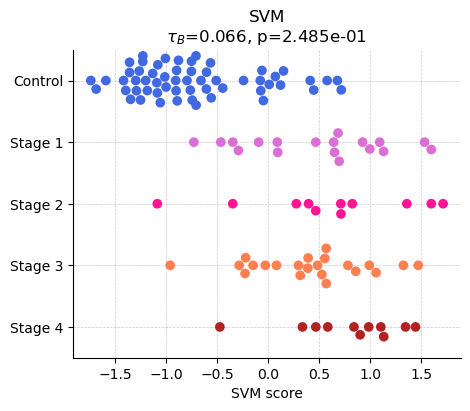

Kendall's tau for carsvm: SignificanceResult(statistic=0.10766984335321837, pvalue=0.13332490782205353)


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 8.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


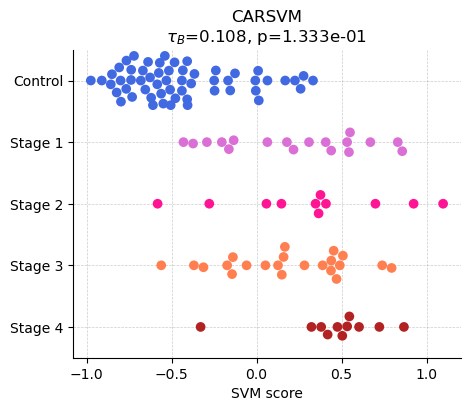

Kendall's tau for stage-svm: SignificanceResult(statistic=0.10890035584868371, pvalue=0.13061138288586482)


C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 12.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\antoi\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 17.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


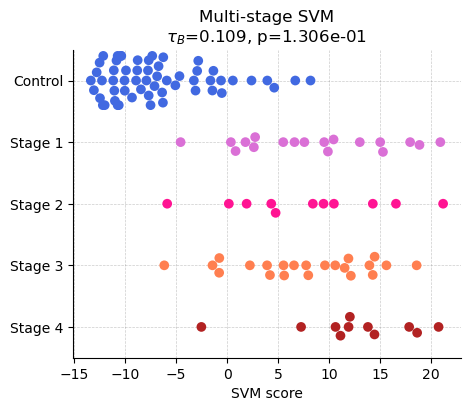

In [72]:
for method_name, pretty_name in [("svm-reimpl", "SVM"), ("carsvm", "CARSVM"), ("stage-svm", "Multi-stage SVM")]:
    
    plt.figure(figsize=(5, 4))
    ax = plt.subplot(1, 1, 1)
    
    with open(os.path.join(PREDICTIONS_PATH, "colca", f"{method_name}.json"), 'r') as f:
        data = json.load(f)
        auroc = data['auroc']
        aupr = data['aupr']
        y = np.array(data['y'], dtype=int)
        y_pred = np.array(data['y-pred'])
    
    xs, ys, zs = [], [], []
    for annot, y_pred in zip(dataset_test.annotations, y_pred):
        #y_pred = y_pred[1]
        grade = float(annot)
        if not annot.is_cancer:
            ys.append('Control')
            xs.append(y_pred)
            zs.append(0)
        else:
            if np.isnan(grade):
                continue
            else:
                ys.append(f'Stage {int(grade)}')
                xs.append(y_pred)
                zs.append(int(grade) + 1)
    xs = np.array(xs)
    ys = np.array(ys)
    zs = np.array(zs)
        
    print(f'Kendall\'s tau for {method_name}: {scipy.stats.kendalltau(xs[y == 1], zs[y == 1], alternative="greater")}')
    
    df = pd.DataFrame({
        'stage': ys,
        'score': scipy.special.logit(xs)
    })
    
    seaborn.swarmplot(
        ax=ax, data=df, x='score', y='stage', hue='stage', size=7,
        order=['Control', 'Stage 1', 'Stage 2', 'Stage 3', 'Stage 4'],
        palette={'Control': 'royalblue', 'Stage 1': 'orchid', 'Stage 2': 'deeppink', 'Stage 3': 'coral', 'Stage 4': 'firebrick'}
    )
    ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    ax.set_ylabel('')
    ax.set_xlabel('SVM score')
    res = scipy.stats.kendalltau(xs[y == 1], zs[y == 1], alternative="greater")
    ax.set_title(f'{pretty_name}\n' + r'$\tau_B$=' + f'{res.statistic:.3f}, p={res.pvalue:.3e}')
    plt.savefig(os.path.join(FIGURES_PATH, f'stage-pred-{method_name}.png'), dpi=300)
    plt.show()